In [1]:
import xarray as xr
import pandas as pd
import numpy as np
import os, glob, re, string, io, warnings
import seaborn as sns
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
from osgeo import gdal
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.dates import YearLocator, DateFormatter
from matplotlib.patches import Rectangle, ConnectionPatch
import matplotlib.colors as mcolors
from matplotlib.gridspec import GridSpec
import matplotlib.patches as mpatches
from scipy.stats import pearsonr, linregress, norm
from scipy.optimize import curve_fit
from pathlib import Path
import warnings
from scipy.stats import t as student_t

MACHDIR = os.path.expanduser("~")
os.environ["HDF5_USE_FILE_LOCKING"] = "FALSE"
sns.set(rc={"ytick.left": True, "xtick.bottom": True}, style="white", font_scale=2)
filepath = "/Users/sworden/Documents"

def _ensure_latlon(da):
    if not isinstance(da, xr.DataArray):
        return da
    rename = {}
    if "latitude" in da.dims:
        rename["latitude"] = "lat"
    if "longitude" in da.dims:
        rename["longitude"] = "lon"
    return da.rename(rename) if rename else da

def _drop_time_if_present(da):
    return da.isel(time=0, drop=True) if isinstance(da, xr.DataArray) and "time" in da.dims else da

def mean_std_n(arr):
    arr = np.asarray(arr, float)
    m = np.isfinite(arr)
    return (float(np.nanmean(arr[m])), float(np.nanstd(arr[m])), int(m.sum())) if m.any() else (np.nan, np.nan, 0)

def sel_range(da, dim, a, b):
    c = da[dim]
    return da.sel({dim: slice(a, b) if c[0] < c[-1] else slice(b, a)})

def gdal_latlon(ds):
    gt = ds.GetGeoTransform()
    nx, ny = ds.RasterXSize, ds.RasterYSize
    lons = np.linspace(gt[0], gt[0] + nx * gt[1], nx)
    lats = np.linspace(gt[3], gt[3] + ny * gt[5], ny)
    return lats, lons


## Load Data

In [2]:
file='/Users/sworden/Documents/YanWBET/ET_3mean_corrected_v3d_10km_2002_2018.tif'

tif=gdal.Open(file)
lats, lons = gdal_latlon(tif)

WBET=np.load('/Users/sworden/Documents/TRVISlopes/WBET20022018Global.npy')
time=pd.date_range('2002-01-01','2018-12-01',freq='MS')
WBET=xr.DataArray(WBET,coords=[time,lats,lons],dims=['time','lat','lon'])
WBET=WBET.sel(lat=slice(15,-20),lon=slice(0,50),time=slice('2003','2017'))[:,::-1,:] 


In [3]:
#SIF
directory_path = '/Users/sworden/Documents/SIFCombined/'
files = os.listdir(directory_path)
def extract_year(filename):
    return int(filename.split('.')[2])
#sort file paths by time
sorted_file_paths = sorted([os.path.join(directory_path, file) for file in files],
                           key=extract_year)
#open datasets individually and concatenate (done to make sure files are ordered properly)
datasets = [xr.open_dataset(file_path).sel(latitude=slice(15,-20),longitude=slice(0,50)) for file_path in sorted_file_paths]
concatenated_data = xr.concat(datasets, dim='time')  # replace 'time' with the actual dimension
SIF=concatenated_data.LT_SIFc
SIF['time']= pd.date_range('1995-07-01','2018-12-01',freq='MS')
SIF = SIF.where(SIF>0)
SIFNew = SIF.rename({'latitude':'lat','longitude':'lon'})
SIFNew = SIFNew.transpose('time','lat','lon')
SIFNew = SIFNew[:,::-1,:]
SIFNew = SIFNew.sel(time=slice('2002','2018'))
#interpolate SIF so it matches the water balance ET lat and lon
SIFFin=SIFNew.interp(lat=WBET.lat,lon=WBET.lon,method='nearest')

In [4]:
# Load ET + GPP once on the largest domain used in the notebook
MASTER_LAT = (-25, 15)
MASTER_LON = (-10, 50)
YEARS = range(1982, 2023)

AETMaster = xr.open_mfdataset(
    filepath + '/v3.8a/monthly/E/*', concat_dim='time', combine='nested'
).E
AETMaster = sel_range(sel_range(AETMaster, 'lat', *MASTER_LAT), 'lon', *MASTER_LON)
AETMaster = AETMaster.sel(time=slice('1982', '2022')).sortby('lat')

# GPP files contain 12 monthly layers per year; give them a real monthly time axis
_gpp_years = []
for year in YEARS:
    with xr.open_dataset(f'{filepath}/GPPGIMS4/GPP_MERRA2_FPAR4g_Monthly_{year}.nc') as ds:
        gpp = _ensure_latlon(ds.GPP)
        gpp = sel_range(sel_range(gpp, 'lat', *MASTER_LAT), 'lon', *MASTER_LON)
        non_spatial = [d for d in gpp.dims if d not in ('lat', 'lon')]
        if len(non_spatial) != 1:
            raise ValueError(f'Expected one monthly GPP dimension, found {non_spatial}')
        month_dim = non_spatial[0]
        gpp = gpp.transpose(month_dim, 'lat', 'lon').load()
        if gpp.sizes[month_dim] != 12:
            raise ValueError(f'{year} GPP file has {gpp.sizes[month_dim]} months, expected 12')
        if month_dim != 'time':
            gpp = gpp.rename({month_dim: 'time'})
        gpp = gpp.assign_coords(time=pd.date_range(f'{year}-01-01', periods=12, freq='MS'))
        _gpp_years.append(gpp)

GPPMasterRaw = xr.concat(_gpp_years, dim='time').sortby('lat')
del _gpp_years

if GPPMasterRaw.sizes['time'] != AETMaster.sizes['time']:
    raise ValueError(
        f"GPP has {GPPMasterRaw.sizes['time']} months but ET has {AETMaster.sizes['time']} months."
    )

# Put GPP on the ET grid once
GPPMaster = GPPMasterRaw.interp(lat=AETMaster.lat, lon=AETMaster.lon, method='nearest')
GPPMaster = GPPMaster.assign_coords(time=AETMaster.time)

# Main Congo domain used by most figures
AET = sel_range(sel_range(AETMaster, 'lat', -20, 15), 'lon', 0, 50)
GPPNew = sel_range(sel_range(GPPMaster, 'lat', -20, 15), 'lon', 0, 50)
GPPFinArr = sel_range(sel_range(GPPMasterRaw, 'lat', -20, 15), 'lon', 0, 50)

# Correlation map needed at both the Congo and flux-tower domains
TestCorrMaster = xr.corr(GPPMaster, AETMaster, dim='time').compute()
TestCorr = sel_range(sel_range(TestCorrMaster, 'lat', -20, 15), 'lon', 0, 50)


C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\array\numpy_compat.py:53: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\core.py:127: RuntimeWarning: invalid value encountered in divide
  return func(*(_execute_task(a, cache) for a in args))


In [5]:
#Calculate ERA5 VPD
##open 2m temperature
ds=xr.open_dataset('/Users/sworden/Downloads/data_0.nc')

#Load dewpoint temperature
TdArr=ds.d2m.sel(latitude=slice(15,-20),longitude=slice(0,50))[:,:,:]-273.15 ##select lat bounds and convert to celsius
#Load actual temperature
TArr=ds.t2m.sel(latitude=slice(15,-20),longitude=slice(0,50))[:,:,:]-273.15 ##select lat bounds and convert to celsius
# Calculate saturation vapor pressure
es = 6.11 * np.exp((17.27 * TArr) / (TArr + 237.3))

# Calculate actual vapor pressure
ea = 6.11 * np.exp((17.27 * TdArr) / (TdArr + 237.3))

# Calculate vapor pressure deficit
VPD = np.array(es) -ea
#Rename coordinates
VPDArr=VPD.rename({'latitude':'lat','longitude':'lon','date': 'time'})
VPDArr['time']=pd.date_range('1982-01-01','2024-09-01',freq='MS')
VPDArr = VPDArr.sel(time=slice('1982','2022'))
VPDArr = VPDArr.interp(lat=AET.lat, lon=AET.lon,method='linear')
TArr=TArr.rename({'latitude':'lat','longitude':'lon','date': 'time'})
TArr['time']=pd.date_range('1982-01-01','2024-09-01',freq='MS')
TArr = TArr.sel(time=slice('1982','2022'))
TArr = TArr.interp(lat=AET.lat, lon=AET.lon,method='linear')

In [6]:
##Calculate AIRS VPD
ds=xr.open_mfdataset(filepath+'/AIRSVPDData/*',concat_dim='time', combine='nested') 
SurfTemp=(ds.SurfAirTemp_A+ds.SurfAirTemp_D)/2
SurfRH = (ds.RelHumSurf_A+ds.RelHumSurf_D)/2
SurfTemp = SurfTemp-273.15 #convert to celsius


SurfTempAlt=(ds.SurfAirTemp_TqJ_A+ds.SurfAirTemp_TqJ_D)/2
SurfRHAlt = (ds.RelHumSurf_TqJ_A+ds.RelHumSurf_TqJ_D)/2
SurfTempAlt = SurfTempAlt-273.15 #convert to celsius
#from Barkhordian et al. (2019)
a1=243.04
a2=17.625
TdUpper=a1*(np.log(SurfRHAlt/100)+(a2*SurfTempAlt/(a1+SurfTempAlt)))
TdLower=a2-(np.log(SurfRHAlt/100)+(a2*SurfTempAlt/(a1+SurfTempAlt)))
Td=TdUpper/TdLower

# Calculate saturation vapor pressure
es = 6.11 * np.exp((17.27 * SurfTempAlt) / (SurfTempAlt + 237.3))

# Calculate actual vapor pressure
ea = 6.11 * np.exp((17.27 * Td) / (Td + 237.3))

# Calculate vapor pressure deficit
VPD = np.array(es) -ea
VPD = VPD.sel(Latitude=slice(15,-20),Longitude=slice(0,50))
VPD=VPD.rename({'Latitude':'lat','Longitude':'lon'})
VPD['time']=pd.date_range('2002-09-01','2022-12-01',freq='MS')
VPDAIRS=np.array(VPD)
VPDArrAIRS=xr.DataArray(VPDAIRS,coords=[VPD.time,VPD.lat,VPD.lon],dims=['time','lat','lon'])

## Figure 1

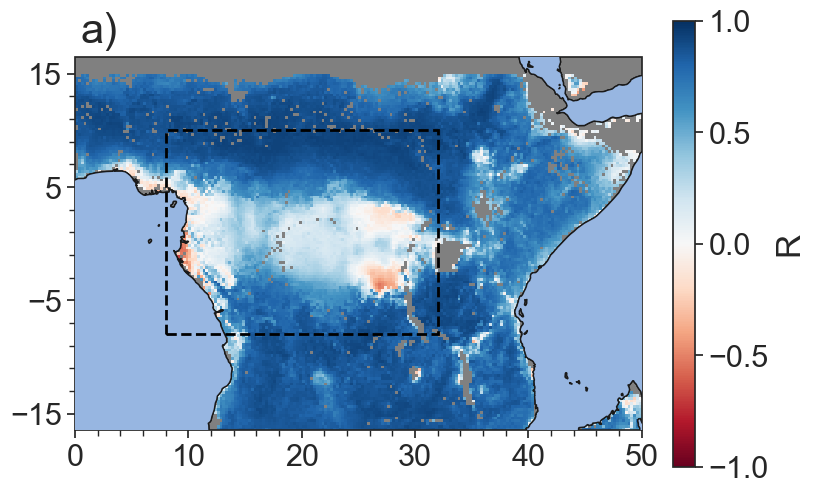

In [7]:
def plot_corr_map(data, panel, outfile):
    rect = Rectangle((8, -8), 24, 18, lw=2, edgecolor="black", facecolor="none",
                     ls="--", transform=ccrs.PlateCarree(), zorder=200)
    fig, ax = plt.subplots(figsize=(8, 6), subplot_kw={"projection": ccrs.PlateCarree()})
    im = ax.pcolormesh(data.lon, data.lat, data, transform=ccrs.PlateCarree(),
                       vmin=-1, vmax=1, cmap="RdBu")
    ax.set_facecolor("grey")
    ax.coastlines()
    ax.add_patch(rect)
    ax.add_feature(cfeature.OCEAN, zorder=100, edgecolor="k")
    ax.set_extent([0, 50, -15, 15])
    ax.set_xticks([0, 10, 20, 30, 40, 50], crs=ccrs.PlateCarree())
    ax.set_yticks([-15, -5, 5, 15], crs=ccrs.PlateCarree())
    ax.text(.01, 1.04, panel, fontsize=30, transform=ax.transAxes)
    cbar = fig.colorbar(im, ax=ax, fraction=0.036, pad=0.05)
    cbar.set_label("R")
    ax.minorticks_on()
    fig.savefig(outfile, bbox_inches="tight")
    plt.show()

plot_corr_map(
    TestCorr, "a)",
    "/Users/sworden/Documents/EqAfricaGPPETResults/Figure1b9.9.png"
)


In [8]:
corr = xr.corr(SIFFin,WBET,dim='time')

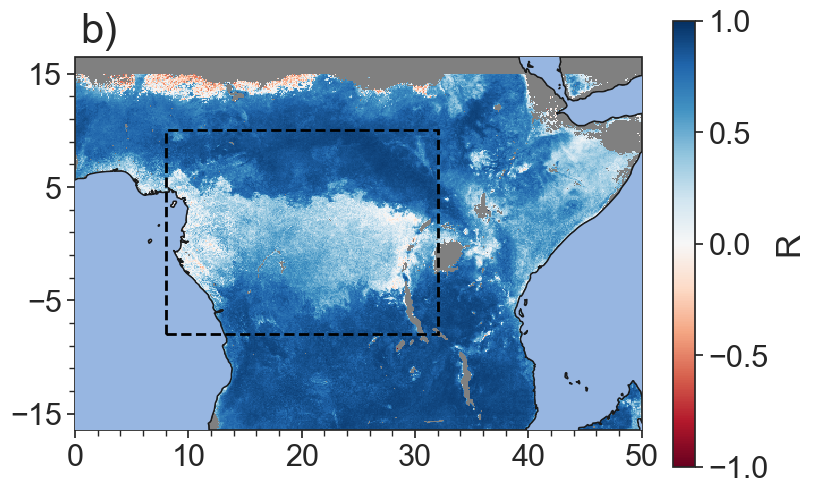

In [9]:
plot_corr_map(
    corr, "b)",
    "/Users/sworden/Documents/EqAfricaGPPETResults/WBETJPLSIFCorrelations12.5.png"
)


#### Supplementary Figure S2

  Site      Years        Lat        Lon                  Vegetation  \
0  Mon  2008–2009 -15.437000  23.252000             Miombo woodland   
1  Tch  2006–2009  -4.289200  11.656400                     Savanna   
2  Ank  2011–2014   5.268500  -2.694200  Evergreen broadleaf forest   
3  Bfg  2008–2017   9.791000   1.718000  Deciduous broadleaf forest   
4  Db1  2022–2024   6.607338   2.543043                   Croplands   
5  Mkt  2019–2024  -3.425859  38.140663                   Croplands   
6  Chk  2022–2024  -3.666300  38.350185               Woody savanna   

        MAP_mm         R             p   n  
0   582.242300  0.965698  8.654138e-11  18  
1  1650.896250  0.866207  1.273746e-13  42  
2  1904.684750  0.400896  1.538888e-02  36  
3  1342.177600  0.372863  2.325065e-04  93  
4  1263.109000  0.541322  1.141461e-03  33  
5   284.975167  0.754192  1.935293e-11  56  
6   391.620333  0.767747  7.475168e-06  25  


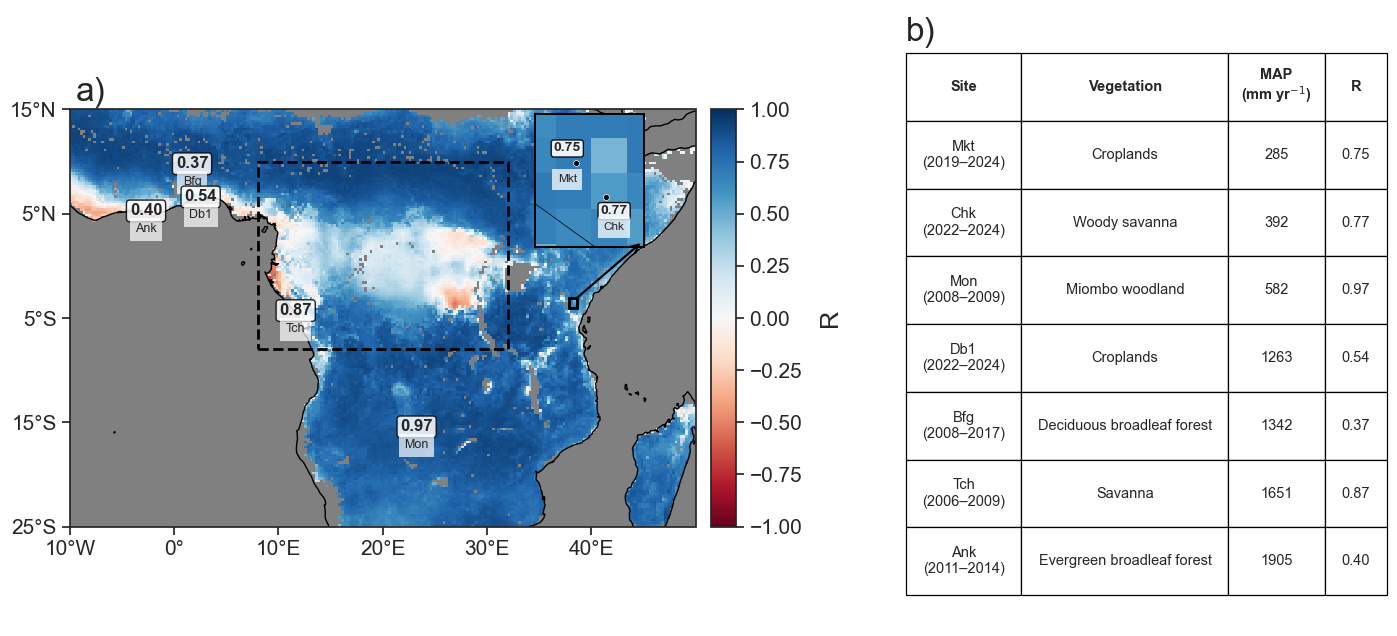

In [10]:
# FLUXNET helpers
def read_fluxnet(file):
    df = pd.read_csv(file, low_memory=False).replace(-9999, np.nan)

    if 'TIMESTAMP_START' in df.columns:
        df['time'] = pd.to_datetime(
            df['TIMESTAMP_START'].astype(str),
            format='%Y%m%d%H%M'
        )
        resolution = 'subdaily'

    elif 'TIMESTAMP' in df.columns:
        df['time'] = pd.to_datetime(
            df['TIMESTAMP'].astype(str),
            format='%Y%m'
        )
        resolution = 'monthly'

    else:
        raise ValueError("Need TIMESTAMP_START or TIMESTAMP.")

    return df.sort_values('time').set_index('time'), resolution

def year_range(df):
    if df.empty:
        return 'NA'

    y0 = df.index.min().year
    y1 = df.index.max().year
    return str(y0) if y0 == y1 else f'{y0}–{y1}'

def calc_site_stats(site):
    df, resolution = read_fluxnet(site['file'])

    # GPP-ET correlation
    corr_df = df.loc[site['start_date']:] if site.get('start_date') else df
    corr_df = corr_df[['GPP_DT_VUT_REF', 'LE_F_MDS']].apply(
        pd.to_numeric, errors='coerce'
    )

    if resolution == 'subdaily':
        corr_df = corr_df.resample('MS').mean()

    corr_df = corr_df.dropna()

    if len(corr_df) >= 3:
        # LE -> ET conversion is unnecessary for Pearson R:
        # multiplying LE by a positive constant does not change correlation
        R, p = pearsonr(corr_df['GPP_DT_VUT_REF'], corr_df['LE_F_MDS'])
    else:
        R, p = np.nan, np.nan

    # Mean annual precipitation from full tower record
    if 'P_F' not in df.columns:
        raise ValueError("P_F not found.")

    precip = pd.to_numeric(df['P_F'], errors='coerce')
    precip = precip.where(precip >= 0)

    if resolution == 'subdaily':
        monthly_p = precip.resample('MS').sum(min_count=1)
    else:
        monthly_p = precip * precip.index.days_in_month

    annual_p = monthly_p.resample('YS').sum(min_count=1)

    # Keep only complete calendar years
    complete = monthly_p.notna().resample('YS').sum() == 12
    annual_p = annual_p[complete].dropna()

    MAP = annual_p.mean() if len(annual_p) else np.nan

    return R, p, len(corr_df), year_range(corr_df), MAP

# Sites
sites = [
    dict(
        name='Mon',
        file='/Users/sworden/Downloads/FLX_ZM-Mon_FLUXNET2015_FULLSET_MM_2000-2009_2-4.csv',
        lat=-15.437, lon=23.252, veg='Miombo woodland',
        start_date='2008-07-01'
    ),
    dict(
        name='Tch',
        file='/Users/sworden/Downloads/EUF_CG-Tch_FLUXNET_FLUXMET_HH_2006-2009_v1.3_r1.csv',
        lat=-4.2892, lon=11.6564, veg='Savanna',
        start_date=None
    ),
    dict(
        name='Ank',
        file='/Users/sworden/Downloads/EUF_GH-Ank_FLUXNET_FLUXMET_HH_2011-2014_v1.3_r1.csv',
        lat=5.2685, lon=-2.6942, veg='Evergreen broadleaf forest',
        start_date=None
    ),
    dict(
        name='Bfg',
        file='/Users/sworden/Downloads/FLX_BJ-Bfg_FLUXNET_FLUXMET_HH_2008-2017_v1.3_r1.csv',
        lat=9.791, lon=1.718, veg='Deciduous broadleaf forest',
        start_date=None
    ),
    dict(
        name='Db1',
        file='/Users/sworden/Downloads/FLX_BJ-Db1_FLUXNET_FLUXMET_HH_2022-2024_v1.3_r1.csv',
        lat=6.607338, lon=2.543043, veg='Croplands',
        start_date=None
    ),
    dict(
        name='Mkt',
        file='/Users/sworden/Downloads/FLX_KE-Mkt_FLUXNET_FLUXMET_HH_2019-2024_v1.3_r1.csv',
        lat=-3.425859, lon=38.140663, veg='Croplands',
        start_date=None
    ),
    dict(
        name='Chk',
        file='/Users/sworden/Downloads/FLX_KE-Chk_FLUXNET_FLUXMET_HH_2022-2024_v1.3_r1.csv',
        lat=-3.666300, lon=38.350185, veg='Woody savanna',
        start_date=None
    ),
]

# Calculate tower statistics
rows = []

for site in sites:
    try:
        R, p, n, years, MAP = calc_site_stats(site)

    except Exception as e:
        print(f"Problem with {site['name']}: {e}")
        R, p, n, years, MAP = np.nan, np.nan, 0, 'NA', np.nan

    rows.append({
        'Site': site['name'],
        'Years': years,
        'Lat': site['lat'],
        'Lon': site['lon'],
        'Vegetation': site['veg'],
        'MAP_mm': MAP,
        'R': R,
        'p': p,
        'n': n
    })

site_df = pd.DataFrame(rows)
print(site_df)

# Figure
fig = plt.figure(figsize=(17, 8))
gs = fig.add_gridspec(1, 2, width_ratios=[1.30, 1], wspace=0.38)

ax = fig.add_subplot(gs[0, 0], projection=ccrs.PlateCarree())
ax_table = fig.add_subplot(gs[0, 1])

# a) Correlation map
cmap = plt.get_cmap('RdBu').copy()
cmap.set_bad('gray')

im = ax.pcolormesh(
    GPPMaster.lon, GPPMaster.lat, TestCorrMaster,
    vmin=-1, vmax=1, cmap=cmap,
    transform=ccrs.PlateCarree()
)

ax.set_facecolor('grey')
ax.coastlines()
ax.add_feature(cfeature.OCEAN, edgecolor='k')

ax.add_patch(Rectangle(
    (8, -8), 24, 18,
    fill=False, edgecolor='black', lw=2, ls='--',
    transform=ccrs.PlateCarree(), zorder=200
))

cax = inset_axes(
    ax, width='4%', height='100%', loc='lower left',
    bbox_to_anchor=(1.025, 0, 1, 1),
    bbox_transform=ax.transAxes, borderpad=0
)

cbar = fig.colorbar(im, cax=cax)
cbar.set_label('R', fontsize=18, labelpad=12)
cbar.ax.tick_params(labelsize=15)

ax.text(0.01, 1.02, 'a)', fontsize=24, transform=ax.transAxes)

ax.set_xticks([-10, 0, 10, 20, 30, 40], crs=ccrs.PlateCarree())
ax.set_yticks([-25, -15, -5, 5, 15], crs=ccrs.PlateCarree())
ax.xaxis.set_major_formatter(LongitudeFormatter())
ax.yaxis.set_major_formatter(LatitudeFormatter())
ax.tick_params(axis='both', labelsize=15)

# Tower labels, excluding Kenya pair
zoom_sites = {'Mkt', 'Chk'}

for _, row in site_df.iterrows():
    if not np.isfinite(row['R']) or row['Site'] in zoom_sites:
        continue

    ax.text(
        row['Lon'], row['Lat'], f"{row['R']:.2f}",
        transform=ccrs.PlateCarree(),
        fontsize=12, fontweight='bold',
        ha='center', va='center', zorder=300,
        bbox=dict(
            facecolor='white', edgecolor='black',
            boxstyle='round,pad=0.2', alpha=0.85
        )
    )

    ax.text(
        row['Lon'], row['Lat'] - 1.2, row['Site'],
        transform=ccrs.PlateCarree(),
        fontsize=9, ha='center', va='top', zorder=300,
        bbox=dict(facecolor='white', edgecolor='none', alpha=0.7)
    )

# Kenya zoom
zoom_lon = (37.85, 38.62)
zoom_lat = (-4.02, -3.08)

ax.add_patch(Rectangle(
    (zoom_lon[0], zoom_lat[0]),
    zoom_lon[1] - zoom_lon[0],
    zoom_lat[1] - zoom_lat[0],
    fill=False, edgecolor='black', lw=2,
    transform=ccrs.PlateCarree(), zorder=350
))

axins = ax.inset_axes(
    [0.67, 0.67, 0.32, 0.32],
    projection=ccrs.PlateCarree()
)

axins.set_extent(
    [zoom_lon[0], zoom_lon[1], zoom_lat[0], zoom_lat[1]],
    crs=ccrs.PlateCarree()
)

# FIX: use same map as main panel
axins.pcolormesh(
    GPPMaster.lon, GPPMaster.lat, TestCorrMaster,
    vmin=-1, vmax=1, cmap=cmap,
    transform=ccrs.PlateCarree()
)

axins.set_facecolor('grey')
axins.coastlines(linewidth=0.5)
axins.add_feature(cfeature.BORDERS, linewidth=0.5)
axins.set_xticks([])
axins.set_yticks([])

for spine in axins.spines.values():
    spine.set_linewidth(1.4)
    spine.set_edgecolor('black')

kenya_offsets = {
    'Mkt': (-0.06,  0.10, -0.06, -0.08),
    'Chk': ( 0.06, -0.10,  0.06, -0.18),
}

for _, row in site_df[site_df['Site'].isin(zoom_sites)].iterrows():
    if not np.isfinite(row['R']):
        continue

    dx_R, dy_R, dx_site, dy_site = kenya_offsets[row['Site']]

    axins.scatter(
        row['Lon'], row['Lat'],
        s=18, color='black', edgecolor='white', linewidth=0.5,
        transform=ccrs.PlateCarree(), zorder=450
    )

    axins.text(
        row['Lon'] + dx_R, row['Lat'] + dy_R, f"{row['R']:.2f}",
        transform=ccrs.PlateCarree(),
        fontsize=10, fontweight='bold',
        ha='center', va='center', zorder=500,
        bbox=dict(
            facecolor='white', edgecolor='black',
            boxstyle='round,pad=0.18', alpha=0.9
        )
    )

    axins.text(
        row['Lon'] + dx_site, row['Lat'] + dy_site, row['Site'],
        transform=ccrs.PlateCarree(),
        fontsize=8.5, ha='center', va='top', zorder=500,
        bbox=dict(facecolor='white', edgecolor='none', alpha=0.75)
    )

fig.add_artist(ConnectionPatch(
    xyA=(zoom_lon[1], zoom_lat[1]),
    coordsA=ax.transData,
    xyB=(0.97, 0.03),
    coordsB=axins.transAxes,
    arrowstyle='->',
    lw=1.6, color='black',
    mutation_scale=14,
    clip_on=False, zorder=600
))

# b) Flux tower table
ax_table.axis('off')
ax_table.text(0, 0.95, 'b)', fontsize=24, transform=ax_table.transAxes)

table_df = (
    site_df[['Site', 'Years', 'Vegetation', 'MAP_mm', 'R']]
    .sort_values('MAP_mm')
    .reset_index(drop=True)
)

table_df['Site'] = table_df['Site'] + '\n(' + table_df['Years'] + ')'
table_df['MAP_mm'] = table_df['MAP_mm'].map(
    lambda x: f'{x:.0f}' if np.isfinite(x) else 'nan'
)
table_df['R'] = table_df['R'].map(
    lambda x: f'{x:.2f}' if np.isfinite(x) else 'nan'
)

table_df = table_df[['Site', 'Vegetation', 'MAP_mm', 'R']]
table_df.columns = ['Site', 'Vegetation', 'MAP\n(mm yr$^{-1}$)', 'R']

table = ax_table.table(
    cellText=table_df.values,
    colLabels=table_df.columns,
    cellLoc='center', colLoc='center',
    bbox=[0, 0.05, 1, 0.88]
)

table.auto_set_font_size(False)
table.set_fontsize(10.5)

col_widths = [0.24, 0.43, 0.20, 0.13]

for (r, c), cell in table.get_celld().items():
    cell.set_width(col_widths[c])
    cell.set_edgecolor('black')
    cell.set_linewidth(0.9)
    cell.set_facecolor('white')
    cell.set_text_props(
        weight='bold' if r == 0 else 'normal',
        ha='center', va='center'
    )

table.scale(1, 1.12)

# Save
plt.savefig(
    '/Users/sworden/Documents/EqAfricaGPPETResults/SupplementaryFigure2.png',
    dpi=300, bbox_inches='tight'
)

plt.show()


## Figure 2

In [11]:
# Inputs
ds = xr.open_dataset('/Users/sworden/Documents/MODISLandCover/2022LCMODISAfrica.nc')
LC = ds.LC_Prop1.isel(time=0)
forest_codes = {11, 12, 13, 14, 15, 16}#, 21 22}
nodata_code  = 255

lat_target = xr.DataArray(np.arange(-19.875, 14.875 + 1e-12, 0.25), dims=("lat",))
lon_target = xr.DataArray(np.arange(0.125, 49.875 + 1e-12, 0.25), dims=("lon",))

# Forest boolean (mask nodata)
is_forest = xr.zeros_like(LC, dtype=bool)
for c in forest_codes:
    is_forest = is_forest | (LC == c)
is_forest = is_forest.where(LC != nodata_code)

#Build edges from centers ± 0.125°, pad with a tiny epsilon
step, half, eps = 0.25, 0.125, 1e-9
lat_edges = np.arange(float(lat_target.min()) - half - eps,
                      float(lat_target.max()) + half + eps, step)
lon_edges = np.arange(float(lon_target.min()) - half - eps,
                      float(lon_target.max()) + half + eps, step)

# Digitize LC coordinates to coarse bins
lat_idx = np.digitize(LC.lat.values, lat_edges)  # 1..(n_bins+1) possible at the far right
lon_idx = np.digitize(LC.lon.values, lon_edges)

# Clamp indices to valid bin range (1..n_bins)
nlat_bins = len(lat_edges) - 1
nlon_bins = len(lon_edges) - 1
lat_idx = np.clip(lat_idx, 1, nlat_bins)
lon_idx = np.clip(lon_idx, 1, nlon_bins)

# Flat table per pixel
nlat, nlon = LC.shape
df = pd.DataFrame({
    "lat_bin": np.repeat(lat_idx, nlon),
    "lon_bin": np.tile(lon_idx, nlat),
    "forest":  is_forest.values.ravel().astype(float)
})
df = df[np.isfinite(df["forest"])]

# Aggregate (pixel-count mean = forest fraction)
frac = (df.groupby(["lat_bin", "lon_bin"])["forest"]
          .mean()
          .rename("forest_frac")
          .reset_index())

lat_centers = lat_target.values[frac["lat_bin"].to_numpy() - 1]
lon_centers = lon_target.values[frac["lon_bin"].to_numpy() - 1]

# Assemble to 2D DA on exact target grid
da_points = xr.DataArray(
    frac["forest_frac"].to_numpy(),
    dims=("points",),
    coords={"points": np.arange(len(frac)),
            "lat": ("points", lat_centers),
            "lon": ("points", lon_centers)},
    name="forest_frac"
)
forest_frac_025 = (da_points
                   .set_index(points=["lat", "lon"])
                   .unstack("points")
                   .reindex(lat=lat_target, lon=lon_target))

# Forest mask (≥ 80%)
forest_mask_025 = (forest_frac_025 >= 0.80)

#### Supplementary Figure 1

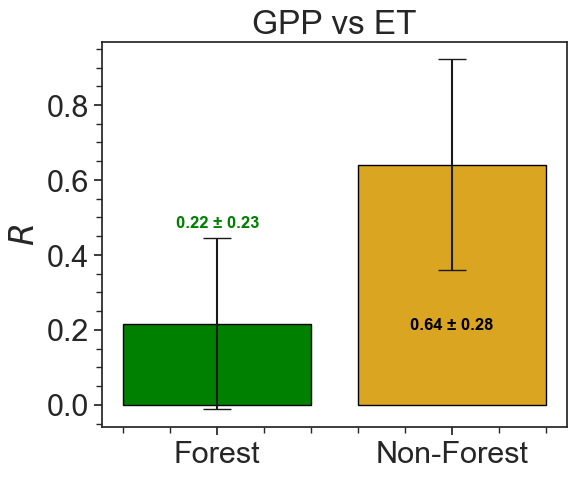

In [12]:
TestCorrFin=TestCorr.sel(lat=slice(-8,8),lon=slice(8,32))
mask=forest_mask_025.sel(lat=slice(-8,8),lon=slice(8,32))
TestCorrFor = TestCorrFin.where(forest_mask_025 == True)
TestCorrNoFor = TestCorrFin.where(forest_mask_025 == False)

Corrs = np.array([np.nanmean(TestCorrFor), np.nanmean(TestCorrNoFor)])
CorrsStd = np.array([np.nanstd(TestCorrFor), np.nanstd(TestCorrNoFor)])

labels = ['Forest', 'Non-Forest']

#Bar plot with error bars
fig, ax = plt.subplots(figsize=(6, 5))
bars = ax.bar(labels, Corrs, yerr=CorrsStd, capsize=10,
              color=['green', 'goldenrod'], edgecolor='black')

ax.set_ylabel('$R$')
ax.set_title('GPP vs ET')
plt.minorticks_on()

#Annotate each bar
for bar, mean, std, label in zip(bars, Corrs, CorrsStd, labels):
    height = bar.get_height()
    xpos = bar.get_x() + bar.get_width() / 2

    if label == "Forest":
        # Text above bar
        ax.text(xpos, height + std + 0.02,
                f"{mean:.2f} ± {std:.2f}",
                ha="center", va="bottom",
                fontsize=12, fontweight='bold',
                color="green")
    else:
        # Text inside the bar, near the top
        ax.text(xpos, height - (0.7 * height),  # 5% below top
                f"{mean:.2f} ± {std:.2f}",
                ha="center", va="bottom",
                fontsize=12, fontweight='bold',
                color="black")

plt.savefig('/Users/sworden/Documents/EqAfricaGPPETResults/SupplementaryFigure1.png',
            format='png', bbox_inches='tight')
plt.show()


Observations: GPP 64 x 88; ET 64 x 88
Observations Forest: classified=2106, jointly valid/month=2092-2092
Observations Non-forest: classified=3526, jointly valid/month=2937-2937
Observations GPP: 'gC/m2/day' -> g C m-2 day-1 (rate)
Observations ET: 'mm.month-1' -> mm day-1 (permonth)
Observations       forest R=0.257; nonforest R=0.587
CABLE-POP: full native ET grid 180 x 360
CABLE-POP: selected grid 16 x 24 = 384 cells; lat -7.500..7.500; lon 8.500..31.500
CABLE-POP: 384 native model cells have valid MODIS classification; 0 are unclassified
CABLE-POP Forest: classified=118, jointly valid/month=118–118
CABLE-POP Non-forest: classified=266, jointly valid/month=231–231
CABLE-POP GPP: 'kg m-2 s-1' -> g C m-2 day-1 (rate)
CABLE-POP ET: 'kg m-2 s-1' -> mm day-1 (rate)
CABLE-POP          forest R=-0.334; nonforest R=-0.452
CARDAMOM: full native ET grid 180 x 360
CARDAMOM: selected grid 16 x 24 = 384 cells; lat -7.500..7.500; lon 8.500..31.500
CARDAMOM: 384 native model cells have valid MODIS

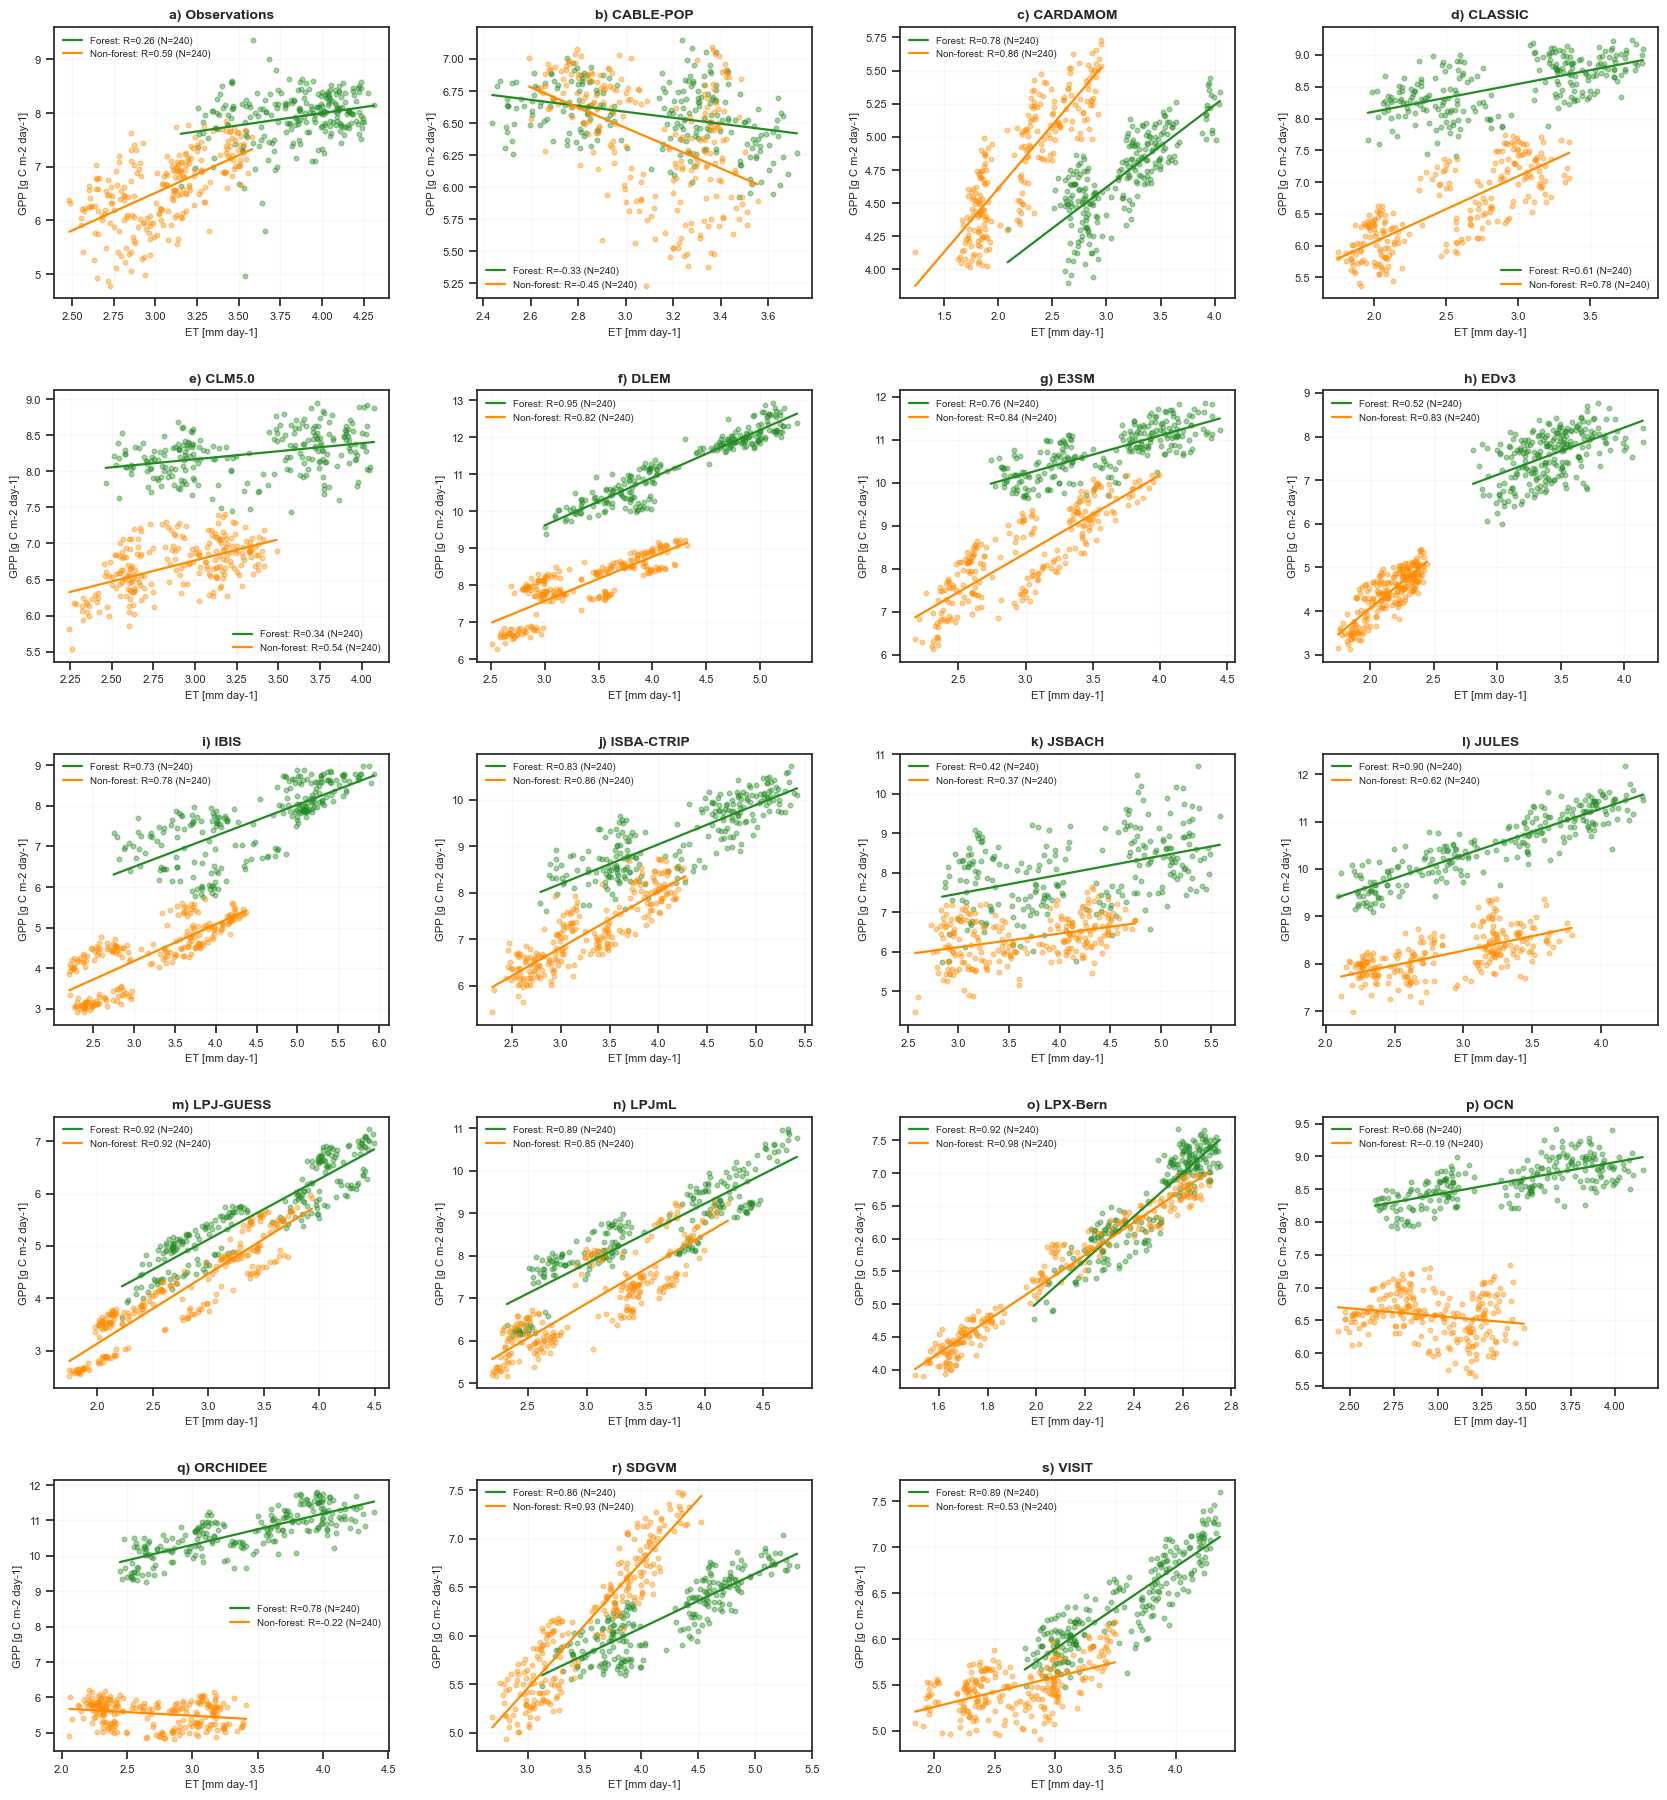

Saved outputs in: C:\Users\sworden\Documents\TRENDY\congo_scatter_results
All axes: GPP = g C m-2 day-1; ET = mm day-1
NOTE: CARDAMOM calendar mapping remains provisional, as in source script


In [13]:
TRENDY_ROOT = Path(r"C:\Users\sworden\Documents\TRENDY")
OBS_ROOT = Path(r"C:\Users\sworden\Documents")  
OUT_DIR = TRENDY_ROOT / "congo_scatter_results"
# Raw MODIS native-resolution classification
MODIS_FILE = Path(r"C:\Users\sworden\Documents\MODISLandCover\2022LCMODISAfrica.nc")
MODIS_FOREST_CODES = (11, 12, 13, 14, 15, 16)
MODIS_NODATA = 255
LAT_MIN, LAT_MAX = -8.0, 8.0
LON_MIN, LON_MAX = 8.0, 32.0
START, END = "2003-01", "2022-12"
MONTHS = pd.period_range(START, END, freq="M")



def coord_name(da, candidates):
    for name in candidates:
        if name in da.coords and da[name].ndim == 1 and name in da.dims:
            return name
    raise ValueError(f"No supported coordinate among {candidates}; found {list(da.coords)}")


def prepare_spatial_coordinates(da):
    """Make 1-D geographic coordinates into dimension coordinates.

    E3SM provides auxiliary latitude/longitude coordinates whose dimension
    names may differ. Preserve their values and data order using swap_dims.
    Refuse 2-D curvilinear grids rather than assume a rectilinear layout.
    """
    for candidates in (("lat", "latitude", "lat_FULL", "LAT", "nav_lat"),
                       ("lon", "longitude", "lon_FULL", "LON", "nav_lon")):
        found = [n for n in candidates if n in da.coords and da[n].ndim == 1]
        if not found:
            raise ValueError(f"Missing one-dimensional geographic coordinate: {candidates}; "
                             f"coordinates={list(da.coords)}")
        name = found[0]
        dim = da[name].dims[0]
        if name != dim:
            if name in da.dims:
                raise ValueError(f"Cannot swap {dim} to {name}; target dimension exists")
            da = da.swap_dims({dim: name})
    return da


def _grid_edges(centers):
    """Infer native-grid cell boundaries from 1-D center coordinates."""
    c = np.asarray(centers, dtype=float)
    if len(c) < 2 or np.any(np.diff(np.sort(c)) <= 0):
        raise ValueError("Need at least two distinct spatial coordinates")
    c = np.sort(c)
    return np.r_[c[0] - (c[1]-c[0])/2,
                 (c[1:] + c[:-1])/2,
                 c[-1] + (c[-1]-c[-2])/2]


# Cached by native target-cell boundaries to avoid rescanning MODIS for GPP and ET
# that share the same model grid. This cache stores fractions, not model fluxes.
_MODIS_FRACTION_CACHE = {}


def _modis_mask_for_grid(da):
    """Compute >=80% forest classification 

    For each native model-grid cell, count valid MODIS source pixels (LC_Prop1,
    first time slice) and calculate N(forest codes 11..16)/N(valid pixels).
    Forest: fraction >=0.80. Non-forest: fraction <0.80. No valid pixels:
    unclassified. Neither 0.25-degree MODIS fractions nor area weights are used.

    Supports rectilinear 1-D lat/lon model grids. Grid edges are inferred from
    consecutive native-grid cell centers; cells are assigned by MODIS pixel
    centers (no fractional boundary-pixel overlap weighting). MODIS is scanned
    in latitude bands to limit memory use.
    """
    lat_name = coord_name(da, ("lat", "latitude", "lat_FULL", "LAT", "nav_lat"))
    lon_name = coord_name(da, ("lon", "longitude", "lon_FULL", "LON", "nav_lon"))
    lat_native = np.asarray(da[lat_name].values, dtype=float)
    lon_native = np.asarray(da[lon_name].values, dtype=float)
    lon_norm = lon_native % 360
    if len(np.unique(lon_norm)) != len(lon_norm):
        raise ValueError("Duplicate native longitudes after normalization")
    lat_edges = _grid_edges(lat_native)
    lon_edges = _grid_edges(lon_norm)
    key = (tuple(np.round(lat_edges, 9)), tuple(np.round(lon_edges, 9)),
           str(MODIS_FILE))
    if key not in _MODIS_FRACTION_CACHE:
        if not MODIS_FILE.is_file():
            raise FileNotFoundError("Raw MODIS land-cover file not found: " + str(MODIS_FILE))
        # Input source is original high-resolution MODIS, not forest_frac_025.
        with xr.open_dataset(MODIS_FILE) as ds:
            lc = ds["LC_Prop1"].isel(time=0)
            if lc.ndim != 2 or not {"lat", "lon"}.issubset(lc.dims):
                raise ValueError("Expected native MODIS LC_Prop1(time,lat,lon)")
            lc = lc.transpose("lat", "lon")
            src_lat = np.asarray(lc.lat.values, dtype=float)
            src_lon = np.asarray(lc.lon.values, dtype=float) % 360
            if src_lat.ndim != 1 or src_lon.ndim != 1:
                raise ValueError("MODIS coordinates must be rectilinear")
            # Crop the raw-pixel scan by model-cell outer edges, not Congo box.
            lat_sel = np.flatnonzero((src_lat >= lat_edges[0]) & (src_lat < lat_edges[-1]))
            lon_sel = np.flatnonzero((src_lon >= lon_edges[0]) & (src_lon < lon_edges[-1]))
            if len(lat_sel) == 0 or len(lon_sel) == 0:
                raise ValueError("Native model cells do not intersect raw MODIS coverage")
            lat_bin = np.searchsorted(lat_edges, src_lat[lat_sel], side="right") - 1
            lon_bin = np.searchsorted(lon_edges, src_lon[lon_sel], side="right") - 1
            ny, nx = len(lat_native), len(lon_native)
            forest_counts = np.zeros(ny * nx, dtype=np.int64)
            valid_counts = np.zeros(ny * nx, dtype=np.int64)
            # Read small bands of the source array, preserving native resolution.
            for start in range(0, len(lat_sel), 64):
                stop = min(start + 64, len(lat_sel))
                band = np.asarray(lc.isel(lat=lat_sel[start:stop], lon=lon_sel).values)
                valid = np.isfinite(band) & (band != MODIS_NODATA)
                forest = valid & np.isin(band, MODIS_FOREST_CODES)
                indices = (lat_bin[start:stop, None] * nx + lon_bin[None, :])
                flat_indices = np.broadcast_to(indices, band.shape)
                valid_counts += np.bincount(flat_indices[valid], minlength=ny * nx)
                forest_counts += np.bincount(flat_indices[forest], minlength=ny * nx)
            frac_sorted = np.full(ny * nx, np.nan, dtype=float)
            np.divide(forest_counts, valid_counts, out=frac_sorted,
                      where=valid_counts > 0)
            frac_sorted = frac_sorted.reshape(ny, nx)
            # Rows/columns of fraction are sorted by geographic location.
            # Restore native order, which can have descending latitudes.
            restored = np.empty((ny, nx), dtype=float)
            restored[np.ix_(np.argsort(lat_native), np.argsort(lon_norm))] = frac_sorted
            _MODIS_FRACTION_CACHE[key] = restored
    return xr.DataArray(_MODIS_FRACTION_CACHE[key], dims=(lat_name, lon_name),
                        coords={lat_name: da[lat_name], lon_name: da[lon_name]},
                        name="raw_modis_forest_fraction")


def region_means_by_cover(da):
    """Unweighted monthly GPP or ET means separately over MODIS forest/nonforest."""
    da = prepare_spatial_coordinates(da)
    lat = coord_name(da, ("lat", "latitude", "lat_FULL", "LAT", "nav_lat"))
    lon = coord_name(da, ("lon", "longitude", "lon_FULL", "LON", "nav_lon"))
    da = da.where((da[lat] >= LAT_MIN) & (da[lat] <= LAT_MAX), drop=True)
    lon_360 = da[lon] % 360
    da = da.where((lon_360 >= LON_MIN) & (lon_360 <= LON_MAX), drop=True)
    if da.sizes.get(lat, 0) == 0 or da.sizes.get(lon, 0) == 0:
        raise ValueError("No native cell centers inside Congo analysis box")
    extra = [d for d in da.dims if d not in (lat, lon, "time", "time_counter", "Time", "month", "Month")]
    if extra:
        raise ValueError(f"Unexpected nonspatial dimensions: {extra}")
    frac = _modis_mask_for_grid(da)
    # Exact threshold of Supplementary Figure 2, now applied to raw MODIS pixels: forest >=80%,
    # non-forest <80%, and missing MODIS excluded from both.
    forest = (frac >= 0.80) & frac.notnull()
    nonforest = (frac < 0.80) & frac.notnull()
    if not bool(forest.any()) or not bool(nonforest.any()):
        raise ValueError("Missing MODIS forest or non-forest cells on native grid")
    counts = {"Forest": int(forest.sum().compute().values),
              "Non-forest": int(nonforest.sum().compute().values)}
    return {"Forest": da.where(forest).mean(dim=(lat, lon), skipna=True),
            "Non-forest": da.where(nonforest).mean(dim=(lat, lon), skipna=True)}, counts


def monthly_index(time, model):
    """Convert known TRENDY time encodings to YYYY-MM, without calendar-day conversions."""
    values = np.asarray(time.values)
    attrs = time.attrs
    units = str(attrs.get("units", attrs.get("unit", ""))).lower()
    if model.upper() == "CARDAMOM":
        if len(values) != 240 or not np.array_equal(values, np.arange(1, 241)):
            raise ValueError("CARDAMOM timeline not expected integer 1..240")
        # Provisional mapping discussed with user; verify against CARDAMOM metadata.
        return pd.period_range("2003-01", "2022-12", freq="M")
    if "months since" in units:
        m = re.search(r"months since\s*(\d{4})-(\d{1,2})", units)
        if not m:
            raise ValueError(f"Cannot parse months-since origin: {units}")
        year, month = int(m.group(1)), int(m.group(2))
        offsets = np.asarray(values, dtype=float)
        if not np.all(np.isfinite(offsets)):
            raise ValueError(f"Non-finite monthly offsets for {model}")
        whole = np.floor(offsets).astype(int)
        frac = offsets - whole
        if not np.all(np.isclose(frac, 0.0, atol=1e-4) |
                      np.isclose(frac, 0.5, atol=1e-4)):
            raise ValueError(f"Unexpected fractional monthly offsets for {model}: "
                             f"{offsets[~(np.isclose(frac, 0.0, atol=1e-4) | np.isclose(frac, 0.5, atol=1e-4))][:10]}")
        initial = pd.Period(year=year, month=month, freq="M")
        periods = pd.PeriodIndex([initial + int(v) for v in whole], freq="M")
        if periods.has_duplicates:
            raise ValueError(f"Duplicate months for {model}")
        return periods
    if np.issubdtype(values.dtype, np.datetime64):
        return pd.DatetimeIndex(values).to_period("M")
    if len(values) and hasattr(values[0], "year") and hasattr(values[0], "month"):
        return pd.PeriodIndex([f"{v.year:04d}-{v.month:02d}" for v in values], freq="M")
    if np.issubdtype(values.dtype, np.number):
        # Let xarray/cftime decode ordinary 'days since' and related CF encodings.
        dummy = xr.Dataset(coords={time.name: time})
        try:
            decoded = xr.decode_cf(dummy)[time.name]
            if not np.issubdtype(np.asarray(decoded.values).dtype, np.number):
                return monthly_index(decoded, model)
        except Exception:
            pass
    raise ValueError(f"Unresolved time axis: units={units!r}, first={values[:2]}")


def series_from_1d(da, periods, label):
    vals = np.asarray(da.values, dtype=float).reshape(-1)
    if len(periods) != len(vals):
        raise ValueError(f"{label}: {len(vals)} values versus {len(periods)} months")
    idx = pd.PeriodIndex(periods, freq="M")
    if idx.has_duplicates:
        raise ValueError(f"{label}: duplicate months")
    return pd.Series(vals, index=idx, name=label).reindex(MONTHS)


def open_trendy(filepath, model, variable):
    with xr.open_dataset(filepath, decode_times=False) as ds:
        names = ("gpp",) if variable == "GPP" else ("evapotrans", "et")
        matching = [name for name in ds.data_vars if name.lower() in names]
        if len(matching) != 1:
            raise ValueError(f"Expected one {variable} variable; available {list(ds.data_vars)}")
        da = ds[matching[0]]
        time_name = coord_name(da, ("time", "time_counter", "Time"))
        periods = monthly_index(ds[time_name], model)
        mask = (periods >= MONTHS[0]) & (periods <= MONTHS[-1])
        if not mask.any():
            raise ValueError("No months in target period")
        da = da.isel({time_name: np.flatnonzero(mask)})
        means, counts = region_means_by_cover(da)
        # Read the units of the *current* GPP/ET array. CLM5.0 stores
        # this under "Units" and DLEM under "unit" (singular).
        # Do not apply CLM-TRENDY_unit_conversion_factor again: it
        # documents an upstream conversion already reflected in the data.
        source_units = next(
            (da.attrs[k] for k in ("units", "Units", "unit", "Unit")
             if k in da.attrs and str(da.attrs[k]).strip()),
            None,
        )
        if source_units is None:
            raise ValueError(
                f"{model} {variable}: current units missing; attributes: {da.attrs}"
            )
        units = str(source_units)
        return ({cover: series_from_1d(avg.load(), periods[mask],
                f"{model}_{variable}_{cover}") for cover, avg in means.items()},
                units, counts)


def _paired_cover_means(gpp, et, name, periods):
    """Identical regional monthly-mean calculation for observations and models.
    """
    # Apply the same explicit geographic selection used in the validated diagnostic.
    gpp = gpp.sel(lat=slice(LAT_MIN, LAT_MAX), lon=slice(LON_MIN, LON_MAX))
    et = et.sel(lat=slice(LAT_MIN, LAT_MAX), lon=slice(LON_MIN, LON_MAX))
    if not np.array_equal(gpp.lat.values, et.lat.values) or not np.array_equal(gpp.lon.values, et.lon.values):
        raise ValueError(f"{name}: GPP and ET coordinate centers differ")
    if gpp.sizes["time"] != et.sizes["time"] or gpp.sizes["time"] != len(periods):
        raise ValueError(f"{name}: unequal time lengths")
    # Rebuild classification directly on this model's native ET grid.
    # No regridding of the model to observational resolution.
    _MODIS_FRACTION_CACHE.clear()
    frac = _modis_mask_for_grid(et)
    print(f"{name}: selected grid {et.sizes['lat']} x {et.sizes['lon']} "
          f"= {et.sizes['lat'] * et.sizes['lon']} cells; "
          f"lat {float(et.lat.min()):.3f}..{float(et.lat.max()):.3f}; "
          f"lon {float(et.lon.min()):.3f}..{float(et.lon.max()):.3f}")
    n_assigned = int(frac.notnull().sum().compute())
    print(f"{name}: {n_assigned} native model cells have valid MODIS classification; "
          f"{frac.size - n_assigned} are unclassified")
    masks = {"Forest": (frac >= 0.80) & frac.notnull(),
             "Non-forest": (frac < 0.80) & frac.notnull()}
    valid = np.isfinite(gpp) & np.isfinite(et)
    gs, es, counts = {}, {}, {}
    for cover, mask in masks.items():
        shared = mask & valid
        count = shared.sum(dim=("lat", "lon")).compute().values
        counts[cover] = (int(mask.sum().values), int(np.min(count)), int(np.max(count)))
        print(f"{name} {cover}: classified={counts[cover][0]}, "
              f"jointly valid/month={counts[cover][1]}–{counts[cover][2]}")
        gm = gpp.where(shared).mean(dim=("lat", "lon"), skipna=True).compute()
        em = et.where(shared).mean(dim=("lat", "lon"), skipna=True).compute()
        gs[cover] = series_from_1d(gm, periods, f"{name}_GPP_{cover}")
        es[cover] = series_from_1d(em, periods, f"{name}_ET_{cover}")
    return gs, es, counts


def open_trendy_pair(gpp_path, et_path, model):
    """Load matching months of model GPP/ET, and compute paired-cell spatial means."""
    def read_field(ds, var):
        names = ("gpp",) if var == "GPP" else ("et", "evapotrans")
        found = [v for v in ds.data_vars if v.lower() in names]
        if len(found) != 1:
            raise ValueError(f"{model} {var}: available variables {list(ds.data_vars)}")
        da = prepare_spatial_coordinates(ds[found[0]])
        tname = coord_name(da, ("time", "time_counter", "Time"))
        all_months = monthly_index(ds[tname], model)
        take = (all_months >= MONTHS[0]) & (all_months <= MONTHS[-1])
        selected = all_months[take]
        if len(selected) != 240 or selected.has_duplicates or not selected.equals(MONTHS):
            raise ValueError(f"{model} {var}: 240 consecutive months required")
        da = da.isel({tname: np.flatnonzero(take)})
        lat = coord_name(da, ("lat", "latitude", "lat_FULL", "LAT", "nav_lat"))
        lon = coord_name(da, ("lon", "longitude", "lon_FULL", "LON", "nav_lon"))
        da = da.rename({a: b for a,b in [(lat,"lat"),(lon,"lon"),(tname,"time")] if a!=b})
        da = da.assign_coords(lon=np.asarray(da.lon.values) % 360).sortby("lat").sortby("lon")
        da = da.assign_coords(time=selected.astype(str).to_numpy())
        units = next((str(da.attrs[k]) for k in ("units","Units","unit","Unit")
                      if k in da.attrs and str(da.attrs[k]).strip()), None)
        if units is None:
            raise ValueError(f"{model} {var}: missing units. Attributes: {da.attrs}")
        return da, units

    with xr.open_dataset(gpp_path, decode_times=False) as gds, \
         xr.open_dataset(et_path, decode_times=False) as eds:
        gpp, gu = read_field(gds, "GPP")
        et, eu = read_field(eds, "ET")
        if not np.array_equal(gpp.lat.values, et.lat.values) or not np.array_equal(gpp.lon.values, et.lon.values):
            warnings.warn(f"{model}: GPP grid differs; nearest-neighbor interpolation onto ET grid")
            gpp = gpp.interp(lat=et.lat, lon=et.lon, method="nearest")
        gpp, et = xr.align(gpp, et, join="exact")
        print(f"{model}: full native ET grid {et.sizes['lat']} x {et.sizes['lon']}")
        gs, es, counts = _paired_cover_means(gpp, et, model, MONTHS)
        return gs, gu, es, eu


def get_model_name(filename):
    return filename.split("_S3_")[0].lower().replace("-", "").replace(".", "")


def model_files(folder, which):
    entries = {}
    for path in sorted(folder.glob("*.nc")):
        n = path.name.lower()
        if "_s3_" not in n:
            continue
        suffix = n.split("_s3_")[-1]
        wanted = suffix == "gpp.nc" if which == "GPP" else suffix in ("et.nc", "evapotrans.nc")
        if wanted:
            key = get_model_name(path.name)
            if key in entries:
                raise ValueError(f"Duplicate {which} model {key}: {path}, {entries[key]}")
            entries[key] = path
    return entries


def _gleam_observation_grid():
    """Read the native GLEAM E grid once; GPP will be interpolated to it."""
    folder = OBS_ROOT / "v3.8a" / "monthly" / "E"
    files = sorted(p for p in folder.glob("*") if p.suffix.lower() in (".nc", ".nc4"))
    if not files:
        raise FileNotFoundError(f"No GLEAM NetCDF files found in {folder}")
    for f in files:
        with xr.open_dataset(f, decode_times=True) as ds:
            tname = coord_name(ds["E"], ("time",))
            periods = monthly_index(ds[tname], "GLEAM")
            if not ((periods >= MONTHS[0]) & (periods <= MONTHS[-1])).any():
                continue
            sample = prepare_spatial_coordinates(ds["E"])
            lat = coord_name(sample, ("lat", "latitude", "lat_FULL", "LAT", "nav_lat"))
            lon = coord_name(sample, ("lon", "longitude", "lon_FULL", "LON", "nav_lon"))
            # Use the EXACT original GLEAM coordinate centers (not a constructed grid).
            latitude = np.asarray(sample[lat].values, dtype=float)
            longitude = np.asarray(sample[lon].values, dtype=float)
            take_lat = (latitude >= LAT_MIN) & (latitude <= LAT_MAX)
            take_lon = ((longitude % 360) >= LON_MIN) & ((longitude % 360) <= LON_MAX)
            if not take_lat.any() or not take_lon.any():
                raise ValueError("GLEAM has no grid cell centers inside the Congo box")
            return latitude[take_lat], longitude[take_lon], files
    raise ValueError("No GLEAM files contain months in the requested period")


def _onto_gleam_grid(gpp, gleam_lat, gleam_lon):
    """Bilinearly interpolate monthly GPP to GLEAM centers BEFORE MODIS masking."""
    gpp = prepare_spatial_coordinates(gpp)
    lat_name = coord_name(gpp, ("lat", "latitude", "lat_FULL", "LAT", "nav_lat"))
    lon_name = coord_name(gpp, ("lon", "longitude", "lon_FULL", "LON", "nav_lon"))
    gpp = gpp.rename({lat_name: "lat", lon_name: "lon"})
    # Align longitude conventions and sort for reproducible linear interpolation.
    gpp = gpp.assign_coords(lon=np.asarray(gpp.lon.values, dtype=float) % 360)
    gpp = gpp.sortby("lat").sortby("lon")
    if np.unique(gpp.lat.values).size != gpp.sizes["lat"] or np.unique(gpp.lon.values).size != gpp.sizes["lon"]:
        raise ValueError("GPP latitude/longitude coordinates are not unique")
    # Crop with a one-cell margin so interpolation near Congo boundaries works.
    dlat = float(np.max(np.diff(np.asarray(gpp.lat.values, dtype=float))))
    dlon = float(np.max(np.diff(np.asarray(gpp.lon.values, dtype=float))))
    gpp = gpp.sel(lat=slice(float(gleam_lat.min()) - dlat, float(gleam_lat.max()) + dlat),
                  lon=slice(float((gleam_lon % 360).min()) - dlon,
                            float((gleam_lon % 360).max()) + dlon))
    interp = gpp.interp(lat=xr.DataArray(gleam_lat, dims="lat"),
                        lon=xr.DataArray(gleam_lon % 360, dims="lon"),
                        method="linear")
    # Restore original GLEAM coordinate ordering and longitude representation.
    return interp.assign_coords(lon=gleam_lon)


def _existing_observations_on_common_grid():
    """Reuse preloaded observational fields from the manuscript's master-data cell.

    That upstream cell creates GPPMaster by nearest-neighbor interpolation of
    GPPMasterRaw onto AETMaster.lat/lon, and assigns AETMaster.time. No new
    observational file loading or interpolation occurs here.
    """
    if "GPPMaster" not in globals() or "AETMaster" not in globals():
        raise RuntimeError(
            "Run the manuscript's 'Load ET + GPP once' master-data cell first "
            "to define GPPMaster and AETMaster."
        )
    gpp = GPPMaster
    et = AETMaster
    if not isinstance(gpp, xr.DataArray) or not isinstance(et, xr.DataArray):
        raise TypeError("GPPMaster and AETMaster must be xarray DataArrays")
    if not np.unique(gpp.time.values).size == gpp.sizes["time"]:
        raise ValueError("Duplicate times in observational GPP")
    # The original master-data cell already uses exactly the desired nearest
    # neighbor interpolation. Restrict to the specified TRENDY analysis period.
    gpp = gpp.sel(time=slice("2003-01-01", "2022-12-31"))
    et = et.sel(time=slice("2003-01-01", "2022-12-31"))
    if gpp.sizes["time"] != 240 or et.sizes["time"] != 240:
        raise ValueError("Expected 240 observational months for 2003–2022")
    return gpp, et


def observations_common_grid():
    """Reproduce the independently checked observation diagnostic exactly.

    GPPMaster is already nearest-neighbor interpolated to AETMaster upstream.
    This function never interpolates or changes the observational native grid.
    """
    gpp, et = _existing_observations_on_common_grid()
    gpp = prepare_spatial_coordinates(gpp)
    et = prepare_spatial_coordinates(et)

    # Same explicit selection used in the successful diagnostic.
    gpp = gpp.sel(lat=slice(-8, 8), lon=slice(8, 30))
    et = et.sel(lat=slice(-8, 8), lon=slice(8, 30))
    print(f"Observations: GPP {gpp.sizes['lat']} x {gpp.sizes['lon']}; "
          f"ET {et.sizes['lat']} x {et.sizes['lon']}")

    # Prevent calculating on silently truncated master arrays.
    if gpp.sizes['lat'] * gpp.sizes['lon'] != 5632 or et.sizes['lat'] * et.sizes['lon'] != 5632:
        raise ValueError("Observational master arrays do not cover the verified 5632 cells "
                         "in the 8S-8N, 8E-30E domain. Re-run the original master data cell "
                         "and inspect whether GPPMaster / AETMaster were overwritten.")

    _MODIS_FRACTION_CACHE.clear()
    forest_fraction = _modis_mask_for_grid(et)
    forest = (forest_fraction >= 0.80) & forest_fraction.notnull()
    nonforest = (forest_fraction < 0.80) & forest_fraction.notnull()
    valid = np.isfinite(gpp) & np.isfinite(et)
    periods = pd.DatetimeIndex(gpp.time.values).to_period('M')

    gs, es, counts = {}, {}, {}
    for cover, mask in [('Forest', forest), ('Non-forest', nonforest)]:
        shared = mask & valid
        n = shared.sum(dim=('lat','lon')).compute()
        gp = gpp.where(shared).mean(dim=('lat','lon'), skipna=True).compute()
        ev = et.where(shared).mean(dim=('lat','lon'), skipna=True).compute()
        counts[cover] = (int(mask.sum().compute()), int(n.min()), int(n.max()))
        gs[cover] = series_from_1d(gp, periods, f'Observations_GPP_{cover}')
        es[cover] = series_from_1d(ev, periods, f'Observations_ET_{cover}')
        print(f'Observations {cover}: classified={counts[cover][0]}, '
              f'jointly valid/month={counts[cover][1]}-{counts[cover][2]}')

    expected = {'Forest': (2106, 2092, 2092), 'Non-forest': (3526, 2937, 2937)}
    if counts != expected:
        raise ValueError(f'Observational masks differ from validated diagnostic: {counts} '
                         f'versus {expected}. No model calculations were accepted.')
    return ((gs, str(gpp.attrs.get('units','unknown'))),
            (es, str(et.attrs.get('units','unknown'))))

# ============================================================
# COMMON DAILY FLUX RATE UNITS
# GPP: g C m-2 day-1; ET: mm day-1


def _normalized_units(units):
    u = str(units).strip().lower()
    for original, replacement in [("−", "-"), ("–", "-"), ("⁻", "-"), ("²", "2"), ("**", "^")]:
        u = u.replace(original, replacement)
    return re.sub(r"\s+", "", u).replace("_", "")


def convert_monthly_series(series_by_cover, variable, source_units, source_name):
    """Convert monthly-sampled fluxes to mean *daily* rates.

    Positive scalar multipliers do not change Pearson R. The only
    month-dependent factor below applies to source MONTHLY TOTALS
    such as GLEAM 'mm.month-1'.
    """
    u = _normalized_units(source_units)
    # Some files use CF/LaTeX syntax, e.g. 'kg m$^{-2}$ s$^{-1}$'.
    u = u.replace("$", "").replace("{", "").replace("}", "")
    u = u.replace("^", "")
    u = u.replace(".", "")

    if variable == "GPP":
        target = "g C m-2 day-1"
        mapping = {
            "gc/m2/day": (1.0, "rate"), "gcm-2day-1": (1.0, "rate"),
            "gcm-2d-1": (1.0, "rate"), "gc/m2/d": (1.0, "rate"),
            "gcm-2s-1": (86400.0, "rate"), "gc/m2/s": (86400.0, "rate"),
            "kgm-2s-1": (1000.0*86400.0, "rate"),
            "kgcm-2s-1": (1000.0*86400.0, "rate"),
            "kg/m2/s": (1000.0*86400.0, "rate"),
            "kgc/m2/s": (1000.0*86400.0, "rate"),
            "kgm-2day-1": (1000.0, "rate"),
            "kgcm-2day-1": (1000.0, "rate"),
            "gcm-2month-1": (1.0, "permonth"),
            "gc/m2/month": (1.0, "permonth"),
            "kgcm-2month-1": (1000.0, "permonth"),
            "kgc/m2/month": (1000.0, "permonth"),
        }
    elif variable == "ET":
        target = "mm day-1"
        mapping = {
            "mm/day": (1.0, "rate"), "mmday-1": (1.0, "rate"),
            "mmd-1": (1.0, "rate"), "mm/d": (1.0, "rate"),
            "kgm-2s-1": (86400.0, "rate"),
            "kg/m2/s": (86400.0, "rate"),
            "kgm-2day-1": (1.0, "rate"),
            "kg/m2/day": (1.0, "rate"),
            "ms-1": (1000.0*86400.0, "rate"),
            "m/s": (1000.0*86400.0, "rate"),
            "mmmonth-1": (1.0, "permonth"),
            "mm/month": (1.0, "permonth"),
            "mm": (1.0, "permonth"),  # only when file denotes monthly totals
            "kgm-2month-1": (1.0, "permonth"),
            "kg/m2/month": (1.0, "permonth"),
            "mmonth-1": (1000.0, "permonth"),
            "m/month": (1000.0, "permonth"),
        }
    else:
        raise ValueError(f"Unsupported flux variable: {variable}")

    if u not in mapping:
        raise ValueError(
            f"{source_name} {variable}: unknown source units {source_units!r} "
            f"(normalized {u!r}); inspect source NetCDF attributes "
            "before adding a conversion."
        )
    scale, cadence = mapping[u]
    result = {}
    for cover, series in series_by_cover.items():
        factor = scale
        if cadence == "permonth":
            days = series.index.to_timestamp().days_in_month.to_numpy(dtype=float)
            factor = scale / days
        result[cover] = pd.Series(
            series.to_numpy(dtype=float) * factor,
            index=series.index, name=series.name
        )
    print(f"{source_name} {variable}: {source_units!r} -> {target} ({cadence})")
    return result, target


def analyze(name, gpp, et, gpp_units, et_units):
    paired = pd.concat([et.rename("ET"), gpp.rename("GPP")], axis=1).dropna()
    if len(paired) < 3 or paired.ET.nunique() < 2 or paired.GPP.nunique() < 2:
        raise ValueError("Not enough valid/nonconstant paired months")
    r, p = pearsonr(paired.ET.to_numpy(), paired.GPP.to_numpy())
    fit = linregress(paired.ET.to_numpy(), paired.GPP.to_numpy())
    result = {"model": name, "N": len(paired), "r": r, "p": p,
              "slope": fit.slope, "intercept": fit.intercept,
              "gpp_units": gpp_units, "et_units": et_units,
              "first_month": str(paired.index.min()), "last_month": str(paired.index.max())}
    return paired, result


def main():
    # Observational data are already loaded by the manuscript master-data cell.
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    all_results, curves, errors = [], [], []

    def record_pair(name, gpp, et, gu, eu):
        stats = {}
        for cover in ("Forest", "Non-forest"):
            paired, stat = analyze(name, gpp[cover], et[cover], gu, eu)
            stat["cover"] = cover
            all_results.append(stat)
            stats[cover] = stat
            paired.rename_axis("month").to_csv(
                OUT_DIR / ("series_" + re.sub(r"[^\w-]", "_", name) + "_" + cover.replace("-", "_") + ".csv"))
            curves.append((name, cover, paired, stat))
        print(f"{name:<18} forest R={stats['Forest']['r']:.3f}; nonforest R={stats['Non-forest']['r']:.3f}")

    try:
        (gpp, gu), (et, eu) = observations_common_grid()
        gpp, gu = convert_monthly_series(gpp, "GPP", gu, "Observations")
        et, eu = convert_monthly_series(et, "ET", eu, "Observations")
        record_pair("Observations", gpp, et, gu, eu)
    except Exception as exc:
        errors.append({"model": "Observations", "issue": str(exc)})
        print("Observations failed:", exc)
        raise

    gpp_paths = model_files(TRENDY_ROOT / "gpp", "GPP")
    et_paths = model_files(TRENDY_ROOT / "et", "ET")
    for missing in sorted(set(gpp_paths) ^ set(et_paths)):
        errors.append({"model": missing, "issue": "No matched total GPP and ET .nc pair"})
    for key in sorted(set(gpp_paths) & set(et_paths)):
        name = gpp_paths[key].name.split("_S3_")[0]
        try:
            gpp, gu, et, eu = open_trendy_pair(gpp_paths[key], et_paths[key], name)
            gpp, gu = convert_monthly_series(gpp, "GPP", gu, name)
            et, eu = convert_monthly_series(et, "ET", eu, name)
            record_pair(name, gpp, et, gu, eu)
        except Exception as exc:
            errors.append({"model": name, "issue": str(exc)})
            print(f"SKIPPED {name}: {exc}")

    stats_df = pd.DataFrame(all_results)
    stats_df.to_csv(OUT_DIR / "congo_forest_nonforest_statistics.csv", index=False)
    pd.DataFrame(errors, columns=["model", "issue"]).to_csv(
        OUT_DIR / "processing_issues_forest_nonforest.csv", index=False)
    if not curves:
        raise RuntimeError("No usable datasets. Check processing_issues_forest_nonforest.csv")
    comparison = stats_df.pivot(index="model", columns="cover", values="r")
    comparison["delta_R_nonforest_minus_forest"] = comparison["Non-forest"] - comparison["Forest"]
    comparison.to_csv(OUT_DIR / "congo_forest_nonforest_delta_R.csv")

    groups = {}
    for name, cover, paired, stat in curves:
        groups.setdefault(name, {})[cover] = (paired, stat)
    cols = 4
    rows = int(np.ceil(len(groups) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4.3*cols, 3.9*rows), squeeze=False)
    styles = {"Forest": "forestgreen", "Non-forest": "darkorange"}
    for panel_i, (ax, (name, covers)) in enumerate(zip(axes.flat, groups.items())):
        labels = []
        gu = eu = "unknown"
        for cover, color in styles.items():
            if cover not in covers:
                continue
            paired, stat = covers[cover]
            x, y = paired.ET.to_numpy(), paired.GPP.to_numpy()
            ax.scatter(x, y, s=11, alpha=.4, color=color)
            xx = np.linspace(np.nanmin(x), np.nanmax(x), 100)
            ax.plot(xx, stat["intercept"] + stat["slope"]*xx,
                    color=color, linewidth=1.6,
                    label=f"{cover}: R={stat['r']:.2f} (N={stat['N']})")
            gu, eu = stat["gpp_units"], stat["et_units"]
        panel_letter = chr(ord("a") + panel_i)
        ax.set_title(f"{panel_letter}) {name}", fontsize=10, fontweight="bold")
        ax.set_xlabel("ET [" + eu + "]", fontsize=8)
        ax.set_ylabel("GPP [" + gu + "]", fontsize=8)
        ax.tick_params(labelsize=8)
        ax.grid(alpha=.15)
        ax.legend(fontsize=7, frameon=False, loc="best")
    for ax in axes.flat[len(groups):]:
        ax.set_visible(False)
    fig.tight_layout(rect=(0, 0, 1, .95))
    for ext in ("png", "pdf"):
        fig.savefig(str(OUT_DIR / ("Figure2_TRENDY." + ext)),
                    dpi=300 if ext == "png" else None, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("Saved outputs in:", OUT_DIR)
    print("All axes: GPP = g C m-2 day-1; ET = mm day-1")
    print("NOTE: CARDAMOM calendar mapping remains provisional, as in source script")


# Execute this notebook cell
main()

### Figure 3

In [14]:
VPDFin = VPDArr.sel(lat=slice(-8, 8), lon=slice(8, 32)).mean(dim='time')


In [15]:
with xr.open_dataset("/Users/sworden/Documents/AfricaAnnualChangeJRC/JRC_to_AET_4class_v1.nc") as ds:
    JRC_static = ds.bucket4.load()
bucket4 = JRC_static



TABLE S1: GENERALIZED LOGISTIC REGRESSION
Parameter   Estimate ± SE            P-value        
-------------------------------------------------------
L           1.0651 ± 0.0478          p < 1e-4       
c           -0.2251 ± 0.0447         p < 1e-4       
k           0.7071 ± 0.0345          p < 1e-4       
x0          5.4046 ± 0.1262          p < 1e-4       
-------------------------------------------------------
R² = 0.6900
N = 5,490

Statistics saved to: /Users/sworden/Documents/EqAfricaGPPETResults/Figure3_Logistic_Statistics.csv
VPD* (R = 0.3) = 5.3654 hPa


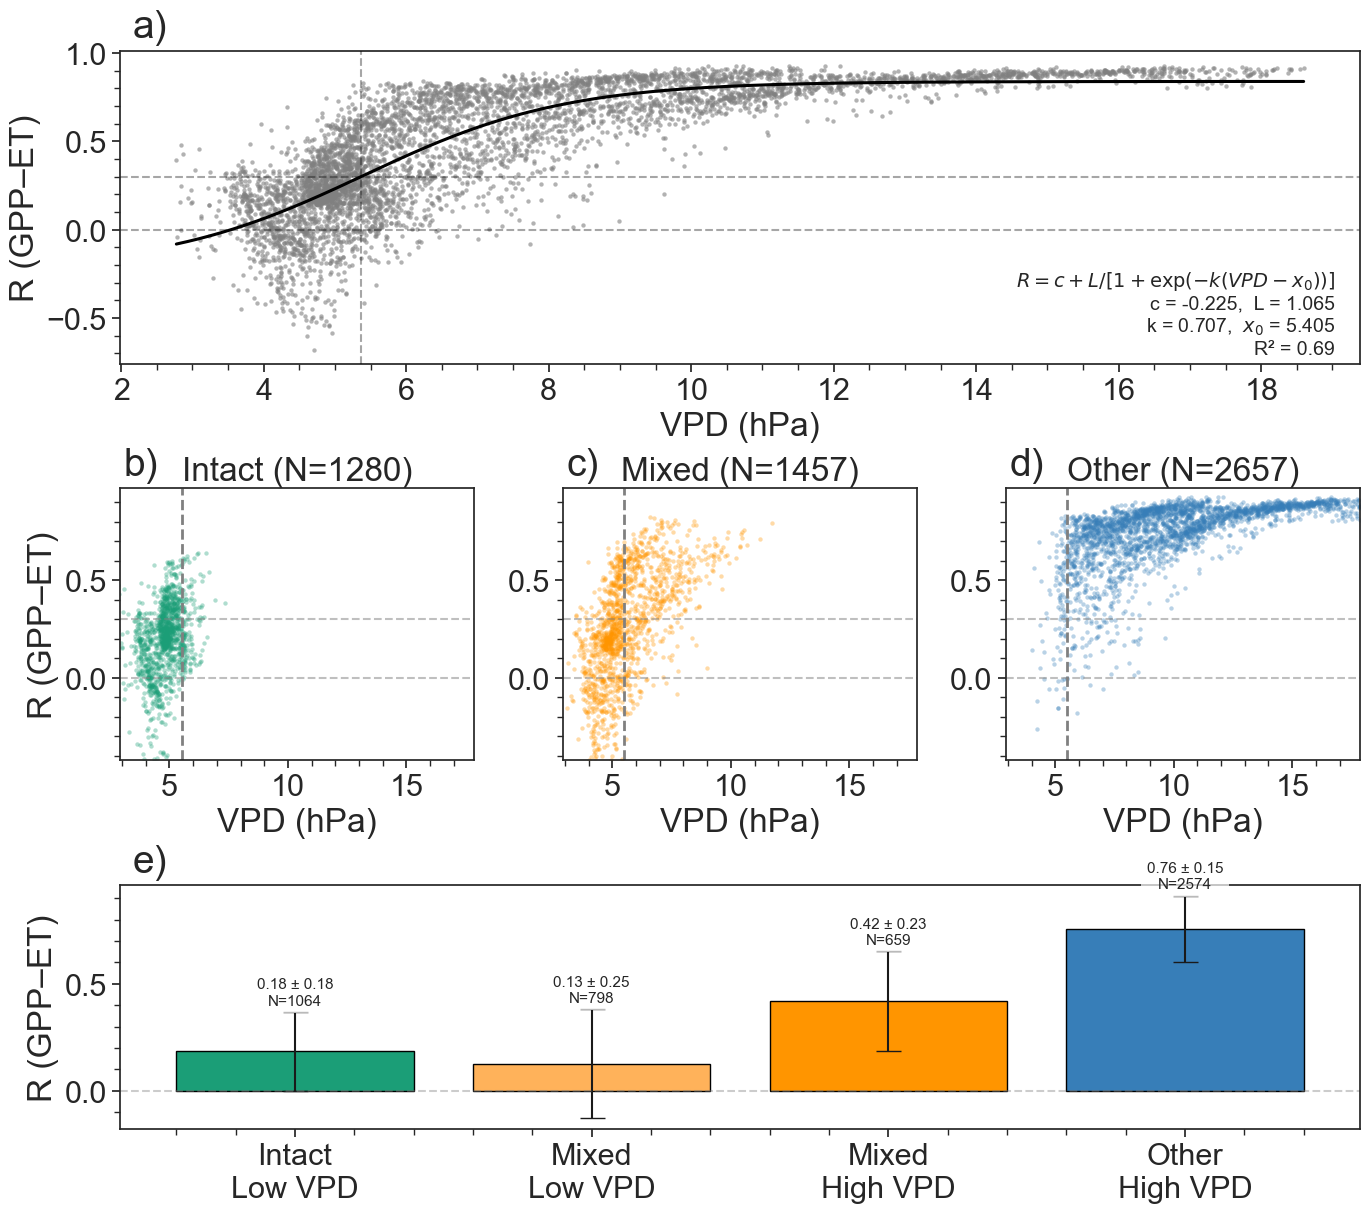

Figure saved to: /Users/sworden/Documents/EqAfricaGPPETResults/Figure3_Scatter.png


In [16]:


# SETTINGS
R_thr = 0.3
VPD_THR_LINE = 5.51
OUTPNG = "/Users/sworden/Documents/EqAfricaGPPETResults/Figure3_Scatter.png"
OUTCSV = "/Users/sworden/Documents/EqAfricaGPPETResults/Figure3_Logistic_Statistics.csv"

# INPUTS
VPD_da = VPDFin
R_da = TestCorr.sel(lat=slice(-8, 8), lon=slice(8, 32))
B_da = JRC_static  # 0 Intact, 1 Disturbed, 2 Other, 3 Mixed

# HELPERS
def r2_score(y_true, y_hat):
    ss_res = np.sum((y_true - y_hat)**2)
    ss_tot = np.sum((y_true - np.mean(y_true))**2)
    return 1 - ss_res / ss_tot if ss_tot > 0 else np.nan

def logistic(x, L, k, x0, c):
    return c + L / (1 + np.exp(-k * (x - x0)))

def mean_std_n(values):
    values = np.asarray(values, float)
    values = values[np.isfinite(values)]
    n = len(values)
    return (np.mean(values), np.std(values, ddof=1) if n > 1 else np.nan, n) if n else (np.nan, np.nan, 0)

def _ensure_latlon(da):
    rename = {"latitude": "lat", "longitude": "lon"}
    return da.rename({k: v for k, v in rename.items() if k in da.dims})

def _drop_time_if_present(da):
    if "time" in da.dims:
        if da.sizes["time"] != 1:
            raise ValueError("Select or aggregate time before fitting.")
        da = da.isel(time=0, drop=True)
    return da

# STANDARDIZE + ALIGN
VPD_da = _drop_time_if_present(_ensure_latlon(VPD_da))
R_da = _drop_time_if_present(_ensure_latlon(R_da))
B_da = _drop_time_if_present(_ensure_latlon(B_da))
VPD2, R2, B2 = xr.align(VPD_da, R_da, B_da, join="inner")

# PANEL A: LOGISTIC FIT
x_all = VPD2.values.ravel().astype(float)
y_all = R2.values.ravel().astype(float)
m = np.isfinite(x_all) & np.isfinite(y_all) & (x_all > 0)
x_fit, y_fit = x_all[m], y_all[m]

if len(x_fit) < 5:
    raise ValueError("Not enough valid pixels for logistic fit.")

idx = np.argsort(x_fit)
xs, ys = x_fit[idx], y_fit[idx]

# Initial guesses and bounds
c0 = np.nanpercentile(y_fit, 5)
L0 = np.nanpercentile(y_fit, 95) - c0
x0_0 = np.nanmedian(x_fit)
p0 = [L0, 1.5, x0_0, c0]
bounds = ([-np.inf, 0.01, 0.0, -np.inf], [np.inf, 50.0, 10.0, np.inf])

# Fit and R²
popt, pcov = curve_fit(logistic, x_fit, y_fit, p0=p0, bounds=bounds, maxfev=200000)
L, k, x0, c = popt
yhat = logistic(x_fit, *popt)
r2 = r2_score(y_fit, yhat)

# PARAMETER STANDARD ERRORS AND P-VALUES
perr = np.sqrt(np.diag(pcov))
n_obs, n_params = len(y_fit), len(popt)
dof = n_obs - n_params

with np.errstate(divide="ignore", invalid="ignore"):
    t_values = popt / perr
p_values = 2 * student_t.sf(np.abs(t_values), df=dof)
p_values[(~np.isfinite(perr)) | (perr <= 0)] = np.nan

fit_stats = {
    name: {"estimate": val, "stderr": err, "p_value": pval}
    for name, val, err, pval in zip(["L", "k", "x0", "c"], popt, perr, p_values)
}

# PRINT TABLE S1
print("\nTABLE S1: GENERALIZED LOGISTIC REGRESSION")
print("=" * 55)
print(f"{'Parameter':<12}{'Estimate ± SE':<25}{'P-value':<15}")
print("-" * 55)

for name in ["L", "c", "k", "x0"]:
    s = fit_stats[name]
    val, err, pval = s["estimate"], s["stderr"], s["p_value"]
    p_text = "N/A" if not np.isfinite(pval) else ("p < 1e-4" if pval < 1e-4 else f"p = {pval:.3e}")
    print(f"{name:<12}{f'{val:.4f} ± {err:.4f}':<25}{p_text:<15}")

print("-" * 55)
print(f"R² = {r2:.4f}")
print(f"N = {n_obs:,}")
print("=" * 55)

# SAVE STATISTICS
stats_df = pd.DataFrame([
    {"Parameter": name, "Estimate": fit_stats[name]["estimate"],
     "Standard Error": fit_stats[name]["stderr"],
     "P-value": fit_stats[name]["p_value"], "R2": r2, "N": n_obs}
    for name in ["L", "c", "k", "x0"]
])
Path(OUTCSV).parent.mkdir(parents=True, exist_ok=True)
stats_df.to_csv(OUTCSV, index=False)
print(f"\nStatistics saved to: {OUTCSV}")

# CALCULATE VPD* WHERE R = R_thr
VPD_star = np.nan
q = (R_thr - c) / L if np.isfinite(L) and L != 0 else np.nan
if np.isfinite(q) and 0 < q < 1 and np.isfinite(k) and k != 0:
    VPD_star = x0 - np.log((1 / q) - 1) / k

print(f"VPD* (R = {R_thr}) = {VPD_star:.4f} hPa")

xg = np.linspace(np.nanmin(xs), np.nanmax(xs), 600)
yg = logistic(xg, *popt)
eq_text = (
    r"$R = c + L/[1+\exp(-k(VPD-x_0))]$" "\n"
    f"c = {c:.3f},  L = {L:.3f}\n"
    f"k = {k:.3f},  $x_0$ = {x0:.3f}\n"
    f"R² = {r2:.2f}"
)

# PANELS B–D: SCATTER BY CLASS
xv = VPD2.values.ravel().astype(float)
yv = R2.values.ravel().astype(float)
cv = B2.values.ravel()

m = np.isfinite(xv) & np.isfinite(yv) & np.isfinite(cv)
xv, yv, cv = xv[m], yv[m], cv[m].astype(int)

labels4 = {0: "Intact", 1: "Disturbed", 2: "Other", 3: "Mixed"}
panel_colors = {0: "#1b9e77", 3: "#ff9500", 2: "#377eb8"}

keep3 = (cv == 0) | (cv == 2) | (cv == 3)
xv3, yv3, cv3 = xv[keep3], yv[keep3], cv[keep3]

# Shared limits
x_lo, x_hi = np.nanpercentile(xv3, [1, 99]) if xv3.size else (0, 1)
y_lo, y_hi = np.nanpercentile(yv3, [1, 99]) if yv3.size else (-1, 1)
x_pad = 0.05 * (x_hi - x_lo) if x_hi > x_lo else 0.1
y_pad = 0.05 * (y_hi - y_lo) if y_hi > y_lo else 0.1
xlim_bd = (x_lo - x_pad, x_hi + x_pad)
ylim_bd = (y_lo - y_pad, y_hi + y_pad)

# PANEL E: BAR PLOT
VPD_THR_BAR = VPD_star if np.isfinite(VPD_star) else VPD_THR_LINE
lowV, highV = xv < VPD_THR_BAR, xv >= VPD_THR_BAR

groups = [
    ("Intact\nLow VPD", (cv == 0) & lowV),
    ("Mixed\nLow VPD", (cv == 3) & lowV),
    ("Mixed\nHigh VPD", (cv == 3) & highV),
    ("Other\nHigh VPD", (cv == 2) & highV)
]

group_stats = [mean_std_n(yv[mask]) for _, mask in groups]
means, stds, Ns = map(np.array, zip(*group_stats))
bar_labels = [name for name, _ in groups]
bar_colors = ["#1b9e77", "#ffb25a", "#ff9500", "#377eb8"]

# FIGURE LAYOUT
fig = plt.figure(figsize=(16, 14))
gs = GridSpec(3, 3, figure=fig, height_ratios=[1.15, 1.0, 0.9], hspace=0.45, wspace=0.25)

axA = fig.add_subplot(gs[0, :])
axB = fig.add_subplot(gs[1, 0])
axC = fig.add_subplot(gs[1, 1])
axD = fig.add_subplot(gs[1, 2])
axE = fig.add_subplot(gs[2, :])

# (a) LOGISTIC
axA.scatter(xs, ys, s=10, color="grey", alpha=0.6, linewidths=0)
axA.plot(xg, yg, color="black", linewidth=2.2)
axA.axhline(R_thr, linestyle="--", alpha=0.35, color="black")
axA.axhline(0, linestyle="--", alpha=0.35, color="black")
if np.isfinite(VPD_star):
    axA.axvline(VPD_star, linestyle="--", alpha=0.35, color="black", zorder=5)

axA.set_xlabel("VPD (hPa)")
axA.set_ylabel("R (GPP–ET)")
axA.minorticks_on()
axA.text(0.98, 0.02, eq_text, transform=axA.transAxes, ha="right", va="bottom",
         fontsize=14, bbox=dict(facecolor="white", alpha=0.75, edgecolor="none"))

# (b–d) CLASS SCATTERS
def plot_class(ax, class_id):
    mk = cv3 == class_id
    xk, yk = xv3[mk], yv3[mk]
    ax.scatter(xk, yk, s=10, alpha=0.35, c=panel_colors[class_id], linewidths=0)
    ax.axhline(0, color="grey", linestyle="--", alpha=0.5)
    ax.axhline(R_thr, color="grey", linestyle="--", alpha=0.5)
    if VPD_THR_LINE is not None:
        ax.axvline(VPD_THR_LINE, color="grey", linestyle="--", linewidth=2)
    ax.set_title(f"{labels4[class_id]} (N={xk.size})")
    ax.set_xlim(*xlim_bd)
    ax.set_ylim(*ylim_bd)
    ax.set_xlabel("VPD (hPa)")
    ax.minorticks_on()

plot_class(axB, 0)
plot_class(axC, 3)
plot_class(axD, 2)
axB.set_ylabel("R (GPP–ET)")
axC.set_ylabel("")
axD.set_ylabel("")

# (e) BAR PLOT
bars = axE.bar(bar_labels, means, yerr=stds, capsize=9, color=bar_colors, edgecolor="black")
axE.set_ylabel("R (GPP–ET)")
axE.minorticks_on()
axE.axhline(0, color="grey", linestyle="--", alpha=0.4)

for bar, mean, std, n in zip(bars, means, stds, Ns):
    xpos = bar.get_x() + bar.get_width() / 2
    bump = (std if np.isfinite(std) else 0) + 0.02
    axE.text(xpos, bar.get_height() + bump, f"{mean:.2f} ± {std:.2f}\nN={n}",
             ha="center", va="bottom", fontsize=11,
             bbox=dict(facecolor="white", alpha=0.7, edgecolor="none"))

# PANEL LABELS
for ax, label in zip([axA, axB, axC, axD, axE], ["a)", "b)", "c)", "d)", "e)"]):
    ax.text(0.01, 1.02, label, transform=ax.transAxes, fontsize=28, va="bottom", ha="left")

# SAVE FIGURE
Path(OUTPNG).parent.mkdir(parents=True, exist_ok=True)
fig.savefig(OUTPNG, dpi=300, bbox_inches="tight")
plt.show()
print(f"Figure saved to: {OUTPNG}")


## Figure 3

In [17]:
TrendArr=np.load('/Users/sworden/Documents/CongoGPPETArrays/TrendArr.npy')
TrendArrlon=np.load('/Users/sworden/Documents/CongoGPPETArrays/TrendArrlon.npy')
TrendArrlat=np.load('/Users/sworden/Documents/CongoGPPETArrays/TrendArrlat.npy')
TrendArr=xr.DataArray(TrendArr,coords=[TrendArrlat, TrendArrlon], dims=['lat','lon'])

In [19]:
#   R1: 3.5–7N,   8–30E
#   R2: 8S–0,    15–30E
#   R3: 5S–5N,    8–30E
TrendArrAIRS=TrendArr[::-1,:].interp(lat=VPDArrAIRS.lat,lon=VPDArrAIRS.lon,method='linear')
GPPR1=GPPNew.sel(lat=slice(3.5,7),lon=slice(8, 30)).where(TrendArr>0)
ETR1=AET.sel(lat=slice(3.5,7),lon=slice(8, 30)).where(TrendArr>0)
VPDER1=VPDArr.sel(lat=slice(3.5,7),lon=slice(8, 30)).where(TrendArr>0)
VPDAR1=VPDArrAIRS[:,::-1,:].sel(lat=slice(3.5,7),lon=slice(8, 30)).where(TrendArrAIRS>0)

GPPR2=GPPNew.sel(lat=slice(-8,0),lon=slice(15,30)).where(TrendArr>0)
ETR2=AET.sel(lat=slice(-8,0),lon=slice(15,30)).where(TrendArr>0)
VPDER2=VPDArr.sel(lat=slice(-8,0),lon=slice(15,30)).where(TrendArr>0)
VPDAR2=VPDArrAIRS[:,::-1,:].sel(lat=slice(-8,0),lon=slice(15,30)).where(TrendArrAIRS>0)

GPPR3=GPPNew.sel(lat=slice(-5,5),lon=slice(8,30)).where(TrendArr<=0)
ETR3=AET.sel(lat=slice(-5,5),lon=slice(8,30)).where(TrendArr<=0)
VPDER3=VPDArr.sel(lat=slice(-5,5),lon=slice(8,30)).where(TrendArr<=0)
VPDAR3=VPDArrAIRS[:,::-1,:].sel(lat=slice(-5,5),lon=slice(8,30)).where(TrendArrAIRS<=0)

In [20]:
WIN = 36  # 36-month window

# helpers
def to_1d_time(da: xr.DataArray) -> xr.DataArray:
    if 'time' not in da.dims:
        raise ValueError("DataArray must have a 'time' dimension.")
    spatial_dims = [d for d in da.dims if d != 'time']
    return da.mean(dim=spatial_dims, skipna=True) if spatial_dims else da


def as_month_start(da: xr.DataArray) -> xr.DataArray:
    """Coerce time coords to month-start timestamps so different sources match exactly."""
    ts = pd.to_datetime(da['time'].values).to_period('M').to_timestamp(how='start')
    da2 = da.assign_coords(time=ts).sortby('time')

    if da2.indexes.get('time') is not None and da2.indexes['time'].duplicated().any():
        da2 = da2.groupby('time').mean('time')

    return da2


def rolling_r(x: xr.DataArray, y: xr.DataArray, win: int = 36):
    # align y to x
    y = y.reindex(time=x.time)

    xv = x.values.astype(float)
    yv = y.values.astype(float)

    n = xv.size

    if n < win:
        raise ValueError(f"Series length {n} is shorter than window {win}.")

    r = np.full(n - win + 1, np.nan)

    for i in range(n - win + 1):
        xi = xv[i:i+win]
        yi = yv[i:i+win]

        m = np.isfinite(xi) & np.isfinite(yi)

        if (
            m.sum() >= 3
            and np.nanstd(xi[m]) > 0
            and np.nanstd(yi[m]) > 0
        ):
            r[i] = np.corrcoef(xi[m], yi[m])[0, 1]

    # right-aligned time axis
    t = x.time[win-1:].values

    return t, r


def rolling_mean(ser: xr.DataArray, win=36):
    return ser.rolling(time=win, min_periods=win).mean()


def align_exact_to(t_axis, ser_1d: xr.DataArray):
    """Exact reindex to given t_axis."""
    return ser_1d.reindex(
        time=pd.DatetimeIndex(t_axis)
    ).values


def pair_metrics(x, y):
    """Return N, Pearson r, R², slope/intercept, and p-value."""

    x = np.asarray(x, float)
    y = np.asarray(y, float)

    m = np.isfinite(x) & np.isfinite(y)
    N = int(m.sum())

    if N < 3:
        return {
            "N": 0,
            "r": np.nan,
            "R2": np.nan,
            "slope": np.nan,
            "intercept": np.nan,
            "p_slope": np.nan
        }

    r, p_r = pearsonr(x[m], y[m])
    slope, intercept, r_val, p_slope, _ = linregress(x[m], y[m])

    return {
        "N": N,
        "r": r,
        "R2": r**2,
        "slope": slope,
        "intercept": intercept,
        "p_slope": p_slope
    }

regs = [
    {
        'title': 'R1',
        'gpp': GPPR1,
        'et': ETR1,
        'vpdE': VPDER1
    },
    {
        'title': 'R2',
        'gpp': GPPR2,
        'et': ETR2,
        'vpdE': VPDER2
    },
    {
        'title': 'R3',
        'gpp': GPPR3,
        'et': ETR3,
        'vpdE': VPDER3
    },
]

summary_rows = []

for reg in regs:

    title = reg['title']

    # 1. Spatial mean and make all timestamps month-start
    gpp = as_month_start(to_1d_time(reg['gpp']))
    et = as_month_start(to_1d_time(reg['et']))
    vpdE = as_month_start(to_1d_time(reg['vpdE']))

    # 2. 36-month rolling GPP-ET correlation
    t_r_raw, r36_raw = rolling_r(
        gpp,
        et,
        win=WIN
    )

    # 3. 36-month rolling mean VPD
    vpdE36 = rolling_mean(
        vpdE,
        win=WIN
    )

    # 4. Put VPD36 onto exactly the same time axis as r36
    vpdE_on_r_raw = align_exact_to(
        t_r_raw,
        vpdE36
    )

    # 5. Relationship between rolling GPP-ET correlation and rolling VPD
    m1 = pair_metrics(
        r36_raw,
        vpdE_on_r_raw
    )

    print(f"\n=== {title} ===")
    print(
        f"RAW r36 vs VPD36 -> "
        f"N={m1['N']}, "
        f"r={m1['r']:.3f}, "
        f"R²={m1['R2']:.3f}, "
        f"slope={m1['slope']:.4f}, "
        f"p(slope)={m1['p_slope']:.3g}"
    )

    summary_rows.append({
        "Region": title,
        "N raw~VPD": m1["N"],
        "r raw~VPD": m1["r"],
        "R2 raw~VPD": m1["R2"],
        "slope raw~VPD": m1["slope"],
        "p(slope) raw~VPD": m1["p_slope"],
    })


summary = pd.DataFrame(summary_rows)

print("\n--- Summary (R²) ---")
print(summary)


=== R1 ===
RAW r36 vs VPD36 -> N=457, r=0.556, R²=0.309, slope=5.0887, p(slope)=2.09e-38

=== R2 ===
RAW r36 vs VPD36 -> N=457, r=0.619, R²=0.384, slope=1.8299, p(slope)=8.97e-50

=== R3 ===
RAW r36 vs VPD36 -> N=457, r=-0.435, R²=0.190, slope=-1.2451, p(slope)=1.45e-22

--- Summary (R²) ---
  Region  N raw~VPD  r raw~VPD  R2 raw~VPD  slope raw~VPD  p(slope) raw~VPD
0     R1        457   0.555798    0.308912       5.088663      2.087303e-38
1     R2        457   0.619456    0.383726       1.829893      8.969618e-50
2     R3        457  -0.435409    0.189581      -1.245135      1.449529e-22


In [21]:
with xr.open_dataset(
    "/Users/sworden/Documents/AnnualChange/JRC_TMF_AnnualChange_bucket4_on_AETgrid_8_30E_-8_10N_ALLYEARS.nc"
) as ds:
    JRC_annual = ds.bucket4.load()


#### Supplementary Figure 3


JRC MIXED-PIXEL CUSUM BREAKPOINT ANALYSIS
Region  Breakpoint year  Before (pp/year)  After (pp/year)  Change (pp/year)
  Reg1             1999           0.02116          0.34783           0.32666
  Reg2             1998           0.03997          0.50959           0.46962
  Reg3             1999           0.04480          0.93619           0.89138

BREAKPOINT_YEARS = {'Reg1': 1999, 'Reg2': 1998, 'Reg3': 1999}


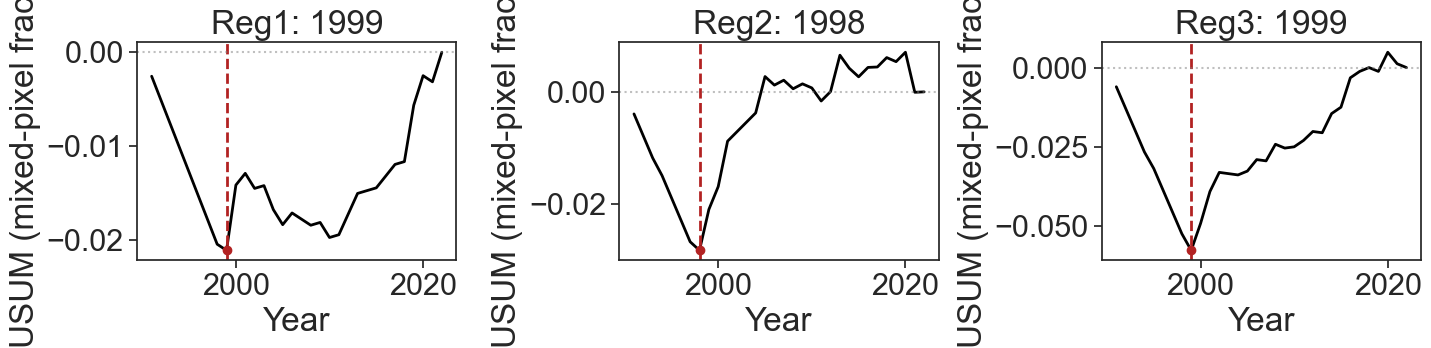


Reg 1 (North) (start=1990-01-01, end=2022-01-01):
  Intact    : start=  0.101   end=  0.047   Δ= -0.054
  Disturbed : start=  0.000   end=  0.003   Δ= +0.003
  Other     : start=  0.694   end=  0.664   Δ= -0.030
  Mixed     : start=  0.205   end=  0.287   Δ= +0.082

Reg 2 (South) (start=1990-01-01, end=2022-01-01):
  Intact    : start=  0.388   end=  0.250   Δ= -0.137
  Disturbed : start=  0.000   end=  0.033   Δ= +0.033
  Other     : start=  0.353   end=  0.332   Δ= -0.021
  Mixed     : start=  0.260   end=  0.385   Δ= +0.125

Reg 3 (Central) (start=1990-01-01, end=2022-01-01):
  Intact    : start=  0.777   end=  0.542   Δ= -0.235
  Disturbed : start=  0.000   end=  0.016   Δ= +0.016
  Other     : start=  0.122   end=  0.121   Δ= -0.001
  Mixed     : start=  0.102   end=  0.321   Δ= +0.219


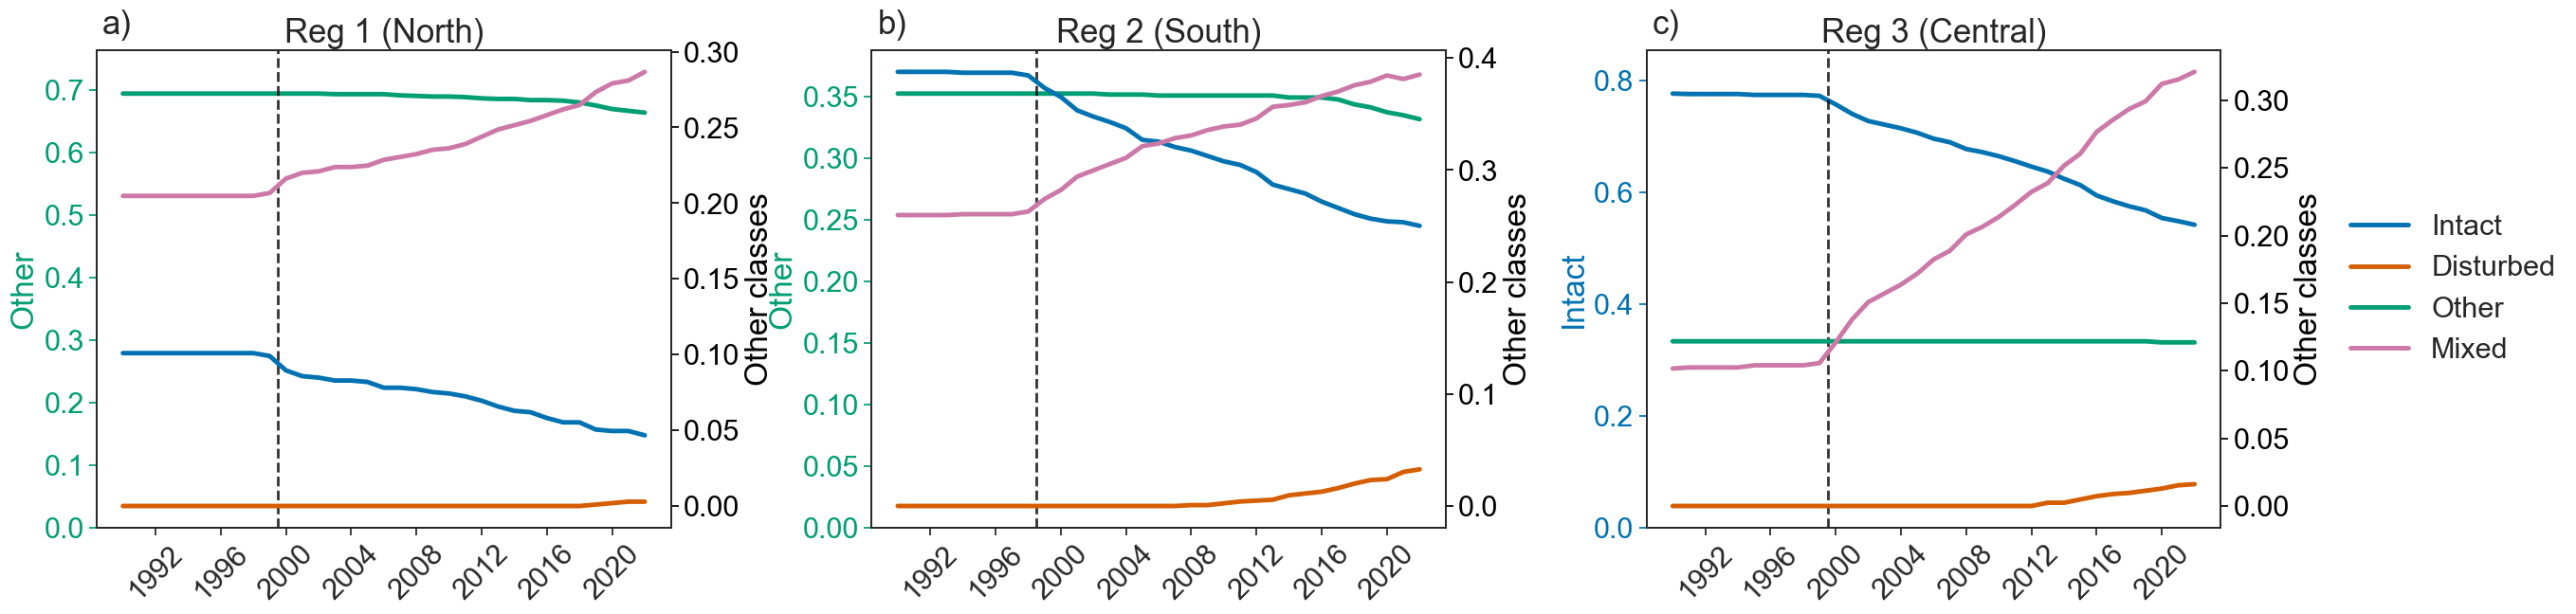

In [22]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# INPUTS
JRC = JRC_annual
TREND = TrendArr
MIN_SIDE = 5  # Minimum annual changes on each side of breakpoint

labels = {0: "Intact", 1: "Disturbed", 2: "Other", 3: "Mixed"}
colors = {0: "#0072B2", 1: "#D55E00", 2: "#009E73", 3: "#CC79A7"}

# HELPERS
def jrc_region(JRC, TREND, lat1, lat2, lon1, lon2, trend_keep):
    j = sel_range(sel_range(JRC, "lat", lat1, lat2), "lon", lon1, lon2)
    t = sel_range(sel_range(TREND, "lat", lat1, lat2), "lon", lon1, lon2)
    return j.where(trend_keep(t))

def frac_time_series(JRC_reg):
    valid = (JRC_reg >= 0)
    den = valid.sum(dim=("lat", "lon"))
    return {k: (((JRC_reg == k) & valid).sum(dim=("lat", "lon")) / den).where(den > 0).astype("float32")
            for k in [0, 1, 2, 3]}

def print_begin_end_fracs(frac, region_name):
    any_valid = np.logical_or.reduce([np.isfinite(frac[k].values) for k in [0, 1, 2, 3]])
    if not np.any(any_valid):
        print(f"\n{region_name}: no valid fractions.")
        return

    i0, i1 = np.where(any_valid)[0][[0, -1]]
    t0, t1 = frac[0].time.values[[i0, i1]]
    print(f"\n{region_name} (start={np.datetime_as_string(t0, unit='D')}, end={np.datetime_as_string(t1, unit='D')}):")

    for k in [0, 1, 2, 3]:
        v0, v1 = float(frac[k].values[i0]), float(frac[k].values[i1])
        print(f"  {labels[k]:<10s}: start={v0:7.3f}   end={v1:7.3f}   Δ={v1-v0:+7.3f}")

# BUILD THREE REGIONS
JRC_N = jrc_region(JRC, TREND, 3.5, 7.0, 8.0, 30.0, trend_keep=lambda t: t > 0)
JRC_S = jrc_region(JRC, TREND, -8.0, 0.0, 15.0, 30.0, trend_keep=lambda t: t > 0)
JRC_C = jrc_region(JRC, TREND, -5.0, 5.0, 8.0, 30.0, trend_keep=lambda t: t <= 0)
JRC_REGIONS = {"Reg1": JRC_N, "Reg2": JRC_S, "Reg3": JRC_C}

# CUSUM BREAKPOINT ANALYSIS
def cusum_breakpoint(mixed_frac, min_side=5):
    years = pd.to_datetime(mixed_frac.time.values).year.to_numpy(dtype=int)
    fractions = np.asarray(mixed_frac.values, dtype=float)
    valid = np.isfinite(fractions) & (years >= 1990) & (years <= 2022)
    years, fractions = years[valid], fractions[valid]

    if len(years) < 2 * min_side + 1 or np.any(np.diff(years) != 1):
        raise ValueError("CUSUM requires consecutive annual data with at least five annual changes on each side.")

    # Annual changes in mixed-pixel fraction
    annual_change = np.diff(fractions)

    # Center changes and calculate cumulative sum
    cusum = np.cumsum(annual_change - annual_change.mean())

    # Candidate years with at least five annual changes before and after
    candidate_idx = np.arange(min_side - 1, len(annual_change) - min_side)
    i = candidate_idx[np.argmin(cusum[candidate_idx])]

    return {
        "year": int(years[i + 1]), "change_years": years[1:],
        "annual_change": annual_change, "cusum": cusum,
        "cusum_min": float(cusum[i]),
        "pre_rate": float(annual_change[:i + 1].mean()),
        "post_rate": float(annual_change[i + 1:].mean())
    }

breakpoint_results = {
    name: cusum_breakpoint(frac_time_series(region)[3], MIN_SIDE)
    for name, region in JRC_REGIONS.items()
}
BREAKPOINT_YEARS = {name: result["year"] for name, result in breakpoint_results.items()}

# PRINT BREAKPOINT RESULTS
breakpoint_table = pd.DataFrame([
    {"Region": name, "Breakpoint year": r["year"],
     "Before (pp/year)": 100 * r["pre_rate"],
     "After (pp/year)": 100 * r["post_rate"],
     "Change (pp/year)": 100 * (r["post_rate"] - r["pre_rate"])}
    for name, r in breakpoint_results.items()
])
print("\nJRC MIXED-PIXEL CUSUM BREAKPOINT ANALYSIS")
print(breakpoint_table.round(5).to_string(index=False))
print("\nBREAKPOINT_YEARS =", BREAKPOINT_YEARS)

# DIAGNOSTIC CUSUM FIGURE
fig_c, axes_c = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, r) in zip(axes_c, breakpoint_results.items()):
    ax.plot(r["change_years"], r["cusum"], color="black", lw=2)
    ax.axvline(r["year"], color="firebrick", linestyle="--", lw=2)
    ax.scatter(r["year"], r["cusum_min"], color="firebrick", zorder=5)
    ax.axhline(0, color="grey", linestyle=":", alpha=0.5)
    ax.set_title(f"{name}: {r['year']}")
    ax.set_xlabel("Year")
    ax.set_ylabel("CUSUM (mixed-pixel fraction)")
fig_c.tight_layout()
plt.show()

# JRC VEGETATION FRACTION FIGURE
def plot_jrc_dynamic_axes(ax1, JRC_reg, title, panel_label, break_year=None,
                          legend_out=False, legend_anchor=(1.02, 0.5), lw=3.5):
    frac = frac_time_series(JRC_reg)
    print_begin_end_fracs(frac, title)

    means = {k: float(frac[k].mean("time", skipna=True)) for k in [0, 1, 2, 3]}
    left_k = min(means, key=lambda k: (-np.nan_to_num(means[k], nan=-1e9), k))
    right_ks = [k for k in [0, 1, 2, 3] if k != left_k]

    # Left axis: dominant class
    l_left, = ax1.plot(JRC_reg.time, frac[left_k], color=colors[left_k],
                       label=labels[left_k], linewidth=lw)
    ax1.set_ylabel(labels[left_k], color=colors[left_k])
    ax1.tick_params(axis="y", colors=colors[left_k])
    ymax_left = float(frac[left_k].max(skipna=True))
    ax1.set_ylim(0, 1.1 * ymax_left if np.isfinite(ymax_left) and ymax_left > 0 else 1)

    # Right axis: remaining classes
    ax2 = ax1.twinx()
    lines = [l_left]
    for k in right_ks:
        l, = ax2.plot(JRC_reg.time, frac[k], color=colors[k],
                      label=labels[k], linewidth=lw)
        lines.append(l)
    ax2.set_ylabel("Other classes", color="black")
    ax2.tick_params(axis="y", colors="black")

    # Calculated CUSUM breakpoint year (no hard-coded dates)
    if break_year is not None:
        vd = np.datetime64(f"{int(break_year)}-07-01")
        ax1.axvline(vd, color="black", linewidth=2, linestyle="--", alpha=0.8, zorder=10)

    ax1.set_title(title, fontsize=25)
    ax1.text(0.01, 1.02, panel_label, transform=ax1.transAxes,
             fontsize=25, ha="left", va="bottom")

    if legend_out:
        ax1.legend(lines, [ln.get_label() for ln in lines],
                   frameon=False, loc="center left", bbox_to_anchor=legend_anchor)

    return ax2, lines

# PLOT THREE REGIONS
out_png = "/Users/sworden/Documents/EqAfricaGPPETResults/FigureS3.png"

fig, axes = plt.subplots(1, 3, figsize=(28, 7), sharex=True)
fig.subplots_adjust(left=0.06, right=0.86, top=0.90, bottom=0.18, wspace=0.35)

ax2_a, lines_a = plot_jrc_dynamic_axes(
    axes[0], JRC_N, "Reg 1 (North)", "a)",
    break_year=BREAKPOINT_YEARS["Reg1"], legend_out=False
)
ax2_b, lines_b = plot_jrc_dynamic_axes(
    axes[1], JRC_S, "Reg 2 (South)", "b)",
    break_year=BREAKPOINT_YEARS["Reg2"], legend_out=False
)
ax2_c, lines_c = plot_jrc_dynamic_axes(
    axes[2], JRC_C, "Reg 3 (Central)", "c)",
    break_year=BREAKPOINT_YEARS["Reg3"], legend_out=True, legend_anchor=(1.18, 0.5)
)

for ax in axes:
    ax.set_xlabel("")
    ax.tick_params(axis="x", labelrotation=45)

plt.savefig(out_png, dpi=300, format="png", bbox_inches="tight")
plt.show()


### Figure 4

Figure 3 breakpoint years: {'Reg1': 1999, 'Reg2': 1998, 'Reg3': 1999}


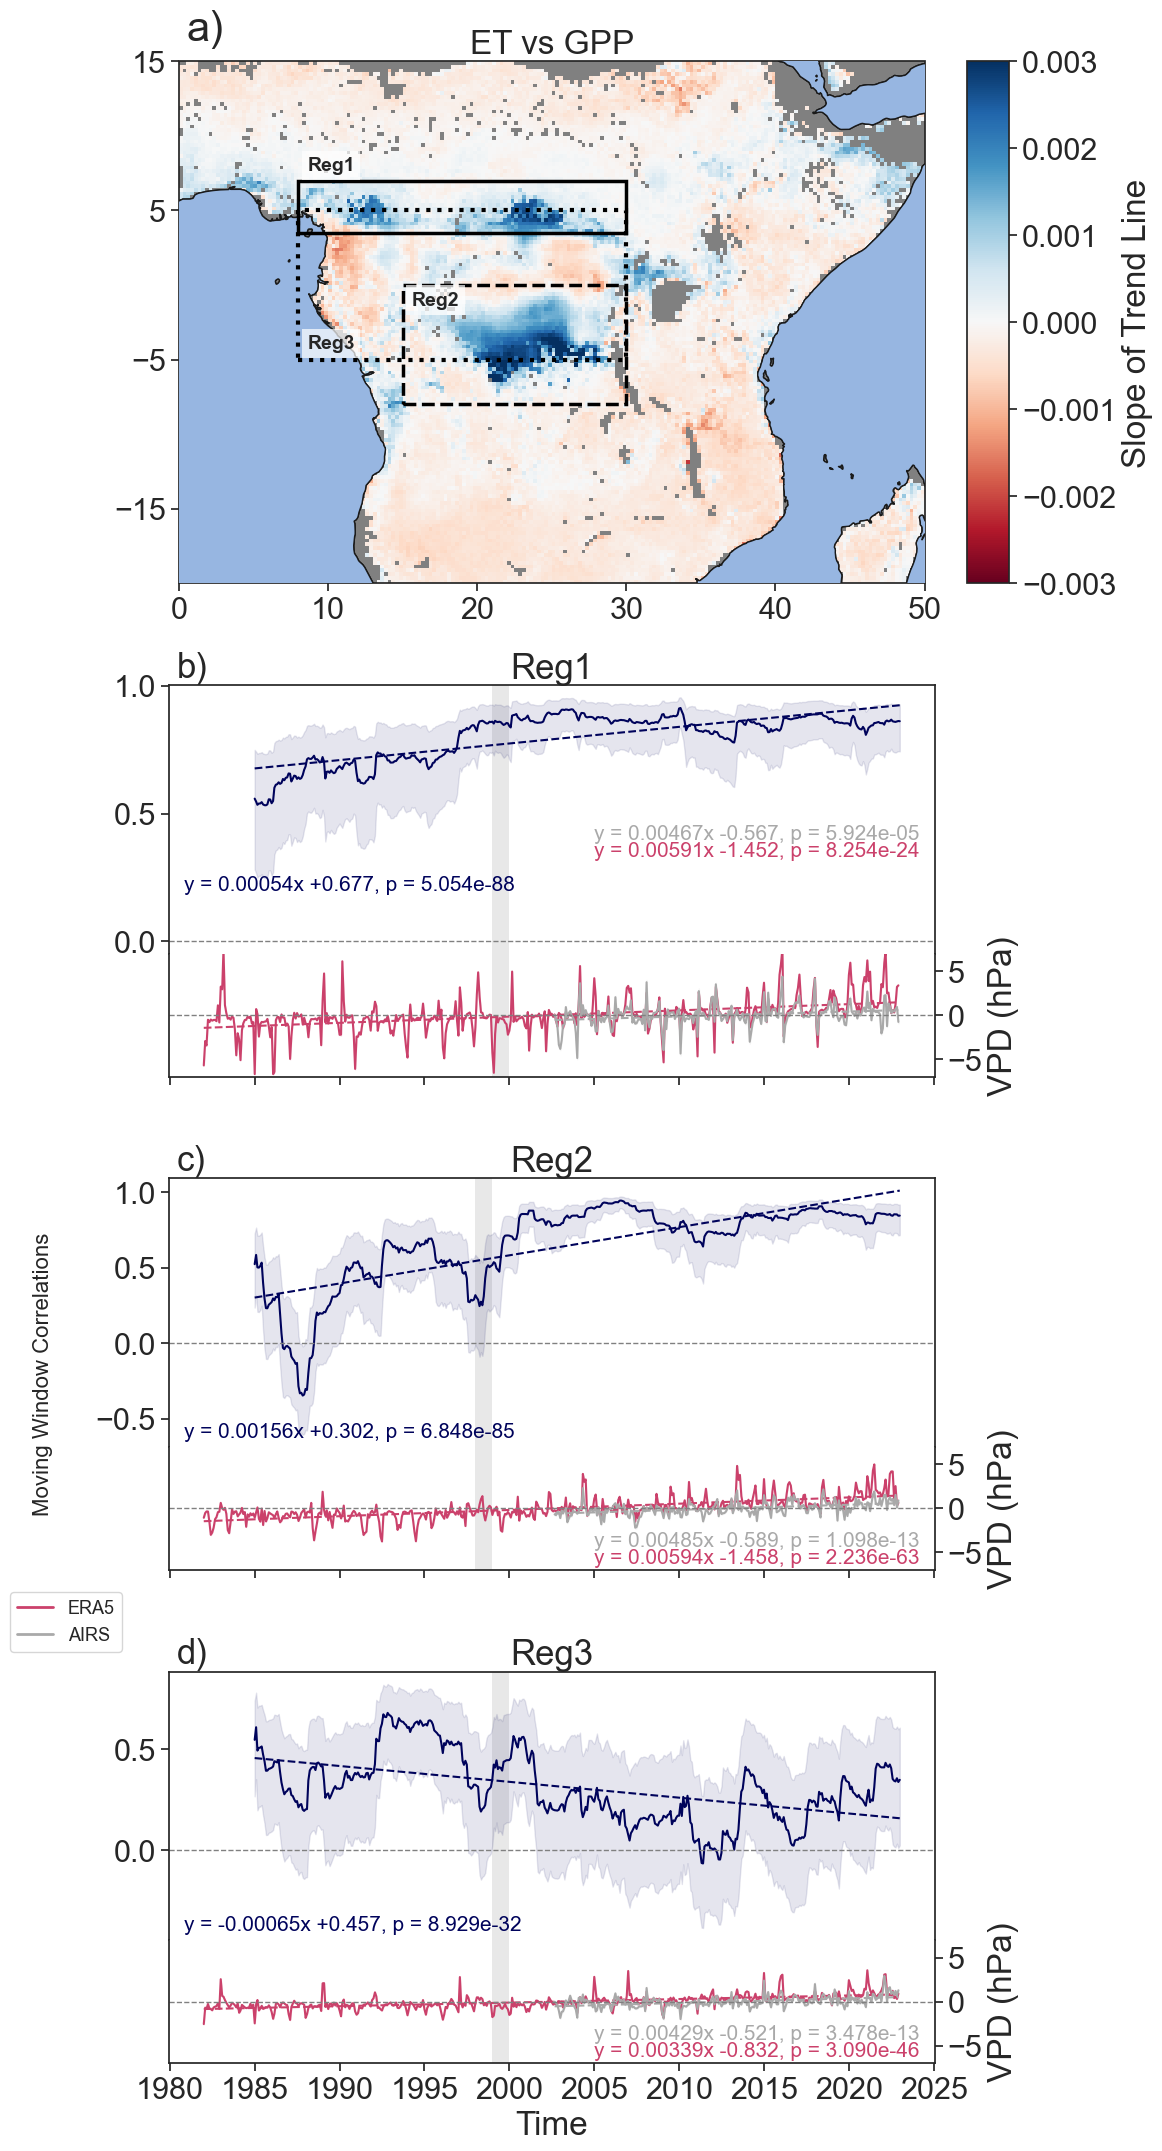

In [23]:
# Rolling correlation + trend
def CalcTrendLine(GPP_da, ET_da, window_size=36):
    gpp = to_1d_time(GPP_da)
    et = to_1d_time(ET_da)

    if gpp.sizes["time"] != et.sizes["time"]:
        raise ValueError("GPP and ET have different time lengths; they must be aligned already.")
    if not np.array_equal(gpp["time"].values, et["time"].values):
        raise ValueError("GPP and ET time coordinates differ; they must be aligned already.")

    x = gpp.values.astype(float)
    y = et.values.astype(float)
    N = x.shape[0]
    win = int(window_size)

    if N < win or win < 3:
        raise ValueError(f"window_size={win} invalid for series length N={N} (need N>=win and win>=3).")

    corr = np.full(N - win + 1, np.nan)
    rlow = np.full_like(corr, np.nan, dtype=float)
    rhigh = np.full_like(corr, np.nan, dtype=float)
    zcrit = norm.ppf(0.975)

    for i in range(N - win + 1):
        xi = x[i:i + win]
        yi = y[i:i + win]
        m = np.isfinite(xi) & np.isfinite(yi)
        n = int(m.sum())

        if n < 3:
            continue

        r = np.corrcoef(xi[m], yi[m])[0, 1]
        corr[i] = r

        if np.isfinite(r) and abs(r) < 1 and n > 3:
            z = np.arctanh(r)
            se = 1.0 / np.sqrt(n - 3)
            rlow[i] = np.tanh(z - zcrit * se)
            rhigh[i] = np.tanh(z + zcrit * se)

    valid = np.isfinite(corr)
    if valid.sum() >= 3:
        tnum = np.arange(corr.size)[valid]
        slope, intercept, _, p_val, _ = linregress(tnum, corr[valid])
    else:
        slope, intercept, p_val = np.nan, np.nan, np.nan

    return win, corr, rlow, rhigh, slope, intercept, p_val


# Deseasonalized VPD anomalies + SEM
def anomalies_with_sem(da: xr.DataArray):
    if "time" not in da.dims:
        raise ValueError("Input DataArray must have a 'time' dimension.")

    clim = da.groupby("time.month").mean("time", skipna=True)
    anom = da.groupby("time.month") - clim
    spatial_dims = [d for d in anom.dims if d != "time"]

    if spatial_dims:
        mean_anom = anom.mean(dim=spatial_dims, skipna=True)
        std = anom.std(dim=spatial_dims, skipna=True, ddof=1)
        n = anom.notnull().sum(dim=spatial_dims)
        sem = (std / np.sqrt(n.where(n > 0))).fillna(0)
    else:
        mean_anom = anom
        sem = xr.zeros_like(mean_anom)

    return mean_anom["time"].values, mean_anom.values, sem.values


# Shade full breakpoint year identified from annual JRC analysis
def add_breakpoint_span(ax, break_year):
    if break_year is None:
        return

    start = np.datetime64(f"{int(break_year)}-01-01")
    end = np.datetime64(f"{int(break_year) + 1}-01-01")
    ax.axvspan(start, end, color="grey", alpha=0.18, linewidth=0, zorder=0)


# Individual correlation + VPD panel
def plot_panel(ax_corr, ax_vpd, title,
               GPP_da, ET_da, VPD_E, VPD_A,
               corr_color="#00035b", era5_color="#cb416b", airs_color="darkgrey",
               window_size=36,
               draw_zero_corr=True, draw_zero_vpd=True,
               corr_text_y=0.02, vpd_ylim=(-7, 7),
               era_text_axis="vpd", era_text_mode="bottom",
               era_text_base_y=0.02, era_text_delta=0.14,
               above0_offset=0.25,
               break_year=None):

    win, corr, rlow, rhigh, slope, b, p = CalcTrendLine(
        GPP_da, ET_da, window_size=window_size
    )

    t_axis = GPP_da["time"].values[win - 1:]
    L = min(len(t_axis), len(corr))
    t_axis, corr, rlow, rhigh = t_axis[:L], corr[:L], rlow[:L], rhigh[:L]

    ax_corr.plot(t_axis, corr, color=corr_color, lw=1.5)
    ax_corr.fill_between(t_axis, rlow, rhigh, color=corr_color, alpha=0.10)

    tnum = np.arange(len(corr))
    ax_corr.plot(t_axis, slope * tnum + b, color=corr_color, linestyle="--")
    ax_corr.set_title(title, fontsize=25, pad=2)

    if draw_zero_corr:
        ax_corr.axhline(0, color="grey", linestyle="--", linewidth=1)

    add_breakpoint_span(ax_corr, break_year)

    ax_corr.spines["bottom"].set_visible(False)
    ax_corr.tick_params(axis="x", bottom=False, labelbottom=False)

    ax_corr.text(
        0.02, corr_text_y,
        f"y = {slope:.5f}x {b:+.3f}, p = {p:.3e}",
        transform=ax_corr.transAxes, fontsize=15, color=corr_color,
        ha="left", va="bottom"
    )

    # ERA5 VPD anomalies
    tE, meanE, seE = anomalies_with_sem(VPD_E)
    ax_vpd.plot(tE, meanE, color=era5_color, label="ERA5")
    ax_vpd.fill_between(tE, meanE - seE, meanE + seE, color=era5_color, alpha=0.10)

    tnE = np.arange(len(tE))
    sE, bE, _, pE, _ = linregress(tnE, meanE)
    ax_vpd.plot(tE, sE * tnE + bE, color=era5_color, linestyle="--")

    # AIRS VPD anomalies
    tA, meanA, seA = anomalies_with_sem(VPD_A)
    ax_vpd.plot(tA, meanA, color=airs_color, label="AIRS")
    ax_vpd.fill_between(tA, meanA - seA, meanA + seA, color=airs_color, alpha=0.10)

    tnA = np.arange(len(tA))
    sA, bA, _, pA, _ = linregress(tnA, meanA)
    ax_vpd.plot(tA, sA * tnA + bA, color=airs_color, linestyle="--")

    if draw_zero_vpd:
        ax_vpd.axhline(0, color="grey", linestyle="--", linewidth=1)

    add_breakpoint_span(ax_vpd, break_year)

    ax_vpd.set_ylabel("VPD (hPa)")
    ax_vpd.yaxis.set_label_position("right")
    ax_vpd.yaxis.tick_right()
    ax_vpd.spines["top"].set_visible(False)
    ax_vpd.set_ylim(vpd_ylim)

    # ERA5/AIRS trend text
    text_ax = ax_corr if era_text_axis == "corr" else ax_vpd

    if era_text_mode == "above0":
        y0, y1 = text_ax.get_ylim()
        y0_ax = (0 - y0) / (y1 - y0)
        yE = min(max(y0_ax + above0_offset, 0.05), 0.95)
        yA = min(max(yE + era_text_delta, 0.05), 0.95)
    else:
        yE = era_text_base_y
        yA = era_text_base_y + era_text_delta

    text_ax.text(
        0.98, yE,
        f"y = {sE:.5f}x {bE:+.3f}, p = {pE:.3e}",
        transform=text_ax.transAxes, fontsize=15, color=era5_color,
        ha="right", va="bottom"
    )

    text_ax.text(
        0.98, yA,
        f"y = {sA:.5f}x {bA:+.3f}, p = {pA:.3e}",
        transform=text_ax.transAxes, fontsize=15, color=airs_color,
        ha="right", va="bottom"
    )


# Combined figure
def make_4panel_one_column_aligned(
    out_png_path="/Users/sworden/Documents/EqAfricaGPPETResults/Map_RVPD_OneColumn_Aligned.png",
    era5_color="#cb416b", airs_color="darkgrey"):

    ERA_BASE_Y = 0.02
    ERA_DELTA_CD = 0.14

    fig = plt.figure(figsize=(12, 22))
    fig.subplots_adjust(left=0.22, right=0.92, top=0.97, bottom=0.06)

    outer = GridSpec(
        4, 2, figure=fig,
        width_ratios=[1.0, 0.055],
        height_ratios=[2.6, 1.95, 1.95, 1.95],
        hspace=0.24, wspace=0.08
    )

    # a) map
    ax_map = fig.add_subplot(outer[0, 0], projection=ccrs.PlateCarree())
    cax = fig.add_subplot(outer[0, 1])

    im = ax_map.pcolormesh(
        TrendArr.lon, TrendArr.lat, TrendArr,
        transform=ccrs.PlateCarree(),
        vmin=-0.003, vmax=0.003, cmap="RdBu"
    )

    ax_map.set_facecolor("grey")
    ax_map.coastlines()
    ax_map.set_xticks([0, 10, 20, 30, 40, 50], crs=ccrs.PlateCarree())
    ax_map.set_yticks([-15, -5, 5, 15], crs=ccrs.PlateCarree())
    ax_map.add_feature(cfeature.OCEAN, zorder=100, edgecolor="k")

    cb = fig.colorbar(im, cax=cax)
    cb.set_label("Slope of Trend Line")

    ax_map.text(.01, 1.04, "a)", fontsize=30, transform=ax_map.transAxes)
    ax_map.set_title("ET vs GPP")

    # Region boxes
    regions = {
        "Reg1": dict(lon0=8, lon1=30, lat0=3.5, lat1=7, ls="-", lw=2.5),
        "Reg2": dict(lon0=15, lon1=30, lat0=-8, lat1=0, ls="--", lw=2.5),
        "Reg3": dict(lon0=8, lon1=30, lat0=-5, lat1=5, ls=":", lw=3.0),
    }

    for name, r in regions.items():
        lon0, lon1 = r["lon0"], r["lon1"]
        lat0, lat1 = r["lat0"], r["lat1"]

        ax_map.add_patch(Rectangle(
            (lon0, lat0), lon1 - lon0, lat1 - lat0,
            fill=False, edgecolor="black",
            linewidth=r["lw"], linestyle=r["ls"],
            transform=ccrs.PlateCarree(), zorder=200
        ))

        if name == "Reg3":
            xlab, ylab, ha, va = lon0 + 0.6, lat0 + 0.45, "left", "bottom"
        elif name == "Reg1":
            xlab, ylab, ha, va = lon0 + 0.6, lat1 + 0.4, "left", "bottom"
        else:
            xlab, ylab, ha, va = lon0 + 0.6, lat1 - 0.4, "left", "top"

        ax_map.text(
            xlab, ylab, name,
            transform=ccrs.PlateCarree(),
            fontsize=14, fontweight="bold",
            ha=ha, va=va,
            bbox=dict(facecolor="white", alpha=0.7, edgecolor="none"),
            zorder=210
        )

    # b-d regional panels
    panel_info = [
        dict(
            title="Reg1", GPP=GPPR1, ET=ETR1, VPD_E=VPDER1, VPD_A=VPDAR1, lab="b)",
            draw_zero_corr=True, draw_zero_vpd=True,
            corr_text_y=0.22, era_text_axis="corr", era_text_mode="above0",
            above0_offset=0.30, break_year=BREAKPOINT_YEARS["Reg1"]
        ),
        dict(
            title="Reg2", GPP=GPPR2, ET=ETR2, VPD_E=VPDER2, VPD_A=VPDAR2, lab="c)",
            draw_zero_corr=True, draw_zero_vpd=True,
            corr_text_y=0.02, era_text_axis="vpd", era_text_mode="bottom",
            break_year=BREAKPOINT_YEARS["Reg2"]
        ),
        dict(
            title="Reg3", GPP=GPPR3, ET=ETR3, VPD_E=VPDER3, VPD_A=VPDAR3, lab="d)",
            draw_zero_corr=True, draw_zero_vpd=True,
            corr_text_y=0.02, era_text_axis="vpd", era_text_mode="bottom",
            break_year=BREAKPOINT_YEARS["Reg3"]
        ),
    ]

    first_corr = None
    bottom_axes_corr = []
    bottom_axes_vpd = []

    for row, info in enumerate(panel_info, start=1):
        sub = outer[row, 0].subgridspec(
            2, 1, height_ratios=[2.4, 1.1], hspace=0.0
        )

        ax_corr = fig.add_subplot(
            sub[0], sharex=first_corr if first_corr is not None else None
        )

        if first_corr is None:
            first_corr = ax_corr

        ax_vpd = fig.add_subplot(sub[1], sharex=first_corr)

        corr_h = ax_corr.get_position().height
        vpd_h = ax_vpd.get_position().height
        delta_b = ERA_DELTA_CD * (vpd_h / corr_h)

        if info.get("era_text_axis", "vpd") == "corr":
            era_delta_use = delta_b
        else:
            era_delta_use = ERA_DELTA_CD

        plot_panel(
            ax_corr, ax_vpd, info["title"],
            info["GPP"], info["ET"], info["VPD_E"], info["VPD_A"],
            window_size=36,
            draw_zero_corr=info.get("draw_zero_corr", True),
            draw_zero_vpd=info.get("draw_zero_vpd", True),
            corr_text_y=info.get("corr_text_y", 0.02),
            era_text_axis=info.get("era_text_axis", "vpd"),
            era_text_mode=info.get("era_text_mode", "bottom"),
            era_text_base_y=ERA_BASE_Y,
            era_text_delta=era_delta_use,
            above0_offset=info.get("above0_offset", 0.25),
            era5_color=era5_color,
            airs_color=airs_color,
            break_year=info.get("break_year", None)
        )

        ax_corr.set_ylabel("")

        leg = ax_vpd.get_legend()
        if leg is not None:
            leg.remove()

        ax_corr.text(.01, 1.03, info["lab"], fontsize=25, transform=ax_corr.transAxes)

        bottom_axes_corr.append(ax_corr)
        bottom_axes_vpd.append(ax_vpd)

        if row < 3:
            ax_vpd.set_xlabel("")
            ax_vpd.tick_params(axis="x", labelbottom=False)
        else:
            ax_vpd.set_xlabel("Time")

        ax_blank = fig.add_subplot(outer[row, 1])
        ax_blank.axis("off")

    # Shared ylabel + legend
    fig.canvas.draw()

    left = min(ax.get_position().x0 for ax in bottom_axes_corr + bottom_axes_vpd)
    top = max(ax.get_position().y1 for ax in bottom_axes_corr)
    bottom = min(ax.get_position().y0 for ax in bottom_axes_vpd)
    center_y = 0.5 * (top + bottom)
    height = top - bottom
    ylab_x = left - 0.105

    fig.text(
        ylab_x, center_y, "Moving Window Correlations",
        rotation=90, ha="center", va="center", fontsize=16
    )

    handles = [
        Line2D([0], [0], color=era5_color, lw=2),
        Line2D([0], [0], color=airs_color, lw=2),
    ]
    labels = ["ERA5", "AIRS"]

    leg_x = ylab_x - 0.035
    leg_y = center_y - 0.18 * height

    fig.legend(
        handles, labels,
        loc="center left",
        bbox_to_anchor=(leg_x, leg_y),
        frameon=True, fontsize=13
    )

    plt.savefig(out_png_path, dpi=300, bbox_inches="tight")
    plt.show()


# Run
print("Figure 3 breakpoint years:", BREAKPOINT_YEARS)

make_4panel_one_column_aligned(
    "/Users/sworden/Documents/EqAfricaGPPETResults/Figure4.png"
)

## Figures 5-7

Breakpoints used in Figures 5-7: {'Reg1': 1999, 'Reg2': 1998, 'Reg3': 1999}


C:\Users\sworden\AppData\Local\Temp\ipykernel_44860\3436372179.py:172: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0,0,0.90,1])


Saved region 4-class triptych → /Users/sworden/Documents/EqAfricaGPPETResults\region_triptych_Reg1Reg2Reg3_bucket4.png


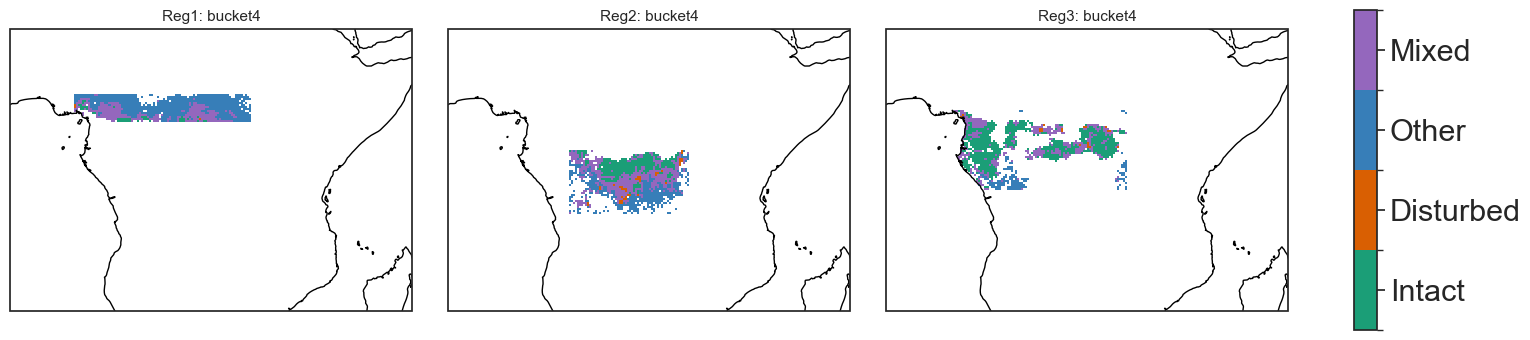

[Reg1]    Intact pixels =      49 (skipped, N<50)
[Reg1] Disturbed pixels =       3 (skipped, N<50)
[Reg1]     Other pixels =     697 
[Reg1]     Mixed pixels =     301 

Reg1 Other GPP | slope=0.00078123 per month | intercept=6.630648 | p=0.19756847 | r=0.058189 | R2=0.003386 | SE=0.00060549 | N=492
Reg1 Other ET | slope=-0.00792400 per month | intercept=94.647330 | p=0.17333358 | r=-0.061483 | R2=0.003780 | SE=0.00581128 | N=492
Reg1 Other r(GPP,ET) | slope=0.00030042 per month | intercept=0.775301 | p=2.0347037e-69 | r=0.703253 | R2=0.494565 | SE=0.00001424 | N=457
Reg1 Other VPD | slope=0.00609509 per month | intercept=-1.496346 | p=4.0149609e-23 | r=0.426110 | R2=0.181570 | SE=0.00058459 | N=492
Reg1 Mixed GPP | slope=0.00022589 per month | intercept=7.818285 | p=0.41286258 | r=0.036999 | R2=0.001369 | SE=0.00027563 | N=492
Reg1 Mixed ET | slope=-0.01027724 per month | intercept=110.337390 | p=0.009244314 | r=-0.117240 | R2=0.013745 | SE=0.00393275 | N=492
Reg1 Mixed r(GPP,ET) | s

C:\Users\sworden\AppData\Local\Temp\ipykernel_44860\3436372179.py:343: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved dashboard → /Users/sworden/Documents/EqAfricaGPPETResults\dashboard_Reg1_Nmin50_Figure3TrendMethod.png


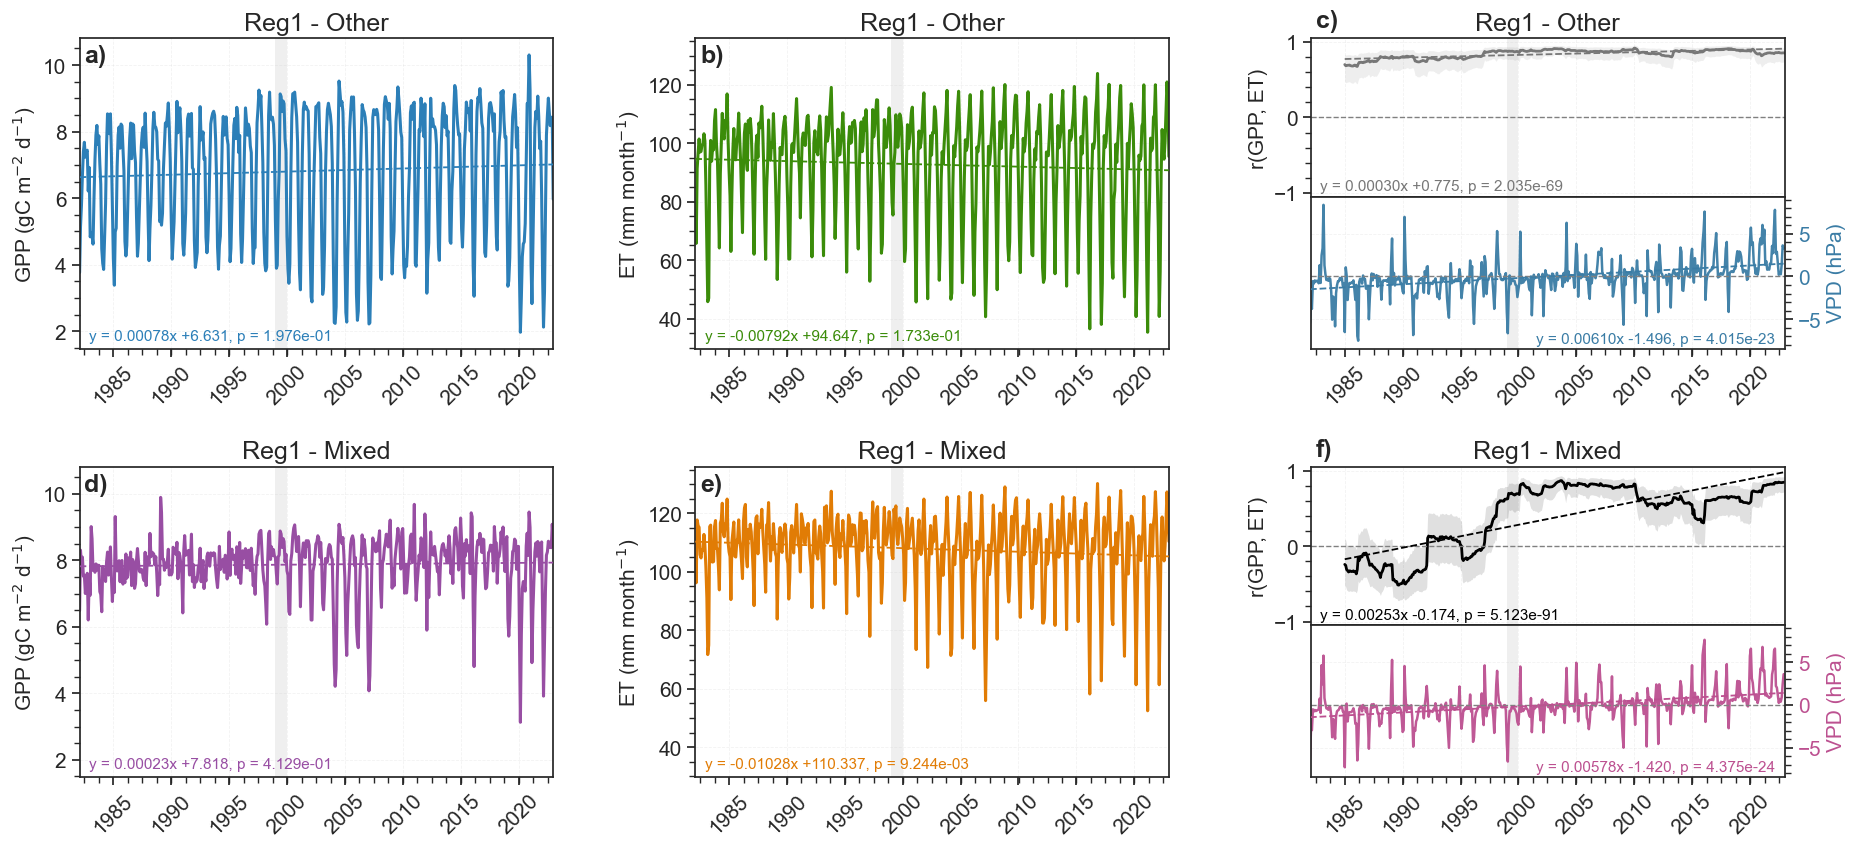

[Reg1]    Intact — skipped (N=49 < 50)
[Reg1] Disturbed — skipped (N=3 < 50)


C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\array\numpy_compat.py:53: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\core.py:127: RuntimeWarning: invalid value encountered in divide
  return func(*(_execute_task(a, cache) for a in args))


[Reg1]     Other | pixels=    697 | r_grid mean±std=0.737 ± 0.101


C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\array\numpy_compat.py:53: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\core.py:127: RuntimeWarning: invalid value encountered in divide
  return func(*(_execute_task(a, cache) for a in args))


[Reg1]     Mixed | pixels=    301 | r_grid mean±std=0.403 ± 0.203

[Reg2]    Intact pixels =     313 
[Reg2] Disturbed pixels =      41 (skipped, N<50)
[Reg2]     Other pixels =     415 
[Reg2]     Mixed pixels =     482 

Reg2 Intact GPP | slope=-0.00094320 per month | intercept=8.344564 | p=1.412449e-06 | r=-0.215438 | R2=0.046413 | SE=0.00019314 | N=492
Reg2 Intact ET | slope=-0.00491884 per month | intercept=120.786663 | p=0.12816154 | r=-0.068683 | R2=0.004717 | SE=0.00322765 | N=492
Reg2 Intact r(GPP,ET) | slope=0.00179231 per month | intercept=-0.104358 | p=8.6940403e-75 | r=0.721973 | R2=0.521244 | SE=0.00008053 | N=457
Reg2 Intact VPD | slope=0.00573121 per month | intercept=-1.407012 | p=2.5641875e-64 | r=0.665809 | R2=0.443302 | SE=0.00029014 | N=492
Reg2 Other GPP | slope=-0.00176233 per month | intercept=6.764333 | p=1.3473501e-06 | r=-0.215848 | R2=0.046590 | SE=0.00036015 | N=492
Reg2 Other ET | slope=-0.01017391 per month | intercept=96.093397 | p=0.0643981 | r=-0.08344

C:\Users\sworden\AppData\Local\Temp\ipykernel_44860\3436372179.py:343: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved dashboard → /Users/sworden/Documents/EqAfricaGPPETResults\dashboard_Reg2_Nmin50_Figure3TrendMethod.png


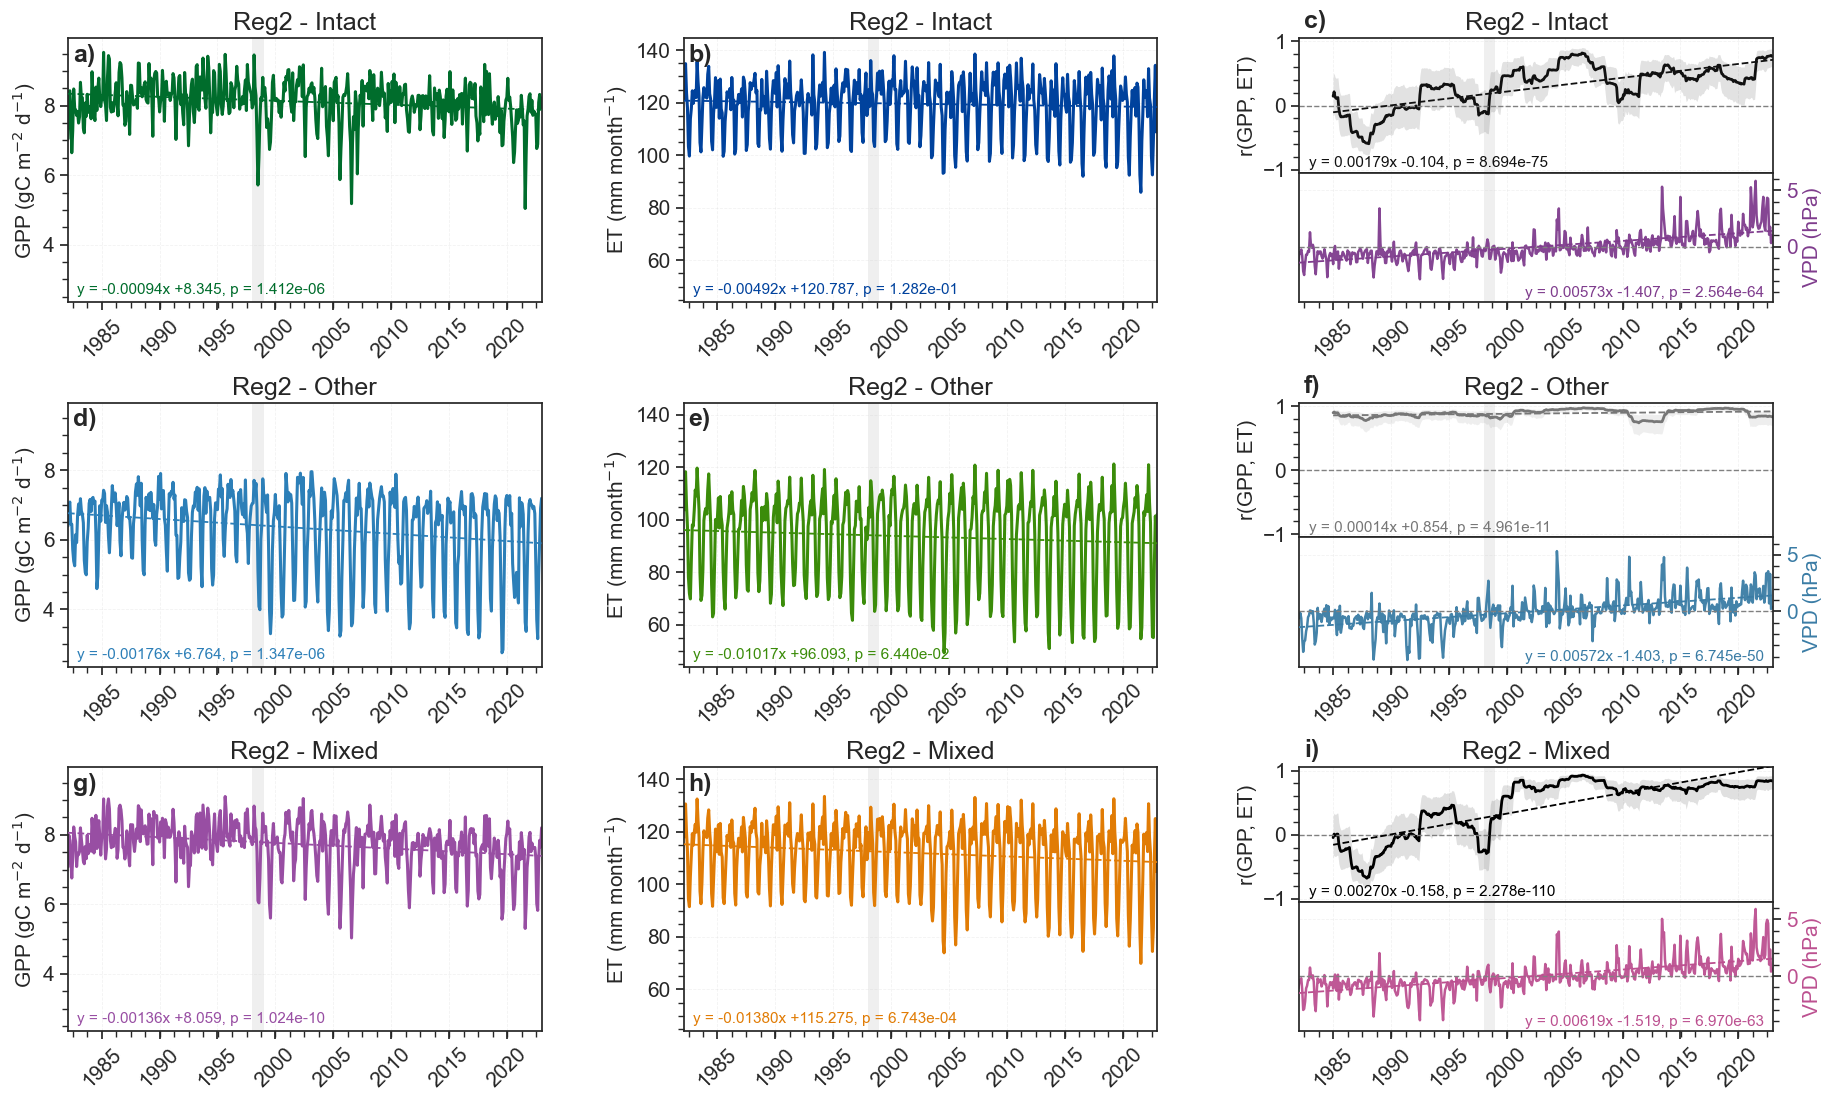

C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\array\numpy_compat.py:53: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\core.py:127: RuntimeWarning: invalid value encountered in divide
  return func(*(_execute_task(a, cache) for a in args))


[Reg2]    Intact | pixels=    313 | r_grid mean±std=0.251 ± 0.216
[Reg2] Disturbed — skipped (N=41 < 50)


C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\array\numpy_compat.py:53: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\core.py:127: RuntimeWarning: invalid value encountered in divide
  return func(*(_execute_task(a, cache) for a in args))


[Reg2]     Other | pixels=    415 | r_grid mean±std=0.690 ± 0.181


C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\array\numpy_compat.py:53: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\core.py:127: RuntimeWarning: invalid value encountered in divide
  return func(*(_execute_task(a, cache) for a in args))


[Reg2]     Mixed | pixels=    482 | r_grid mean±std=0.350 ± 0.334

[Reg3]    Intact pixels =     672 
[Reg3] Disturbed pixels =      20 (skipped, N<50)
[Reg3]     Other pixels =     150 
[Reg3]     Mixed pixels =     398 

Reg3 Intact GPP | slope=-0.00036100 per month | intercept=7.879670 | p=0.016906736 | r=-0.107653 | R2=0.011589 | SE=0.00015061 | N=492
Reg3 Intact ET | slope=0.00122814 per month | intercept=119.308380 | p=0.70354159 | r=0.017199 | R2=0.000296 | SE=0.00322545 | N=492
Reg3 Intact r(GPP,ET) | slope=-0.00050910 per month | intercept=0.293355 | p=9.054719e-15 | r=-0.351917 | R2=0.123846 | SE=0.00006348 | N=457
Reg3 Intact VPD | slope=0.00341072 per month | intercept=-0.837331 | p=4.2440161e-42 | r=0.560803 | R2=0.314500 | SE=0.00022748 | N=492
Reg3 Other GPP | slope=-0.00060835 per month | intercept=6.127316 | p=0.04473861 | r=-0.090532 | R2=0.008196 | SE=0.00030232 | N=492
Reg3 Other ET | slope=0.00158353 per month | intercept=91.871597 | p=0.73704997 | r=0.015175 | R2=

C:\Users\sworden\AppData\Local\Temp\ipykernel_44860\3436372179.py:343: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved dashboard → /Users/sworden/Documents/EqAfricaGPPETResults\dashboard_Reg3_Nmin50_Figure3TrendMethod.png


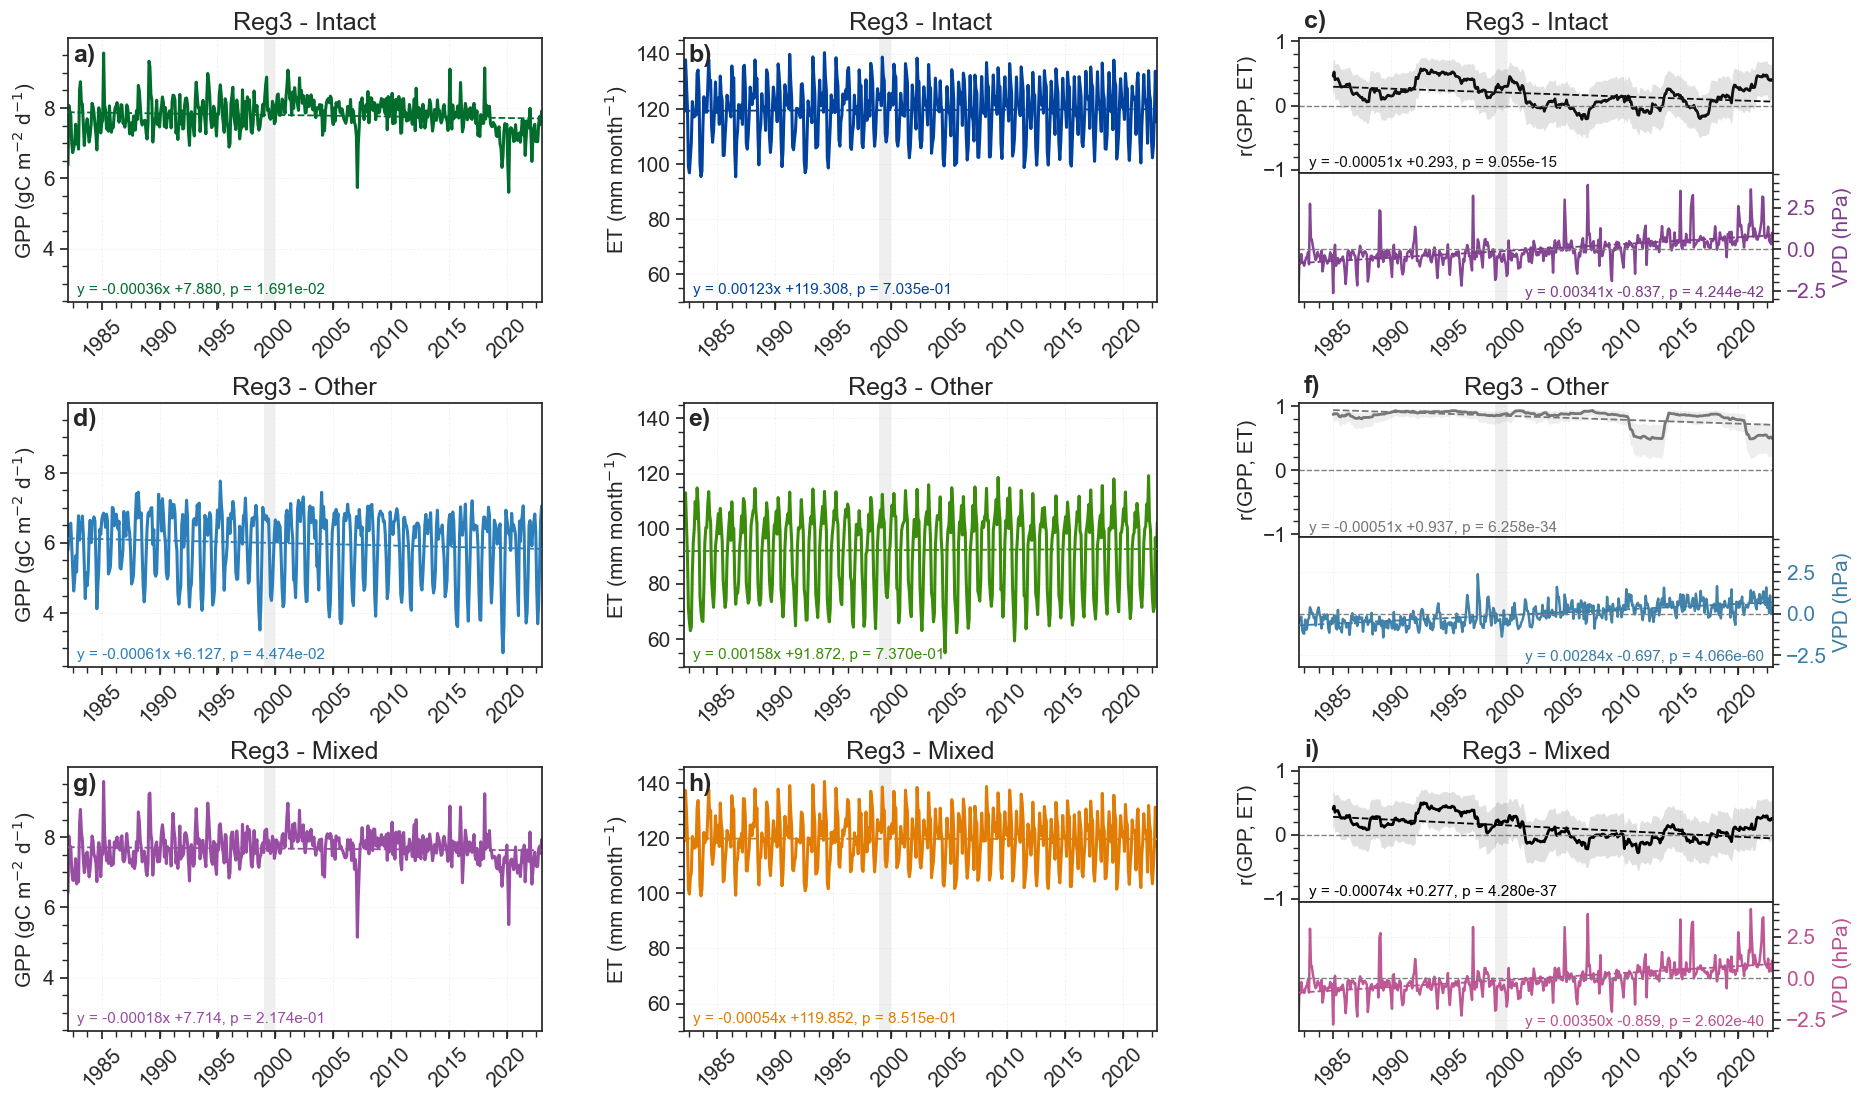

C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\array\numpy_compat.py:53: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\core.py:127: RuntimeWarning: invalid value encountered in divide
  return func(*(_execute_task(a, cache) for a in args))


[Reg3]    Intact | pixels=    672 | r_grid mean±std=0.140 ± 0.158
[Reg3] Disturbed — skipped (N=20 < 50)


C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\array\numpy_compat.py:53: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\core.py:127: RuntimeWarning: invalid value encountered in divide
  return func(*(_execute_task(a, cache) for a in args))


[Reg3]     Other | pixels=    150 | r_grid mean±std=0.639 ± 0.207
[Reg3]     Mixed | pixels=    398 | r_grid mean±std=0.096 ± 0.222

Saved summary log → /Users/sworden/Documents/EqAfricaGPPETResults\summary_pixel_stats_Reg1Reg2Reg3_Nmin50_Figure3TrendMethod.txt


C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\array\numpy_compat.py:53: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\core.py:127: RuntimeWarning: invalid value encountered in divide
  return func(*(_execute_task(a, cache) for a in args))


In [24]:
import os, re, io, string
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

from scipy.stats import linregress
from matplotlib.gridspec import GridSpec
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.dates import YearLocator, DateFormatter

# SETTINGS
gpp_c = {"Intact":"#006d2c", "Disturbed":"#1b9e77", "Other":"#2c7fb8", "Mixed":"#984ea3"}
et_c = {"Intact":"#00429d", "Disturbed":"#73a2ff", "Other":"#3b8c0a", "Mixed":"#e17c05"}
vpd_c = {"Intact":"#7f3c8d", "Disturbed":"#e76f51", "Other":"#3a7ca5", "Mixed":"#bc5090"}
r_c = {"Intact":"#111111", "Disturbed":"#444444", "Other":"#777777", "Mixed":"#000000"}

OUTPUT_DIR = "/Users/sworden/Documents/EqAfricaGPPETResults"
DPI = 300
PIXEL_MIN = 50
os.makedirs(OUTPUT_DIR, exist_ok=True)

if "BREAKPOINT_YEARS" not in globals():
    raise RuntimeError("Run the JRC CUSUM breakpoint-analysis cell first.")

# Force identical x-axis limits on every panel
COMMON_XLIM = (GPPNew["time"].values[0], GPPNew["time"].values[-1])

def add_breakpoint_span(ax, region_name, color="0.7", alpha=0.20):
    year = BREAKPOINT_YEARS.get(region_name)
    if year is None: return
    ax.axvspan(np.datetime64(f"{int(year)}-01-01"), np.datetime64(f"{int(year)+1}-01-01"),
               color=color, alpha=alpha, linewidth=0, zorder=0)

def rolling_corr(x, y, window=36):
    xv, yv = np.asarray(x.values,float), np.asarray(y.values,float)
    n = xv.size
    if n < window:
        t = x["time"][0:0]
        z = np.array([])
        return t, z, z, z

    r = np.full(n-window+1, np.nan)
    t = x["time"][window-1:]

    for i in range(window, n+1):
        xs, ys = xv[i-window:i], yv[i-window:i]
        m = np.isfinite(xs) & np.isfinite(ys)
        if m.sum() >= max(3,window//2) and xs[m].std() > 0 and ys[m].std() > 0:
            r[i-window] = np.corrcoef(xs[m],ys[m])[0,1]

    lo, hi = np.full_like(r,np.nan), np.full_like(r,np.nan)
    finite = np.isfinite(r)

    if finite.any():
        z = np.arctanh(np.clip(r[finite],-0.999999,0.999999))
        se = 1.0/np.sqrt(max(window-3,1))
        lo[finite] = np.tanh(z-1.96*se)
        hi[finite] = np.tanh(z+1.96*se)

    return t, r, lo, hi

def _shared_ylim(series_list):
    vals = []
    for s in series_list:
        v = np.asarray(s.values,float)
        v = v[np.isfinite(v)]
        if v.size: vals.append(v)

    if not vals: return None

    vv = np.concatenate(vals)
    lo, hi = float(np.nanmin(vv)), float(np.nanmax(vv))
    pad = 0.06*(hi-lo if hi > lo else (abs(hi) if hi != 0 else 1.0))
    return lo-pad, hi+pad

def _safe(name):
    return re.sub(r"[^A-Za-z0-9._-]+","_",name)

def area_mean_ts(da, mask2d):
    return da.where(mask2d).mean(dim=("lat","lon"))

def add_fig3_trend(ax, time, values, color, text_xy=(0.02,0.02),
                   ha="left", va="bottom", fontsize=11, log_prefix=None):
    values = np.asarray(values,float)
    tvals = np.asarray(time.values)
    finite = np.isfinite(values)

    if finite.sum() < 3: return None

    x = np.arange(values.size,dtype=float)[finite]
    y, t = values[finite], tvals[finite]

    lr = linregress(x,y)
    trend = lr.slope*x + lr.intercept

    ax.plot(t,trend,ls="--",lw=1.3,color=color,zorder=5)

    txt = f"y = {lr.slope:.5f}x {lr.intercept:+.3f}, p = {lr.pvalue:.3e}"
    ax.text(text_xy[0],text_xy[1],txt,transform=ax.transAxes,
            fontsize=fontsize,color=color,ha=ha,va=va)

    if log_prefix is not None:
        line = (f"{log_prefix} | slope={lr.slope:.8f} per month | "
                f"intercept={lr.intercept:.6f} | p={lr.pvalue:.8g} | "
                f"r={lr.rvalue:.6f} | R2={lr.rvalue**2:.6f} | "
                f"SE={lr.stderr:.8f} | N={finite.sum()}")
        print(line)
        logbuf.write(line+"\n")

    return lr

# STATIC FIELDS / VEGETATION MASKS
AET2d = AET.isel(time=0,drop=True) if "time" in AET.dims else AET
bucket4 = JRC_static

mask_intact = (bucket4 == 0).fillna(False)
mask_disturb = (bucket4 == 1).fillna(False)
mask_other = (bucket4 == 2).fillna(False)
mask_mixed = (bucket4 == 3).fillna(False)

row_order = ["Intact","Disturbed","Other","Mixed"]

year_loc = YearLocator(base=5)
year_fmt = DateFormatter("%Y")

def apply_time_axis(ax, tick_size=15):
    ax.xaxis.set_major_locator(year_loc)
    ax.xaxis.set_major_formatter(year_fmt)
    ax.tick_params(axis="x",labelrotation=45,labelsize=tick_size)

letters = list(string.ascii_lowercase)

# REGION MASKS
Trendg = TrendArr
if isinstance(Trendg,xr.DataArray) and "time" in Trendg.dims:
    Trendg = Trendg.isel(time=0,drop=True)

lat, lon = AET2d["lat"], AET2d["lon"]

Reg1_mask = ((lat>=3.5)&(lat<=7.0)&(lon>=8.0)&(lon<=30.0)&(Trendg>0)).fillna(False)
Reg2_mask = ((lat>=-8.0)&(lat<=0.0)&(lon>=15.0)&(lon<=30.0)&(Trendg>0)).fillna(False)
Reg3_mask = ((lat>=-5.0)&(lat<=5.0)&(lon>=8.0)&(lon<=30.0)&(Trendg<=0)).fillna(False)

region_masks = {"Reg1":Reg1_mask,"Reg2":Reg2_mask,"Reg3":Reg3_mask}

print("Breakpoints used in Figures 5-7:", BREAKPOINT_YEARS)

# OPTIONAL REGION MAP
do_maps = True

if do_maps:
    cmap4 = ListedColormap(["#1b9e77","#d95f02","#377eb8","#9467bd"])
    norm4 = BoundaryNorm([-0.5,0.5,1.5,2.5,3.5],4)

    fig_map, axes = plt.subplots(1,3,figsize=(15,5),
                                 subplot_kw=dict(projection=ccrs.PlateCarree()))

    pm = None
    for ax,(rname,rmask) in zip(axes,region_masks.items()):
        ax.set_title(f"{rname}: bucket4",fontsize=11)
        ax.coastlines()

        bsub = bucket4.where(rmask)
        pm = ax.pcolormesh(AET2d.lon,AET2d.lat,bsub,cmap=cmap4,norm=norm4,
                           transform=ccrs.PlateCarree())

    cax = fig_map.add_axes([0.92,0.18,0.015,0.64])
    cb = plt.colorbar(pm,cax=cax,ticks=[0,1,2,3])
    cb.ax.set_yticklabels(["Intact","Disturbed","Other","Mixed"])

    plt.tight_layout(rect=[0,0,0.90,1])

    f_map = os.path.join(OUTPUT_DIR,"region_triptych_Reg1Reg2Reg3_bucket4.png")
    fig_map.savefig(f_map,dpi=DPI,bbox_inches="tight")
    print(f"Saved region 4-class triptych → {f_map}")

    plt.show()
    plt.close(fig_map)

# STATIC CORRELATION MAP
r_grid = xr.corr(GPPNew,AET,dim="time")

# MAIN LOOP
logbuf = io.StringIO()

for region_name,rmask0 in region_masks.items():
    rmask = rmask0.astype(bool)

    m = {
        "Intact": mask_intact & rmask,
        "Disturbed": mask_disturb & rmask,
        "Other": mask_other & rmask,
        "Mixed": mask_mixed & rmask
    }

    pix = {k:int(m[k].sum().item()) for k in row_order}
    eligible = [k for k in row_order if pix[k] >= PIXEL_MIN]

    for k in row_order:
        note = "" if k in eligible else f"(skipped, N<{PIXEL_MIN})"
        line = f"[{region_name:>4}] {k:>9} pixels = {pix[k]:7d} {note}"
        print(line)
        logbuf.write(line+"\n")

    print()
    logbuf.write("\n")

    if not eligible:
        msg = f"No classes meet PIXEL_MIN={PIXEL_MIN} in {region_name}; skipping."
        print(msg)
        logbuf.write(msg+"\n\n")
        continue

    gpp = {k:area_mean_ts(GPPNew,m[k]) for k in eligible}
    et = {k:area_mean_ts(AET,m[k]) for k in eligible}
    vpd = {k:area_mean_ts(VPDArr,m[k]) for k in eligible}

    vpd_anom = {}
    for k in eligible:
        clim = vpd[k].groupby("time.month").mean("time")
        vpd_anom[k] = vpd[k].groupby("time.month")-clim

    rc = {k:rolling_corr(gpp[k],et[k],window=36) for k in eligible}

    gpp_ylim = _shared_ylim(list(gpp.values()))
    et_ylim = _shared_ylim(list(et.values()))
    vpd_ylim = _shared_ylim(list(vpd_anom.values()))

    nrows = len(eligible)
    fig = plt.figure(figsize=(22,3.3*nrows+3))
    gs = GridSpec(nrows,3,figure=fig,hspace=0.38,wspace=0.30)

    def draw_row(row_idx,klass):
        ax_g = fig.add_subplot(gs[row_idx,0])
        ax_e = fig.add_subplot(gs[row_idx,1])
        ax_p = fig.add_subplot(gs[row_idx,2])

        row_title = f"{region_name} - {klass}"
        base_idx = row_idx*3

        if base_idx < len(letters):
            ax_g.text(0.01,0.98,f"{letters[base_idx]})",transform=ax_g.transAxes,
                      ha="left",va="top",fontsize=18,fontweight="bold")

        if base_idx+1 < len(letters):
            ax_e.text(0.01,0.98,f"{letters[base_idx+1]})",transform=ax_e.transAxes,
                      ha="left",va="top",fontsize=18,fontweight="bold")

        if base_idx+2 < len(letters):
            ax_p.text(0.01,1.02,f"{letters[base_idx+2]})",transform=ax_p.transAxes,
                      ha="left",va="bottom",fontsize=18,fontweight="bold")

        # GPP
        s = gpp[klass]
        ax_g.plot(s["time"],s,lw=2.2,color=gpp_c[klass])
        add_fig3_trend(ax_g,s["time"],s.values,gpp_c[klass],
                       text_xy=(0.02,0.02),log_prefix=f"{region_name} {klass} GPP")
        add_breakpoint_span(ax_g,region_name)

        ax_g.set_xlim(COMMON_XLIM)
        ax_g.set_title(row_title,fontsize=18)
        ax_g.set_ylabel("GPP (gC m$^{-2}$ d$^{-1}$)",fontsize=15)
        if gpp_ylim: ax_g.set_ylim(*gpp_ylim)
        ax_g.grid(alpha=0.25,ls="--",lw=0.6)
        apply_time_axis(ax_g,15)
        ax_g.tick_params(axis="y",labelsize=15)
        ax_g.minorticks_on()

        # ET
        s = et[klass]
        ax_e.plot(s["time"],s,lw=2.2,color=et_c[klass])
        add_fig3_trend(ax_e,s["time"],s.values,et_c[klass],
                       text_xy=(0.02,0.02),log_prefix=f"{region_name} {klass} ET")
        add_breakpoint_span(ax_e,region_name)

        ax_e.set_xlim(COMMON_XLIM)
        ax_e.set_title(row_title,fontsize=18)
        ax_e.set_ylabel("ET (mm month$^{-1}$)",fontsize=15)
        if et_ylim: ax_e.set_ylim(*et_ylim)
        ax_e.grid(alpha=0.25,ls="--",lw=0.6)
        apply_time_axis(ax_e,15)
        ax_e.tick_params(axis="y",labelsize=15)
        ax_e.minorticks_on()

        # r(GPP, ET) + VPD
        ax_p.set_frame_on(False)
        ax_p.set_xticks([])
        ax_p.set_yticks([])

        t_r,rvals,lo,hi = rc[klass]

        # Top: rolling correlation
        ax_top = ax_p.inset_axes([0.0,0.49,1.0,0.51])

        if rvals.size and np.isfinite(rvals).any():
            ax_top.plot(t_r,rvals,lw=2.0,color=r_c[klass])
            ax_top.fill_between(t_r.values,lo,hi,alpha=0.12,lw=0,color=r_c[klass])
            add_fig3_trend(ax_top,t_r,rvals,r_c[klass],
                           text_xy=(0.02,0.02),
                           log_prefix=f"{region_name} {klass} r(GPP,ET)")
        else:
            ax_top.text(0.5,0.6,"no data",ha="center",va="center",
                        transform=ax_top.transAxes)

        add_breakpoint_span(ax_top,region_name)

        ax_top.set_xlim(COMMON_XLIM)
        ax_top.axhline(0,color="grey",lw=1.0,ls="--")
        ax_top.set_ylim(-1.05,1.05)
        ax_top.set_title(row_title,fontsize=18)
        ax_top.set_ylabel("r(GPP, ET)",fontsize=15)
        ax_top.grid(alpha=0.25,ls="--",lw=0.6)
        apply_time_axis(ax_top,15)
        ax_top.tick_params(axis="y",labelsize=15)
        ax_top.minorticks_on()

        # Bottom: VPD anomalies
        ax_bot = ax_p.inset_axes([0.0,0.00,1.0,0.49])

        sv = vpd_anom[klass]
        ax_bot.plot(sv["time"],sv,lw=1.8,alpha=0.95,color=vpd_c[klass])
        add_fig3_trend(ax_bot,sv["time"],sv.values,vpd_c[klass],
                       text_xy=(0.98,0.02),ha="right",
                       log_prefix=f"{region_name} {klass} VPD")
        add_breakpoint_span(ax_bot,region_name)

        ax_bot.set_xlim(COMMON_XLIM)
        ax_bot.axhline(0,color="grey",lw=1.0,ls="--")
        if vpd_ylim: ax_bot.set_ylim(*vpd_ylim)

        ax_bot.set_ylabel("VPD (hPa)",color=vpd_c[klass],fontsize=15)
        ax_bot.yaxis.set_label_position("right")
        ax_bot.yaxis.tick_right()
        ax_bot.tick_params(axis="y",labelcolor=vpd_c[klass],labelsize=15)
        ax_bot.grid(alpha=0.25,ls="--",lw=0.6)
        apply_time_axis(ax_bot,15)
        ax_bot.minorticks_on()

    for i,klass in enumerate(eligible):
        draw_row(i,klass)

    plt.tight_layout()

    f_dash = os.path.join(
        OUTPUT_DIR,
        f"dashboard_{_safe(region_name)}_Nmin{PIXEL_MIN}_Figure3TrendMethod.png"
    )

    fig.savefig(f_dash,dpi=DPI,bbox_inches="tight")
    print(f"Saved dashboard → {f_dash}")
    plt.show()
    plt.close(fig)

    # Static correlation statistics
    for klass in row_order:
        if pix[klass] < PIXEL_MIN:
            line = f"[{region_name:>4}] {klass:>9} — skipped (N={pix[klass]} < {PIXEL_MIN})"
            print(line)
            logbuf.write(line+"\n")
            continue

        rr = r_grid.where(m[klass]).values
        rr = rr[np.isfinite(rr)]

        mean_r = float(np.mean(rr)) if rr.size else np.nan
        std_r = float(np.std(rr,ddof=1)) if rr.size > 1 else np.nan

        line = (f"[{region_name:>4}] {klass:>9} | pixels={pix[klass]:7d} | "
                f"r_grid mean±std={mean_r:.3f} ± {std_r:.3f}")

        print(line)
        logbuf.write(line+"\n")

    print()
    logbuf.write("\n")

# SAVE LOG
log_path = os.path.join(
    OUTPUT_DIR,
    f"summary_pixel_stats_Reg1Reg2Reg3_Nmin{PIXEL_MIN}_Figure3TrendMethod.txt"
)

with open(log_path,"w") as f:
    f.write(logbuf.getvalue())

print(f"Saved summary log → {log_path}")

## Supplementary Figures

### Supplementary Figure 5

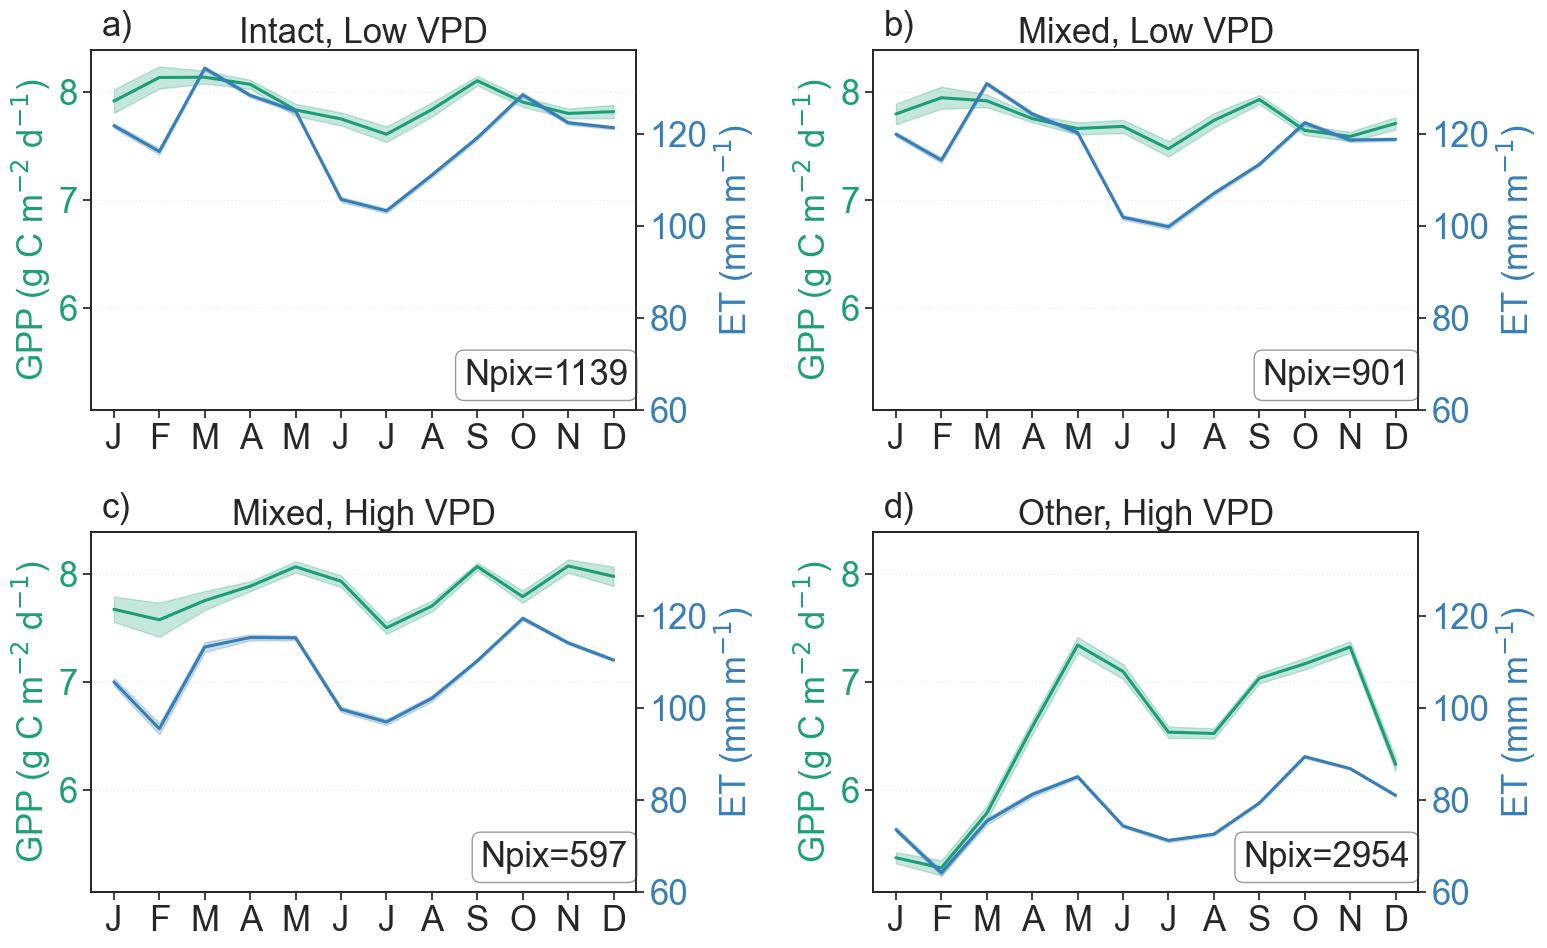

In [25]:
OUTPNG = "/Users/sworden/Documents/EqAfricaGPPETResults/JRCDisturbanceSeasonality_4regions.png"
VPD_THR_LINE = 5.51 

MONTH_NAMES = ["J","F","M","A","M","J","J","A","S","O","N","D"]
FONTS = {"title": 25, "axis_label": 25, "tick": 25, "npix": 25}
LINEW = 2.2
FILL_ALPHA = 0.25
GPP_COLOR = "#1b9e77"
ET_COLOR  = "#377eb8"

VPD_da = VPDFin
B_da   = JRC_static          # 0 Intact, 1 Disturbed, 2 Other, 3 Mixed
GPP_da = GPPNew
ET_da  = AET

# Congo domain
LAT1, LAT2 = -8, 8
LON1, LON2 = 8, 32

def monthly_clim_and_sem_over_years_areaweighted(da, mask_2d):
    """
    da: (time, lat, lon)
    mask_2d: (lat, lon) boolean
    Returns (mean_12, sem_12) over years for each month (area-weighted).
    """
    if "time" not in da.dims:
        raise ValueError("DataArray must have a 'time' dimension.")

    # apply mask
    da_m = da.where(mask_2d)

    # area weights ~ cos(lat)
    w = np.cos(np.deg2rad(da_m["lat"]))
    w = w.broadcast_like(da_m)

    # spatial mean time series
    ts = da_m.weighted(w).mean(dim=("lat", "lon"))

    # monthly climatology + SEM across time (years)
    grp = ts.groupby("time.month")
    m = grp.mean("time", skipna=True)
    s = grp.std("time", skipna=True)
    n = grp.count("time")
    se = s / np.sqrt(n)

    # ensure months 1..12 present/order
    m  = m.reindex(month=np.arange(1, 13))
    se = se.reindex(month=np.arange(1, 13))

    return m.values.astype(float), se.values.astype(float)

def plot_season_panel(ax, region_label, npix, gpp_mean, gpp_sem, et_mean, et_sem,
                      gpp_color=GPP_COLOR, et_color=ET_COLOR):
    x = np.arange(12)

    ax.set_title(f"{region_label}", fontsize=FONTS["title"], pad=4)
    ax.set_xlim(-0.5, 11.5)
    ax.set_xticks(x)
    ax.set_xticklabels(MONTH_NAMES, fontsize=FONTS["tick"])
    ax.grid(True, axis='y', linestyle=':', alpha=0.3, zorder=0)

    # GPP
    ax.plot(x, gpp_mean, color=gpp_color, lw=LINEW, zorder=5)
    ax.fill_between(x, gpp_mean - gpp_sem, gpp_mean + gpp_sem,
                    color=gpp_color, alpha=FILL_ALPHA, zorder=5)
    ax.set_ylabel(r'GPP (g C m$^{-2}$ d$^{-1}$)', color=gpp_color, fontsize=FONTS["axis_label"])
    ax.tick_params(axis='y', labelcolor=gpp_color, labelsize=FONTS["tick"])

    #ET (right)
    ax2 = ax.twinx()
    ax2.plot(x, et_mean, color=et_color, lw=LINEW, zorder=4)
    ax2.fill_between(x, et_mean - et_sem, et_mean + et_sem,
                     color=et_color, alpha=FILL_ALPHA, zorder=4)
    ax2.set_ylabel(r'ET (mm m$^{-1}$)', color=et_color, fontsize=FONTS["axis_label"])
    ax2.tick_params(axis='y', labelcolor=et_color, labelsize=FONTS["tick"])

    # Npix
    ax.text(
        0.985, 0.05, f"Npix={npix}",
        transform=ax.transAxes, ha='right', va='bottom',
        fontsize=FONTS["npix"],
        bbox=dict(facecolor='white', alpha=0.8, edgecolor='0.5', boxstyle='round,pad=0.25')
    )
    return ax, ax2

VPD_da = _ensure_latlon(VPD_da).sel(lat=slice(LAT1, LAT2), lon=slice(LON1, LON2))
B_da   = _ensure_latlon(B_da).sel(lat=slice(LAT1, LAT2), lon=slice(LON1, LON2))
GPP_da = _ensure_latlon(GPP_da).sel(lat=slice(LAT1, LAT2), lon=slice(LON1, LON2))
ET_da  = _ensure_latlon(ET_da).sel(lat=slice(LAT1, LAT2), lon=slice(LON1, LON2))

# make bucket & VPD spatial-only 
VPD_sp = _drop_time_if_present(VPD_da)
B_sp   = _drop_time_if_present(B_da)

# align all on common lat/lon
GPP2, ET2, VPD2, B2 = xr.align(GPP_da, ET_da, VPD_sp, B_sp, join="inner")

# DEFINE THE 4 REGION MASKS 
valid_sp = np.isfinite(VPD2) & np.isfinite(B2)

is_intact = (B2 == 0)
is_mixed  = (B2 == 3)
is_other  = (B2 == 2)

lowV  = (VPD2 <  VPD_THR_LINE)
highV = (VPD2 >= VPD_THR_LINE)

region_masks = {
    "Intact, Low VPD":      (is_intact & lowV  & valid_sp),
    "Mixed, Low VPD":       (is_mixed  & lowV  & valid_sp),
    "Mixed, High VPD":      (is_mixed  & highV & valid_sp),
    "Other, High VPD":      (is_other  & highV & valid_sp),
}

region_order = ["Intact, Low VPD", "Mixed, Low VPD", "Mixed, High VPD", "Other, High VPD"]

results = {}
gpp_min, gpp_max = np.inf, -np.inf
et_min,  et_max  = np.inf, -np.inf

for name in region_order:
    msk = region_masks[name].fillna(False)
    npix = int(msk.sum().item())

    gpp_mean, gpp_sem = monthly_clim_and_sem_over_years_areaweighted(GPP2, msk)
    et_mean,  et_sem  = monthly_clim_and_sem_over_years_areaweighted(ET2,  msk)

    results[name] = dict(npix=npix, gpp_mean=gpp_mean, gpp_sem=gpp_sem, et_mean=et_mean, et_sem=et_sem)

    if np.isfinite(gpp_mean).any():
        gpp_min = min(gpp_min, np.nanmin(gpp_mean - gpp_sem))
        gpp_max = max(gpp_max, np.nanmax(gpp_mean + gpp_sem))
    if np.isfinite(et_mean).any():
        et_min  = min(et_min,  np.nanmin(et_mean  - et_sem))
        et_max  = max(et_max,  np.nanmax(et_mean  + et_sem))

gpp_pad = 0.05 * (gpp_max - gpp_min) if np.isfinite(gpp_max - gpp_min) else 0.0
et_pad  = 0.05 * (et_max  - et_min)  if np.isfinite(et_max  - et_min)  else 0.0

# PLOT: 2x2 (a–d)
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.ravel()
letters = list(string.ascii_lowercase)

gpp_axes, et_axes = [], []

for i, name in enumerate(region_order):
    ax = axes[i]
    r = results[name]

    axL, axR = plot_season_panel(
        ax, name, r["npix"],
        r["gpp_mean"], r["gpp_sem"],
        r["et_mean"],  r["et_sem"],
    )

    axL.text(0.02, 1.02, f"{letters[i]})", transform=axL.transAxes,
             fontsize=FONTS["title"], va="bottom", ha="left")

    gpp_axes.append(axL)
    et_axes.append(axR)

# shared y-lims across all 4 panels
for axL in gpp_axes:
    if np.isfinite(gpp_min) and np.isfinite(gpp_max):
        axL.set_ylim(gpp_min - gpp_pad, gpp_max + gpp_pad)
for axR in et_axes:
    if np.isfinite(et_min) and np.isfinite(et_max):
        axR.set_ylim(et_min - et_pad, et_max + et_pad)

plt.tight_layout()
plt.savefig("/Users/sworden/Documents/EqAfricaGPPETResults/FigureS5.png", dpi=300, bbox_inches="tight")
plt.show()


### Supplementary Figure 6

In [26]:
file='/Users/sworden/Downloads/AfricaDEM.tif'

tif=gdal.Open(file)
lats, lons = gdal_latlon(tif)
# --- 2) Read the raster into a 2D NumPy array ---
# if multi‐band, pick band 1; here SRTM is single‐band
band = tif.GetRasterBand(1)
arr  = band.ReadAsArray()   # shape = (ny, nx)

# --- 3) Wrap into an xarray.DataArray ---
dem = xr.DataArray(
    arr,
    dims=('lat','lon'),
    coords={
        'lat': lats,
        'lon': lons
    },
    name='elevation',
    attrs={
        'units': 'm',
        'crs': tif.GetProjection()
    }
)

demNew=dem.interp(lat=VPDArr.lat,lon=VPDArr.lon)
demNew=demNew.where(demNew>=0)


In [27]:
# ET in kg m-2 s-1 for conductance calculation
AET_G = AET.sel(lat=slice(-15, 10), lon=slice(0, 35))
seconds_per_month = AET_G.time.dt.days_in_month * 24 * 3600
AET_si = AET_G / seconds_per_month
AET_si.name = "et_kg_m2_s"
AET_si.attrs["units"] = "kg m-2 s-1"

ETsi_R1 = AET_si.sel(lat=slice(3.5, 7), lon=slice(8, 30)).where(TrendArr > 0)
ETsi_R2 = AET_si.sel(lat=slice(-8, 0), lon=slice(15, 30)).where(TrendArr > 0)
ETsi_R3 = AET_si.sel(lat=slice(-5, 5), lon=slice(8, 30)).where(TrendArr <= 0)


In [28]:
TArrFin=TArr.sel(lat=slice(-15,10), lon=slice(0, 35))
TR1=TArrFin.sel(lat=slice(3.5,7),lon=slice(8, 30)).where(TrendArr>0)
TR2=TArrFin.sel(lat=slice(-8,0),lon=slice(15,30)).where(TrendArr>0)
TR3=TArrFin.sel(lat=slice(-5,5),lon=slice(8,30)).where(TrendArr<=0)
VPDArrFin=VPDArr.sel(lat=slice(-15,10), lon=slice(0, 35))*0.1 #Convert from hPa to kPa
VPDR1=VPDArrFin.sel(lat=slice(3.5,7),lon=slice(8, 30)).where(TrendArr>0)
VPDR2=VPDArrFin.sel(lat=slice(-8,0),lon=slice(15,30)).where(TrendArr>0)
VPDR3=VPDArrFin.sel(lat=slice(-5,5),lon=slice(8,30)).where(TrendArr<=0)
demNewFin=demNew.sel(lat=slice(-15,10),lon=slice(0,35))
demR1=demNewFin.sel(lat=slice(3.5,7),lon=slice(8, 30)).where(TrendArr>0)
demR2=demNewFin.sel(lat=slice(-8,0),lon=slice(15,30)).where(TrendArr>0)
demR3=demNewFin.sel(lat=slice(-5,5),lon=slice(8,30)).where(TrendArr<=0)

In [29]:
P1 = (115.8+0.4236*np.array(TArrFin))*AET_si/(np.array(VPDArrFin))

In [30]:
n=44.6
T0=273
P2=T0/(T0+np.array(TArrFin))
P3=np.exp(-.00012*np.array(demNewFin))

In [31]:
G=P1*n*P2*P3
GR1=G.sel(lat=slice(3.5,7),lon=slice(8, 30)).where(TrendArr>0)
GR2=G.sel(lat=slice(-8,0),lon=slice(15,30)).where(TrendArr>0)
GR3=G.sel(lat=slice(-5,5),lon=slice(8,30)).where(TrendArr<=0)




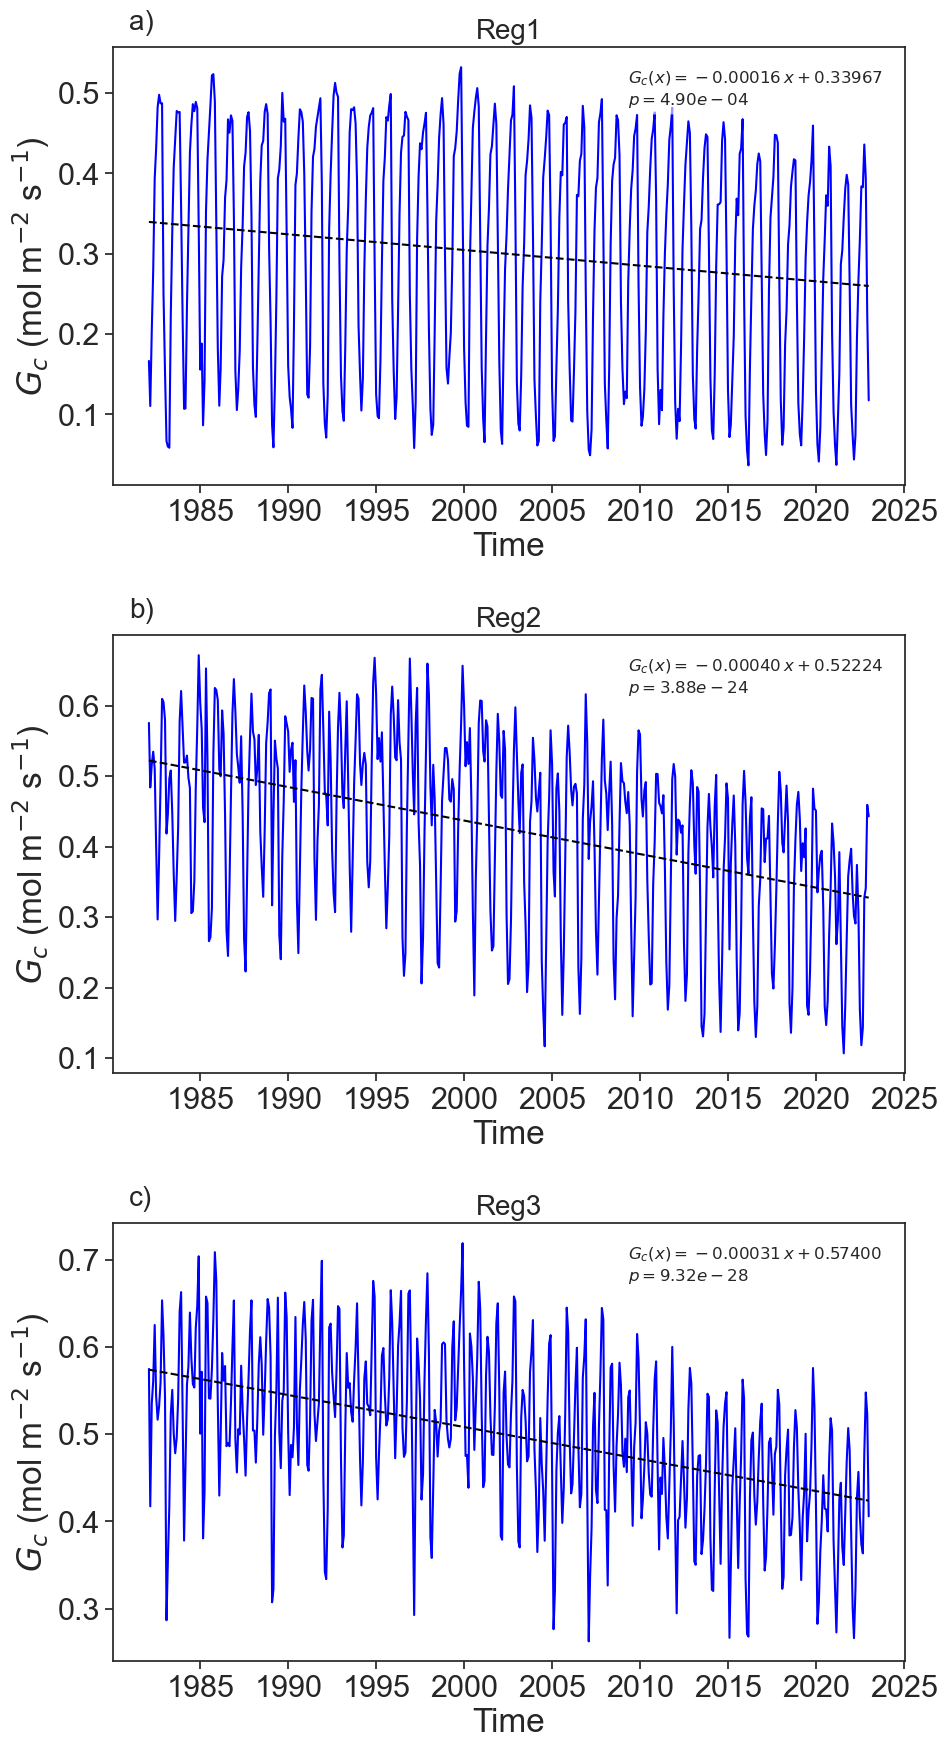

In [32]:


fig, axes = plt.subplots(3, 1, figsize=(10, 18))
regions = [
    (GR1, 'Reg1', 'a)'),
    (GR2,   'Reg2',   'b)'),
    (GR3,     'Reg3',     'c)')
]

# Custom positions for each panel’s equation box (axes fraction)
eqn_positions = [
    (0.65, 0.95),  # panel a
    (0.65, 0.95),  # panel b
    (0.65, 0.95),  # panel c
]

for (ax, (data, title, letter), (xp, yp)) in zip(axes, regions, eqn_positions):
    ts = data.mean(axis=(1,2)).values
    times = data.time.values

    # fit trend
    x = np.arange(len(ts))
    slope, intercept, r, pval, se = linregress(x, ts)
    trend = intercept + slope * x

    # plot data + trend
    ax.plot(times, ts, color='blue')
    ax.plot(times, trend, '--', color='black', label='Trend')

    # build equation string
    eqn = (
        rf"$G_c (x) = {slope:.5f}\,x {'+' if intercept>=0 else '-'} {abs(intercept):.5f}$"
        "\n" rf"$p = {pval:.2e}$"
    )

    # place text with semi‐opaque white fill, no edge
    ax.text(
        xp, yp, eqn,
        transform=ax.transAxes,
        fontsize=12,
        va='top', ha='left',
        bbox=dict(
            boxstyle="round,pad=0.3",
            facecolor=(1,1,1,0.6),
            edgecolor='none'
        )
    )

    # styling
    ax.set_title(title, loc='center', fontsize=20)
    ax.set_ylabel(r'$G_c$ (mol m$^{-2}$ s$^{-1}$)')
    ax.set_xlabel('Time')
    ax.text(
        0.02, 1.04, letter,
        transform=ax.transAxes,
        fontsize=20
    )

plt.tight_layout()
plt.savefig(
    '/Users/sworden/Documents/EqAfricaGPPETResults/FigureS6.png',
    bbox_inches='tight'
)
plt.show()


### Supplementary Figures 7-9

In [33]:
#helpers
def _as_month_start(da: xr.DataArray) -> xr.DataArray:
    ts = pd.to_datetime(da.time.values).to_period("M").to_timestamp(how="start")
    return da.assign_coords(time=ts).sortby("time")

def _spatial_mean(da: xr.DataArray) -> xr.DataArray:
    dims = [d for d in ("lat","lon","y","x","latitude","longitude") if d in da.dims]
    return da.mean(dim=dims, skipna=True) if dims else da

def detrend_keep_mean_1d(da: xr.DataArray) -> xr.DataArray:
    """Detrend a 1D (time) series, keep mean."""
    y = da.values.astype(float)
    m = np.isfinite(y)
    if m.sum() < 3:
        return da * np.nan

    # numeric time in years 
    dti = pd.DatetimeIndex(pd.to_datetime(da.time.values))
    days = (dti.asi8 // 86_400_000_000_000).astype(float)  # ns -> days
    days -= days[0]
    t = days / 365.25

    A = np.vstack([t[m], np.ones(m.sum())]).T
    a, b = np.linalg.lstsq(A, y[m], rcond=None)[0]
    trend = a * t + b
    y_detr = y - trend + np.nanmean(y[m])

    return xr.DataArray(y_detr, coords=da.coords, dims=da.dims, name=(da.name or "detrended"))

def G_from_inputs(ET_si, VPD_kPa, T_C, DEM, n=44.6, T0=273.0, eps=1e-6):
    """
    Pixelwise canopy conductance-like quantity:
      ET [kg m-2 s-1], VPD [kPa], T [°C], DEM [m]
    """
    # month-start + strict alignment (label-based)
    ET_si   = _as_month_start(ET_si)
    VPD_kPa = _as_month_start(VPD_kPa)
    T_C     = _as_month_start(T_C)

    ET_si, VPD_kPa, T_C = xr.align(ET_si, VPD_kPa, T_C, join="inner")

    # DEM: broadcast to (time,lat,lon)
    if "time" in DEM.dims:
        DEM = DEM.sel(time=ET_si.time)
    else:
        DEM = DEM.broadcast_like(ET_si)

    # guard VPD
    VPD_kPa = xr.where(VPD_kPa > eps, VPD_kPa, np.nan)

    P1 = (115.8 + 0.4236 * T_C) * ET_si / VPD_kPa
    P2 = T0 / (T0 + T_C)
    P3 = np.exp(-0.00012 * DEM)

    return (P1 * n * P2 * P3).rename("G")

def _plot_one_driver(ax_left, ax_right, time, drv_orig, drv_detr, G_base, G_cf, driver_label, vlines=None):
    ax_left.plot(time, drv_orig, lw=1.8, label="original")
    ax_left.plot(time, drv_detr, lw=1.8, label="detrended")
    ax_left.grid(True, ls=":", alpha=0.4)

    ax_right.plot(time, G_base, lw=1.8, label="original")
    ax_right.plot(time, G_cf, lw=1.8, label=f"detrended {driver_label}")
    ax_right.grid(True, ls=":", alpha=0.4)

    for v in (vlines or []):
        ax_left.axvline(np.datetime64(v), ls=":", lw=1, color="k", alpha=0.7)
        ax_right.axvline(np.datetime64(v), ls=":", lw=1, color="k", alpha=0.7)

#main
def plot_driver_and_G_with_detrend_pixelwise(
    ET_field, VPD_field, T_field, DEM_field,
    region_title="",
    vlines=("1998-01-01","2005-01-01","2015-01-01"),
):
    """
    Baseline: compute G pixelwise then spatial-mean.
    Counterfactuals: detrend the *spatial-mean* driver, then apply that
    detrended signal back to the full field and recompute pixelwise G.
    """
    # month-start + align all three
    ET_field  = _as_month_start(ET_field)
    VPD_field = _as_month_start(VPD_field)
    T_field   = _as_month_start(T_field)

    ET_field, VPD_field, T_field = xr.align(ET_field, VPD_field, T_field, join="inner")
    if ET_field.sizes.get("time", 0) == 0:
        raise ValueError("Empty time overlap after alignment. Check ET/VPD/T time coords.")

    # baseline G pixelwise -> spatial mean
    G_map = G_from_inputs(ET_field, VPD_field, T_field, DEM_field, T0=273.0)
    G0 = _spatial_mean(G_map)

    # spatial-mean drivers (for detrending signal)
    ETs  = _spatial_mean(ET_field)
    VPDs = _spatial_mean(VPD_field)
    Ts   = _spatial_mean(T_field)

    # detrend 1D time series
    ET_d  = detrend_keep_mean_1d(ETs)
    VPD_d = detrend_keep_mean_1d(VPDs)
    T_d   = detrend_keep_mean_1d(Ts)

    # apply detrended signals back to full fields
    # ET, VPD: multiplicative scaling (preserves spatial pattern)
    ET_ratio  = (ET_d / ETs).broadcast_like(ET_field)
    VPD_ratio = (VPD_d / VPDs).broadcast_like(VPD_field)

    ET_cf  = ET_field * ET_ratio
    VPD_cf = VPD_field * VPD_ratio

    # T: additive offset (preserves spatial anomalies)
    T_offset = (T_d - Ts).broadcast_like(T_field)
    T_cf = T_field + T_offset

    # recompute G pixelwise for each counterfactual -> spatial mean
    G_VPDd = _spatial_mean(G_from_inputs(ET_field, VPD_cf, T_field, DEM_field, T0=273.0))
    G_ETd  = _spatial_mean(G_from_inputs(ET_cf,  VPD_field, T_field, DEM_field, T0=273.0))
    G_Td   = _spatial_mean(G_from_inputs(ET_field, VPD_field, T_cf,  DEM_field, T0=273.0))

    time = G0.time.values

    # plot
    fig, axes = plt.subplots(3, 2, figsize=(14, 11), sharex=True)
    (ax_vpd_L, ax_vpd_R), (ax_et_L, ax_et_R), (ax_t_L, ax_t_R) = axes

    _plot_one_driver(ax_vpd_L, ax_vpd_R, time, VPDs.values, VPD_d.values, G0.values, G_VPDd.values, "VPD", vlines=vlines)
    ax_vpd_L.set_ylabel("VPD (kPa)")
    ax_vpd_R.set_ylabel("G")

    _plot_one_driver(ax_et_L, ax_et_R, time, ETs.values, ET_d.values, G0.values, G_ETd.values, "ET", vlines=vlines)
    ax_et_L.set_ylabel("ET (kg m$^{-2}$ s$^{-1}$)")
    ax_et_R.set_ylabel("G")

    _plot_one_driver(ax_t_L, ax_t_R, time, Ts.values, T_d.values, G0.values, G_Td.values, "T", vlines=vlines)
    ax_t_L.set_ylabel("T (°C)")
    ax_t_R.set_ylabel("G")

    # labels
    labels = ['a)', 'b)', 'c)', 'd)', 'e)', 'f)']
    for lab, ax in zip(labels, axes.flatten()):
        ax.text(0.01, 0.85, lab, transform=ax.transAxes, fontsize=20, fontweight='normal')

    # legends
    handles, lbls = ax_vpd_L.get_legend_handles_labels()
    fig.legend(handles, lbls, loc="upper center", bbox_to_anchor=(0.28, 0.95), ncol=2, frameon=False)

    handles, lbls = ax_vpd_R.get_legend_handles_labels()
    fig.legend(handles, lbls, loc="upper center", bbox_to_anchor=(0.74, 0.95), ncol=2, frameon=False)

    # x tick rotation
    for ax in axes[-1, :]:
        ax.set_xlabel("time")
        ax.tick_params(axis='x', labelrotation=45)
        for lbl in ax.get_xticklabels():
            lbl.set_ha('right')

    fig.suptitle(region_title, y=0.995, fontsize=20)
    fig.tight_layout(rect=[0, 0, 1, 0.97])

    print(f"\n[{region_title}] Mean ΔG from detrending (spatial-mean signal applied to field):")
    print(f"  VPD detrended: {float(np.nanmean(G_VPDd - G0)):+.4g}")
    print(f"  ET  detrended: {float(np.nanmean(G_ETd  - G0)):+.4g}")
    print(f"  T   detrended: {float(np.nanmean(G_Td   - G0)):+.4g}")

    return fig, dict(G_baseline=G0, G_VPD_detr=G_VPDd, G_ET_detr=G_ETd, G_T_detr=G_Td)





[Reg1] Mean ΔG from detrending (spatial-mean signal applied to field):
  VPD detrended: -7.844e-05
  ET  detrended: -0.0002805
  T   detrended: -3.59e-08


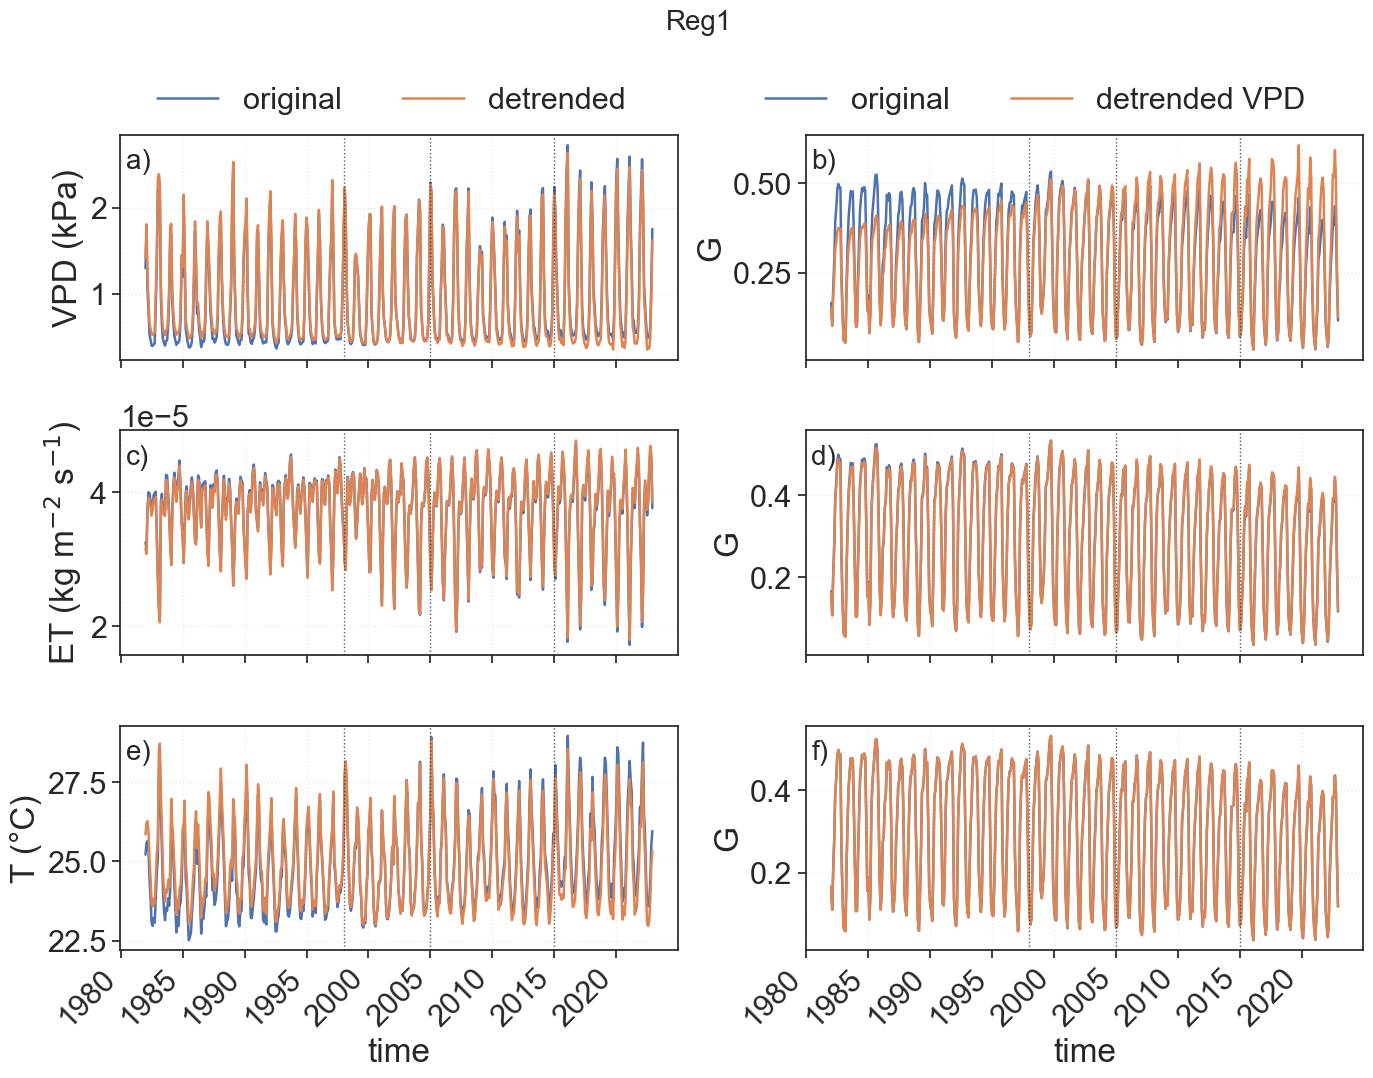


[Reg2] Mean ΔG from detrending (spatial-mean signal applied to field):
  VPD detrended: -0.004903
  ET  detrended: -0.0007372
  T   detrended: -9.767e-08


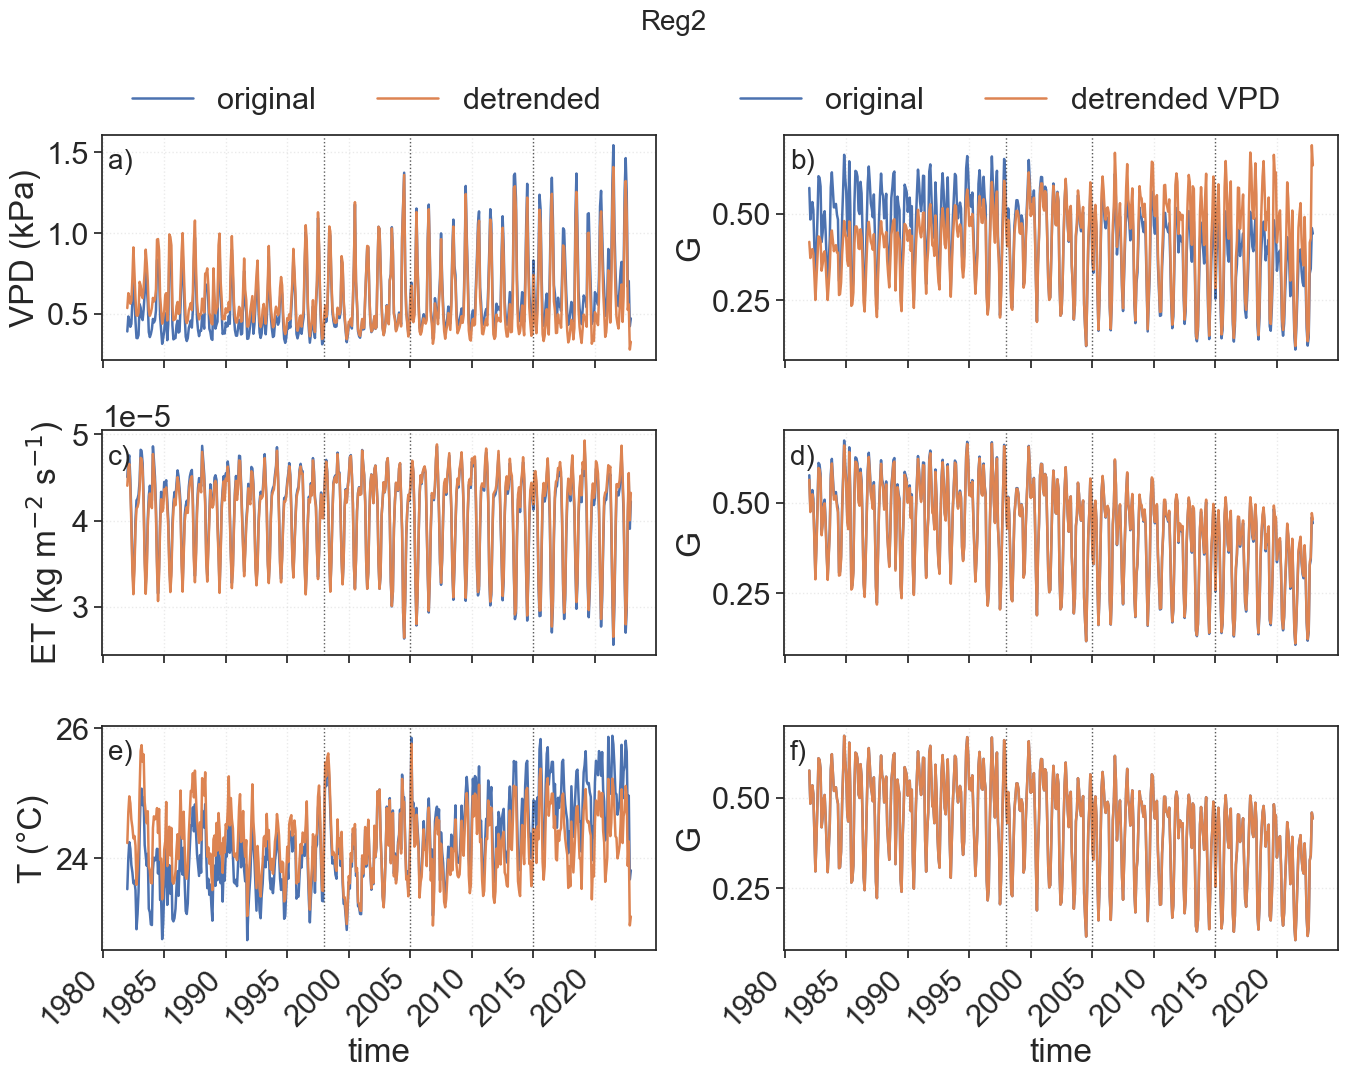


[Reg3] Mean ΔG from detrending (spatial-mean signal applied to field):
  VPD detrended: -0.003768
  ET  detrended: +1.388e-05
  T   detrended: -7.001e-08


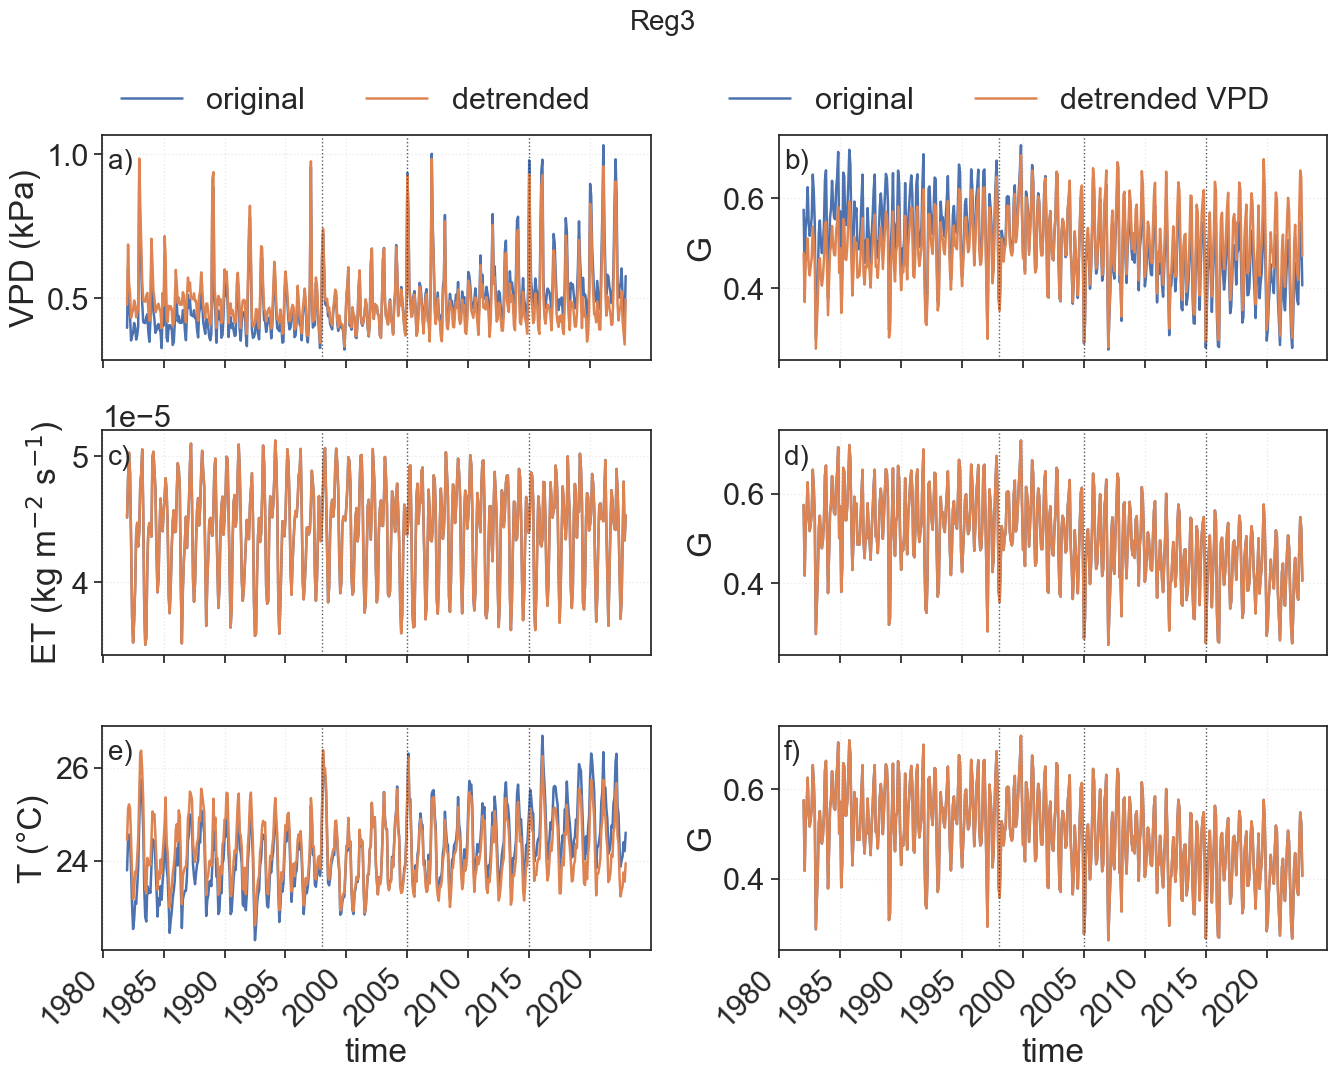

In [34]:
for region, ET_reg, VPD_reg, T_reg, DEM_reg in [
    ("Reg1", ETsi_R1, VPDR1, TR1, demR1),
    ("Reg2", ETsi_R2, VPDR2, TR2, demR2),
    ("Reg3", ETsi_R3, VPDR3, TR3, demR3),
]:
    fig, out = plot_driver_and_G_with_detrend_pixelwise(
        ET_reg, VPD_reg, T_reg, DEM_reg, region_title=region
    )
    fig.savefig(
        f"/Users/sworden/Documents/EqAfricaGPPETResults/G_detrend_{region}.png",
        dpi=300, bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)


### Supplementary Figure 10

Loaded Guo 2001
Loaded Guo 2002
Loaded Guo 2003
Loaded Guo 2004
Loaded Guo 2005
Loaded Guo 2006
Loaded Guo 2007
Loaded Guo 2008
Loaded Guo 2009
Loaded Guo 2010
Loaded Guo 2011
Loaded Guo 2012
Loaded Guo 2013
Loaded Guo 2014
Loaded Guo 2015
Loaded Guo 2016
Loaded Guo 2017
Loaded Guo 2018
Loaded Guo 2019
Common months: 228 (2001-01-01 to 2019-12-01)
Valid observations: [1286496, 1288656, 1281308]

Intact_LowVPD: 243,276 pixel-months, 1,067 pixels; all ETC valid=True
  GuoGPP   mean=7.092, ETC sigma=0.408, ETC R²=0.656
  BiGPP    mean=9.243, ETC sigma=0.656, ETC R²=0.311
  GPPMad   mean=7.909, ETC sigma=1.013, ETC R²=0.238

Mixed_LowVPD: 188,328 pixel-months, 826 pixels; all ETC valid=True
  GuoGPP   mean=6.681, ETC sigma=0.473, ETC R²=0.768
  BiGPP    mean=8.842, ETC sigma=0.805, ETC R²=0.573
  GPPMad   mean=7.659, ETC sigma=1.026, ETC R²=0.354

Mixed_HighVPD: 151,848 pixel-months, 666 pixels; all ETC valid=True
  GuoGPP   mean=6.108, ETC sigma=0.419, ETC R²=0.856
  BiGPP    mean=8.369, 

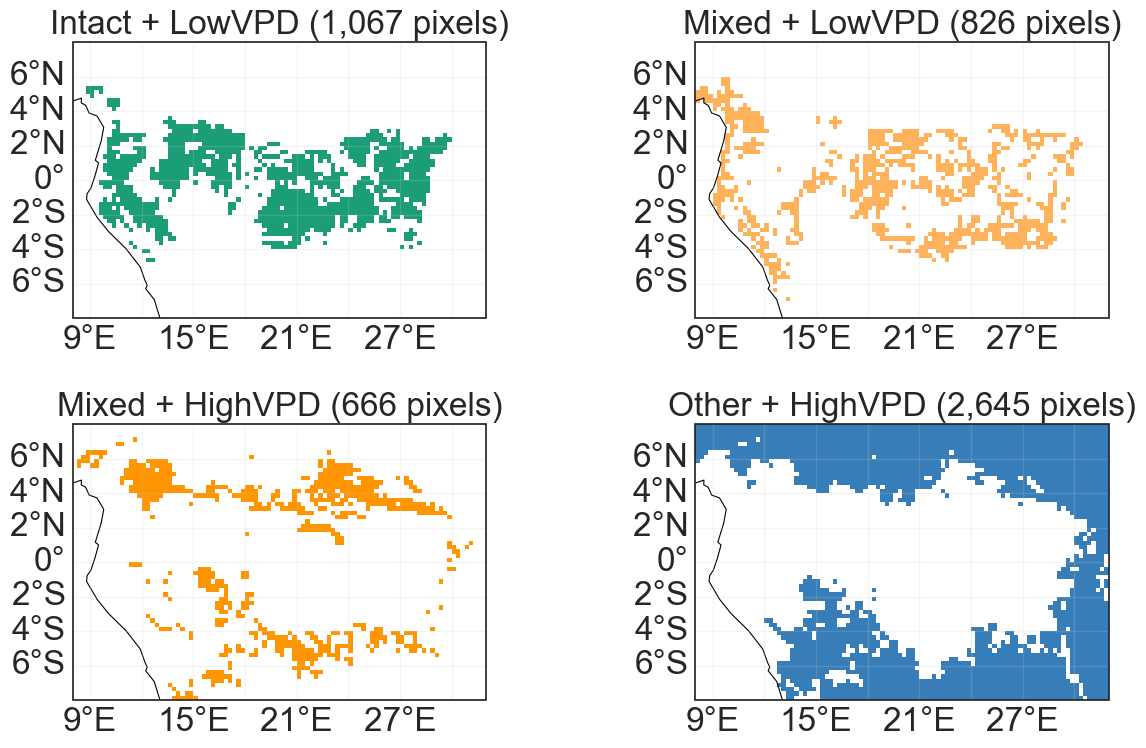

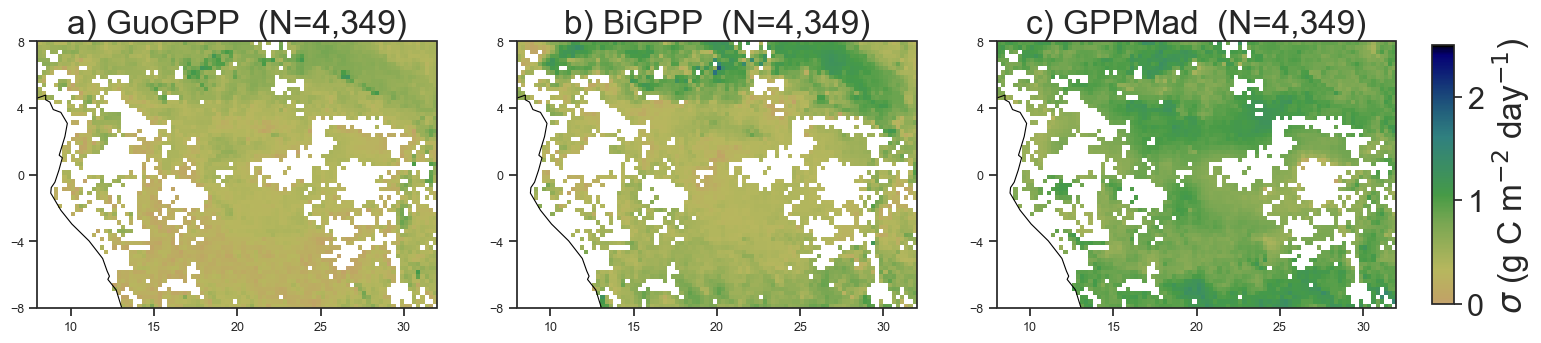

Saved Table S4, ETC selection map, Figure S10 and sigma NetCDF to: C:\Users\sworden\Documents\EqAfricaGPPETResults


In [48]:
# Guo + Bi + Madani GPP: pooled ETC, four vegetation-VPD masks, and updated maps.
# Run after the notebook has defined GPPFinArr, bucket4, VPDFin and VPD_star.
import re
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
from osgeo import gdal

GUO_DIR = Path.home() / "Documents" / "GuoGPP"
BI_DIR = Path.home() / "Documents" / "BiSunShadeGPP"
OUTDIR = Path.home() / "Documents" / "EqAfricaGPPETResults"
OUTDIR.mkdir(parents=True, exist_ok=True)
GUO_NORTH_FIRST = True  # Retain the orientation used for your successful Guo load; verify geographically
GUO_LON_START = -180
MIN_ETC_MONTHS = 24

# LOAD MADANI AND BI (monthly mean daily GPP, g C m-2 day-1)
GPPMad = GPPFinArr.copy()
bi_files = sorted(BI_DIR.glob("GPP*.tif"), key=lambda p: tuple(map(int, p.stem.split("_")[-2:])))
if not bi_files: raise FileNotFoundError(f"No Bi GPP TIFF files in {BI_DIR}")
bi_dates = pd.DatetimeIndex([pd.Timestamp(year=int(f.stem.split("_")[-2]), month=int(f.stem.split("_")[-1]), day=1) for f in bi_files])
if bi_dates.has_duplicates or not bi_dates.equals(pd.date_range(bi_dates[0], bi_dates[-1], freq="MS")):
    raise ValueError("Bi GPP filenames contain missing or duplicated monthly dates")

def gdal_latlon_centers(ds):
    gt = ds.GetGeoTransform()
    return gt[3] + (np.arange(ds.RasterYSize) + 0.5)*gt[5], gt[0] + (np.arange(ds.RasterXSize) + 0.5)*gt[1]

ds = gdal.Open(str(bi_files[0])); lats, lons = gdal_latlon_centers(ds); ds = None
lat_keep, lon_keep = (lats > -15) & (lats < 10), (lons > 0) & (lons < 35)
bi_arr = np.empty((len(bi_files), int(lat_keep.sum()), int(lon_keep.sum())), dtype="float32")
for i, file in enumerate(bi_files):
    ds = gdal.Open(str(file))
    raw = ds.ReadAsArray()[lat_keep][:, lon_keep].astype("float32")
    bi_arr[i] = raw * 0.1 / bi_dates[i].days_in_month
    ds = None
BiGPP = xr.DataArray(bi_arr, dims=("time", "lat", "lon"), coords={"time": bi_dates, "lat": lats[lat_keep], "lon": lons[lon_keep]})
BiGPP = BiGPP.where(BiGPP > 0).sortby("lat").sortby("lon")
del bi_arr

# TARGET GRID: ORIGINAL JRC/VPD 0.25-DEGREE DOMAIN
B = bucket4.sortby("lat").sortby("lon")
V = VPDFin.sortby("lat").sortby("lon")
if "time" in B.dims: B = B.squeeze("time", drop=True)
if "time" in V.dims: V = V.squeeze("time", drop=True)
B, V = xr.align(B, V, join="inner")
B = B.sel(lat=slice(-8, 8), lon=slice(8, 32)); V = V.sel(lat=B.lat, lon=B.lon)
if not B.sizes["lat"] or not B.sizes["lon"]: raise ValueError("Empty JRC/VPD target grid")
if not np.isfinite(VPD_star): raise ValueError("VPD_star must be calculated before ETC")

group_masks = {
    "Intact_LowVPD": (B == 0) & (V < VPD_star),
    "Mixed_LowVPD": (B == 3) & (V < VPD_star),
    "Mixed_HighVPD": (B == 3) & (V >= VPD_star),
    "Other_HighVPD": (B == 2) & (V >= VPD_star)
}

def grid_edges(v):
    a = np.asarray(v, float)
    return np.r_[a[0] - (a[1]-a[0])/2, (a[:-1]+a[1:])/2, a[-1] + (a[-1]-a[-2])/2]

def aggregate_to_grid(da, target):
    """Approximate latitude-area-weighted mean of fine pixel centers in each 0.25-degree cell."""
    da = da.sortby("lat").sortby("lon")
    lat, lon = target.lat.values, target.lon.values
    le, oe = grid_edges(lat), grid_edges(lon)
    da = da.where((da.lat >= le[0]) & (da.lat < le[-1]), drop=True)
    da = da.where((da.lon >= oe[0]) & (da.lon < oe[-1]), drop=True)
    if da.sizes["lat"] == 0 or da.sizes["lon"] == 0: raise ValueError("No overlap with the 0.25-degree grid")
    iy = np.searchsorted(le, da.lat.values, side="right") - 1
    ix = np.searchsorted(oe, da.lon.values, side="right") - 1
    da = da.assign_coords(cell_lat=("lat", lat[iy]), cell_lon=("lon", lon[ix]))
    weights = xr.DataArray(np.cos(np.deg2rad(da.lat.values)), dims="lat", coords={"lat": da.lat})
    numer = (da.fillna(0) * weights).groupby("cell_lat").sum("lat").groupby("cell_lon").sum("lon")
    denom = (da.notnull() * weights).groupby("cell_lat").sum("lat").groupby("cell_lon").sum("lon")
    return (numer / denom).rename({"cell_lat": "lat", "cell_lon": "lon"}).reindex(lat=lat, lon=lon).transpose("time", "lat", "lon")

def assign_guo_coords(da):
    if da.sizes["lat"] != 3600 or da.sizes["lon"] != 7200:
        raise ValueError(f"Unexpected Guo dimensions: {dict(da.sizes)}")
    lat = 90 - (np.arange(3600) + 0.5)*0.05 if GUO_NORTH_FIRST else -90 + (np.arange(3600) + 0.5)*0.05
    lon = GUO_LON_START + (np.arange(7200) + 0.5)*0.05
    return da.assign_coords(lat=("lat", lat), lon=("lon", lon))

def load_guo(folder, target):
    files = sorted(folder.glob("ECGC_GPP_monthly_005_*.nc"))
    if not files: raise FileNotFoundError(f"No ECGC-GPP NetCDF files in {folder}")
    le, oe = grid_edges(target.lat.values), grid_edges(target.lon.values)
    pieces = []
    for file in files:
        year = int(file.stem.split("_")[-1])
        with xr.open_dataset(file, mask_and_scale=False, decode_times=False) as ds:
            da = assign_guo_coords(ds["GPP"])
            if da.sizes["time"] != 12: raise ValueError(f"Expected 12 months in {file.name}")
            da = da.where((da.lat >= le[0]) & (da.lat < le[-1]), drop=True)
            da = da.where((da.lon >= oe[0]) & (da.lon < oe[-1]), drop=True)
            da = da.assign_coords(time=pd.date_range(f"{year}-01-01", periods=12, freq="MS"))
            da = da.transpose("time", "lat", "lon").sortby("lat").sortby("lon")
            da = da.where((da != -9999) & (da >= 0)).astype("float32") * 0.001
            pieces.append(aggregate_to_grid(da, target).load())
        print(f"Loaded Guo {year}")
    return xr.concat(pieces, dim="time").sortby("time")

# ALIGN GUO, BI AND MADANI ON SAME GRID AND MONTHS
GuoGPP_aligned = load_guo(GUO_DIR, B)
start, end = str(GuoGPP_aligned.time.values[0])[:10], str(GuoGPP_aligned.time.values[-1])[:10]
BiGPP_aligned = aggregate_to_grid(BiGPP.sel(time=slice(start, end)), B)
GPPMad_aligned = aggregate_to_grid(GPPMad.resample(time="MS").mean().sel(time=slice(start, end)), B)
common = GuoGPP_aligned.time.to_index().intersection(BiGPP_aligned.time.to_index()).intersection(GPPMad_aligned.time.to_index())
if not len(common): raise ValueError("Guo, Bi and Madani have no common months")
g1, g2, g3 = xr.align(*(da.sel(time=common) for da in (GuoGPP_aligned, BiGPP_aligned, GPPMad_aligned)), join="exact")
products = ["GuoGPP", "BiGPP", "GPPMad"]
print(f"Common months: {len(common)} ({common.min().date()} to {common.max().date()})")
print("Valid observations:", [int(da.notnull().sum()) for da in (g1, g2, g3)])
if not all(int(da.notnull().sum()) for da in (g1, g2, g3)):
    raise ValueError("A GPP product has no valid observations; verify Guo latitude/longitude orientation")

def calc_etc(A):
    """ETC error std. deviation and R² from the 3x3 sample covariance matrix."""
    C = np.cov(A, rowvar=False)
    with np.errstate(divide="ignore", invalid="ignore"):
        r2 = np.array([C[0,1]*C[0,2]/(C[0,0]*C[1,2]), C[0,1]*C[1,2]/(C[1,1]*C[0,2]), C[0,2]*C[1,2]/(C[2,2]*C[0,1])])
        errvar = np.diag(C) * (1 - r2)
    valid = np.isfinite(r2) & np.isfinite(errvar) & (r2 >= 0) & (r2 <= 1) & (errvar >= 0)
    sigma = np.where(valid, np.sqrt(np.maximum(errvar, 0)), np.nan)
    return sigma, r2, errvar, valid

# POOLED PIXEL-MONTH ETC: THE VALUES FOR TABLE S4
rows = []
for group, mask in group_masks.items():
    joint = (mask & g1.notnull() & g2.notnull() & g3.notnull()).transpose("time", "lat", "lon")
    A = np.column_stack([da.transpose("time", "lat", "lon").values[joint.values] for da in (g1, g2, g3)])
    n_pixels = int(joint.any("time").sum())
    if len(A) < 10:
        print(f"{group}: insufficient observations ({len(A)})")
        continue
    sigma, r2, errvar, valid = calc_etc(A)
    print(f"\n{group}: {len(A):,} pixel-months, {n_pixels:,} pixels; all ETC valid={bool(valid.all())}")
    for i, product in enumerate(products):
        print(f"  {product:8} mean={A[:,i].mean():.3f}, ETC sigma={sigma[i]:.3f}, ETC R²={r2[i]:.3f}")
        rows.append({"Group": group, "Product": product, "Mean GPP": A[:,i].mean(), "ETC sigma": sigma[i],
                     "ETC R2": r2[i], "ETC valid": bool(valid[i]), "N pixel-months": len(A), "N pixels": n_pixels})
summary = pd.DataFrame(rows)
summary.to_csv(OUTDIR / "Table_S4_Guo_Bi_Madani_ETC.csv", index=False)
print("\nTABLE S4: POOLED ETC (g C m-2 day-1)")
print(summary[["Group", "Product", "Mean GPP", "ETC sigma", "ETC R2", "ETC valid"]].round(3).to_string(index=False))

# SPATIAL SELECTION MAP: FOUR CATEGORIES USED IN POOLED ETC
joint_any = (g1.notnull() & g2.notnull() & g3.notnull()).any("time")
mask_colors = ["#1b9e77", "#ffb25a", "#ff9500", "#377eb8"]
fig, axes = plt.subplots(2, 2, figsize=(13, 8), subplot_kw={"projection": ccrs.PlateCarree()})
for ax, (name, mask), color in zip(axes.flat, group_masks.items(), mask_colors):
    active = mask & joint_any
    values = xr.where(active, 1.0, np.nan)
    ax.pcolormesh(B.lon, B.lat, values, cmap=mcolors.ListedColormap([color]), vmin=0, vmax=1,
                  shading="nearest", transform=ccrs.PlateCarree())
    ax.coastlines(resolution="110m", linewidth=0.8)
    ax.set_extent([8, 32, -8, 8], crs=ccrs.PlateCarree())
    ax.gridlines(draw_labels={"left": True, "bottom": True, "top": False, "right": False}, alpha=0.2)
    ax.set_title(f"{name.replace('_', ' + ')} ({int(active.sum()):,} pixels)")
fig.tight_layout()
fig.savefig(OUTDIR / "Figure_S10_ETC_categories.png", dpi=300, bbox_inches="tight")
plt.show()

# FIGURE S10: PER-PIXEL ETC SIGMA FROM MONTHLY TIME SERIES (NOT POOLED CATEGORY SIGMA)
Y = np.stack([da.values for da in (g1, g2, g3)], axis=0).astype("float64")
good_t = np.isfinite(Y).all(axis=0)
n = good_t.sum(axis=0)
X = np.where(good_t[None, ...], Y, 0)
mu = X.sum(axis=1) / np.maximum(n[None, ...], 1)
centered = np.where(good_t[None, ...], Y - mu[:, None], 0)
C = np.einsum("itxy,jtxy->ijxy", centered, centered) / np.maximum(n - 1, 1)
with np.errstate(divide="ignore", invalid="ignore"):
    rho2_map = np.stack([C[0,1]*C[0,2]/(C[0,0]*C[1,2]), C[0,1]*C[1,2]/(C[1,1]*C[0,2]), C[0,2]*C[1,2]/(C[2,2]*C[0,1])])
    errvar_map = np.stack([C[i,i] * (1 - rho2_map[i]) for i in range(3)])
valid_map = (n >= MIN_ETC_MONTHS) & np.all(np.isfinite(rho2_map) & np.isfinite(errvar_map) &
                                            (rho2_map >= 0) & (rho2_map <= 1) & (errvar_map >= 0), axis=0)
sigma_map = xr.DataArray(np.where(valid_map[None, ...], np.sqrt(np.maximum(errvar_map, 0)), np.nan),
                         dims=("product", "lat", "lon"), coords={"product": products, "lat": B.lat, "lon": B.lon}, name="ETC_sigma")
sigma_map.attrs.update(units="g C m-2 day-1", description="Per-pixel temporal ETC error standard deviation, 2001-2019")
sigma_map.to_netcdf(OUTDIR / "Figure_S10_ETC_sigma_maps.nc")

cmap_values = plt.get_cmap("gist_earth_r")(np.linspace(0.2, 1, 256))
cmap = mcolors.LinearSegmentedColormap.from_list("etc_sigma", cmap_values)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.7), subplot_kw={"projection": ccrs.PlateCarree()})
for i, (ax, name) in enumerate(zip(axes, products)):
    im = ax.pcolormesh(sigma_map.lon, sigma_map.lat, sigma_map.sel(product=name), cmap=cmap,
                       vmin=0, vmax=2.5, shading="nearest", transform=ccrs.PlateCarree())
    ax.coastlines(resolution="110m", linewidth=0.8)
    ax.set_extent([8, 32, -8, 8], crs=ccrs.PlateCarree())
    ax.set_title(f"{chr(97+i)}) {name}  (N={int(np.isfinite(sigma_map.sel(product=name)).sum()):,})")
    ax.set_xticks([10, 15, 20, 25, 30], crs=ccrs.PlateCarree())
    ax.set_yticks([-8, -4, 0, 4, 8], crs=ccrs.PlateCarree())
    ax.tick_params(labelsize=9)
fig.subplots_adjust(right=0.88, wspace=0.20)
cax = fig.add_axes([0.9, 0.22, 0.012, 0.55])
fig.colorbar(im, cax=cax, label=r"$\sigma$ (g C m$^{-2}$ day$^{-1}$)")
fig.savefig(OUTDIR / "Figure S10.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved Table S4, ETC selection map, Figure S10 and sigma NetCDF to:", OUTDIR)


### Table S3

In [52]:
# TABLE S3: GPP–ET CORRELATIONS (GUO, BI, MADANI x GLEAM, GLDAS)
# Run after Supplementary Figure 10 / Table S4 cell defines g1, g2, g3, B, group_masks, OUTDIR.
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr

GLDAS_DIR = Path('D:/GLDASLongTermET')  # Change if the GLDAS files are elsewhere
MIN_VALID_MONTHS = 3  # Original Table S3 criterion; increase to 24 for a stricter sensitivity test

# Load monthly GLDAS ET, keeping its original geographical coordinates.
gldas_files = sorted([p for p in GLDAS_DIR.iterdir() if p.suffix.lower() in ('.nc', '.nc4')]) if GLDAS_DIR.is_dir() else []
if not gldas_files: raise FileNotFoundError(f'No GLDAS NetCDF files in {GLDAS_DIR}. Set GLDAS_DIR to the correct folder.')
ds_gldas = xr.open_mfdataset(gldas_files, concat_dim='time', combine='nested', compat='override', coords='all')
if 'Evap_tavg' not in ds_gldas: raise KeyError(f'Expected Evap_tavg in GLDAS files; found {list(ds_gldas.data_vars)}')

def monthly(da):
    rename = {k: v for k, v in {'latitude': 'lat', 'longitude': 'lon'}.items() if k in da.dims}
    if rename: da = da.rename(rename)
    return da.sortby('lat').sortby('lon').resample(time='MS').mean('time', keep_attrs=True).sortby('time')

def et_on_analysis_grid(da, target):
    da = monthly(da).sel(time=slice('2001-01-01', '2019-12-31'))
    da = da.sel(lat=slice(float(target.lat.min()) - 0.5, float(target.lat.max()) + 0.5),
                lon=slice(float(target.lon.min()) - 0.5, float(target.lon.max()) + 0.5))
    if da.sizes.get('lat', 0) < 2 or da.sizes.get('lon', 0) < 2:
        raise ValueError('ET source grid has insufficient coverage of the 0.25-degree JRC/VPD grid')
    return da.interp(lat=target.lat, lon=target.lon, method='linear').transpose('time', 'lat', 'lon')

AET_ms = et_on_analysis_grid(AET, B)  # GLEAM E (AET) from the main analysis
GLD_rate = et_on_analysis_grid(ds_gldas['Evap_tavg'], B)
unit = str(ds_gldas['Evap_tavg'].attrs.get('units', '')).lower().replace(' ', '')
if ('kg' in unit or 'mm' in unit) and ('/s' in unit or 's-1' in unit or 's^-1' in unit):
    GLD_ms = GLD_rate * (86400 * GLD_rate.time.dt.days_in_month)
    print(f'GLDAS Evap_tavg converted from {unit} to monthly totals (mm/month).')
else:
    GLD_ms = GLD_rate
    print(f'Check GLDAS Evap_tavg units: {unit or "not specified"}; no unit conversion applied.')

# Use one shared set of months for ALL six GPP–ET comparisons.
shared_time = g1.time.to_index()
for da in (g2, g3, AET_ms, GLD_ms): shared_time = shared_time.intersection(da.time.to_index())
shared_time = shared_time.sort_values()
if len(shared_time) < MIN_VALID_MONTHS: raise ValueError('Insufficient shared months among all three GPP and both ET products')
Guo_ms, Bi_ms, Mad_ms, AET_ms, GLD_ms = xr.align(
    *(da.sel(time=shared_time) for da in (g1, g2, g3, AET_ms, GLD_ms)), join='exact')
print(f'Table S3 common period: {shared_time[0].date()} to {shared_time[-1].date()} ({len(shared_time)} months)')

pairs = [('Guo–AET', Guo_ms, AET_ms), ('Bi–AET', Bi_ms, AET_ms), ('Madani–AET', Mad_ms, AET_ms),
         ('Guo–GLDAS', Guo_ms, GLD_ms), ('Bi–GLDAS', Bi_ms, GLD_ms), ('Madani–GLDAS', Mad_ms, GLD_ms)]

# Pearson R computed separately at each 0.25° pixel, then summarized within the original masks.
rows = []
for label, gpp, et in pairs:
    paired = np.isfinite(gpp) & np.isfinite(et)
    n_months = paired.sum('time')
    r = xr.corr(gpp.where(paired), et.where(paired), dim='time').where(n_months >= MIN_VALID_MONTHS)
    for group, mask in group_masks.items():
        values = np.asarray(r.where(mask).values, float)
        values = values[np.isfinite(values)]
        rows.append({'Group': group, 'Pair': label, 'Mean R': float(values.mean()) if len(values) else np.nan,
                     'Std R': float(values.std(ddof=0)) if len(values) else np.nan, 'N pixels': len(values),
                     'Start': str(shared_time[0].date()), 'End': str(shared_time[-1].date())})

df_s3 = pd.DataFrame(rows)
group_order = list(group_masks)
pair_order = [p[0] for p in pairs]
df_s3['Group'] = pd.Categorical(df_s3['Group'], group_order, ordered=True)
df_s3['Pair'] = pd.Categorical(df_s3['Pair'], pair_order, ordered=True)
df_s3 = df_s3.sort_values(['Group', 'Pair'])
print('\nTABLE S3: PIXELWISE TEMPORAL GPP–ET CORRELATIONS (MEAN ± STD ACROSS PIXELS)')
for group, d in df_s3.groupby('Group', observed=True):
    print(f'\n{group}')
    for _, row in d.iterrows():
        print(f"  {row['Pair']:<14} {row['Mean R']:+.3f} ± {row['Std R']:.3f} (N={int(row['N pixels']):,})")

# Save numerical and publication-ready tables.
df_s3.to_csv(OUTDIR / 'Table_S3_Guo_Bi_Madani_long.csv', index=False)
df_s3['R (mean ± std)'] = df_s3.apply(lambda r: f"{r['Mean R']:.3f} ± {r['Std R']:.3f}" if np.isfinite(r['Mean R']) else 'N/A', axis=1)
wide = df_s3.pivot(index='Group', columns='Pair', values='R (mean ± std)').reindex(index=group_order, columns=pair_order)
wide.to_csv(OUTDIR / 'Table_S3_Guo_Bi_Madani_formatted.csv')
print(f'\nSaved Table S3 CSVs to {OUTDIR}')


GLDAS Evap_tavg converted from kgm-2s-1 to monthly totals (mm/month).
Table S3 common period: 2001-01-01 to 2019-12-01 (228 months)


C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\array\numpy_compat.py:53: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\core.py:127: RuntimeWarning: invalid value encountered in divide
  return func(*(_execute_task(a, cache) for a in args))
C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\array\numpy_compat.py:53: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\core.py:127: RuntimeWarning: invalid value encountered in divide
  return func(*(_execute_task(a, cache) for a in args))
C:\Users\sworden\AppData\Local\anaconda3\envs\ProcessData\Lib\site-packages\dask\array\numpy_compat.py:53: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
C:\Users\sworden\AppData\Local\a


TABLE S3: PIXELWISE TEMPORAL GPP–ET CORRELATIONS (MEAN ± STD ACROSS PIXELS)

Intact_LowVPD
  Guo–AET        +0.542 ± 0.179 (N=1,071)
  Bi–AET         +0.420 ± 0.149 (N=1,071)
  Madani–AET     +0.148 ± 0.241 (N=1,066)
  Guo–GLDAS      +0.229 ± 0.300 (N=1,063)
  Bi–GLDAS       +0.300 ± 0.157 (N=1,063)
  Madani–GLDAS   +0.087 ± 0.174 (N=1,063)

Mixed_LowVPD
  Guo–AET        +0.527 ± 0.212 (N=824)
  Bi–AET         +0.407 ± 0.171 (N=824)
  Madani–AET     +0.107 ± 0.303 (N=821)
  Guo–GLDAS      +0.263 ± 0.311 (N=774)
  Bi–GLDAS       +0.304 ± 0.177 (N=774)
  Madani–GLDAS   +0.101 ± 0.225 (N=774)

Mixed_HighVPD
  Guo–AET        +0.709 ± 0.137 (N=665)
  Bi–AET         +0.629 ± 0.180 (N=665)
  Madani–AET     +0.514 ± 0.260 (N=665)
  Guo–GLDAS      +0.604 ± 0.253 (N=664)
  Bi–GLDAS       +0.588 ± 0.215 (N=664)
  Madani–GLDAS   +0.416 ± 0.250 (N=664)

Other_HighVPD
  Guo–AET        +0.778 ± 0.194 (N=2,640)
  Bi–AET         +0.782 ± 0.167 (N=2,638)
  Madani–AET     +0.784 ± 0.180 (N=2,636)
  Guo–